# חלק 1 - פיתוח מודל לחיזוי סיכויי העזיבה של עובדים במוקדי שירות טלפוניים בישראל

# Project Notebook: Survival Analysis (Cox Regression) for Employee Attrition Prediction in Call Centers

## מחברת ניתוח סטטיסטי מאומתת

מחברת זו מיישמת תהליך מלא ושחזורי של ניתוח הישרדות לצורך חיזוי עזיבת עובדים באמצעות מודל Cox Proportional Hazards.

המחברת כוללת הכנת נתונים, ניתוח תיאורי, Kaplan–Meier, מודל Baseline Cox על Complete Cases, Multiple Imputation, בחירת משתנים באמצעות LASSO ו-Stepwise, הערכת ביצועים באמצעות Cross Validation ו-IPCW Brier Score, התאמת מודלים בחמשת מערכי האימפיוטציה, Pooling לפי Rubin’s Rules, ניתוח רגישות, אבחוני מודל וכלי חיזוי.

כל שלבי העיבוד והניתוח מתבצעים בסדר קבוע, ללא הסתמכות על משתנים שנותרו בזיכרון מהרצות קודמות.

In [ ]:
# ============================================================
# מקטע 1.1 — התקנת ספריות
# ============================================================

%pip install -q \
    pandas \
    numpy \
    openpyxl \
    matplotlib \
    seaborn \
    scipy \
    scikit-learn \
    statsmodels \
    lifelines

In [ ]:
# ============================================================
# מקטע 1.2 — ייבוא ספריות והגדרות כלליות
# ============================================================

from __future__ import annotations

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import (
    KaplanMeierFitter,
    NelsonAalenFitter
)

from IPython.display import display

# ------------------------------------------------------------
# הגדרות שחזור
# ------------------------------------------------------------

RANDOM_SEED = 2026

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ------------------------------------------------------------
# הגדרות תצוגה
# ------------------------------------------------------------

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid")

# הצגת אזהרות חשובות במקום להסתיר את כולן
warnings.filterwarnings("default")

# ------------------------------------------------------------
# שמות עמודות מרכזיות במחקר
# ------------------------------------------------------------

ID_COL = "id"
EVENT_COL = "status"
TIME_COL = "time_in_company"
CENTER_COL = "call_center"

# נקודות הזמן שישמשו בהמשך לדיווח ולחיזוי
PREDICTION_TIMES = [6, 12, 18, 24]

print("הגדרות המחברת נטענו בהצלחה.")
print(f"Random seed: {RANDOM_SEED}")
print(f"עמודת זמן: {TIME_COL}")
print(f"עמודת אירוע: {EVENT_COL}")

הגדרות המחברת נטענו בהצלחה.
Random seed: 2026
עמודת זמן: time_in_company
עמודת אירוע: status


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# מקטע 1.3 — העלאת קובץ הנתונים ל-Colab
# ============================================================

from google.colab import files

uploaded_files = files.upload()

xlsx_files = [
    file_name
    for file_name in uploaded_files.keys()
    if file_name.lower().endswith((".xlsx", ".xls"))
]

if not xlsx_files:
    raise FileNotFoundError(
        "לא נמצא קובץ Excel. יש להעלות את קובץ DATA בפורמט xlsx."
    )

if len(xlsx_files) == 1:
    DATA_FILE_PATH = Path(xlsx_files[0])
else:
    # אם הועלו כמה קבצים, נותנים עדיפות לקובץ ששמו מתחיל ב-DATA
    data_candidates = [
        file_name
        for file_name in xlsx_files
        if file_name.upper().startswith("DATA")
    ]

    if len(data_candidates) == 1:
        DATA_FILE_PATH = Path(data_candidates[0])
    else:
        raise ValueError(
            "הועלו כמה קובצי Excel ולא ניתן לזהות בוודאות את קובץ הנתונים. "
            f"הקבצים שהועלו: {xlsx_files}"
        )

print(f"קובץ הנתונים שנבחר: {DATA_FILE_PATH.name}")

Saving DATA.xlsx to DATA (1).xlsx
קובץ הנתונים שנבחר: DATA (1).xlsx


In [ ]:
# ============================================================
# מקטע 1.4 — בדיקת גיליונות קובץ ה-Excel
# ============================================================

excel_file = pd.ExcelFile(DATA_FILE_PATH, engine="openpyxl")

available_sheets = excel_file.sheet_names

print("הגיליונות שנמצאו בקובץ:")
for sheet_name in available_sheets:
    print(f"- {sheet_name}")

REQUIRED_SHEET = "data"

if REQUIRED_SHEET not in available_sheets:
    raise ValueError(
        f"הגיליון הנדרש '{REQUIRED_SHEET}' לא נמצא. "
        f"הגיליונות הקיימים הם: {available_sheets}"
    )

print(f"\nהגיליון '{REQUIRED_SHEET}' נמצא וייטען בשלב הבא.")

הגיליונות שנמצאו בקובץ:
- data

הגיליון 'data' נמצא וייטען בשלב הבא.


In [ ]:
# ============================================================
# מקטע 1.5 — טעינת הנתונים המקוריים
# ============================================================

df_raw = pd.read_excel(
    DATA_FILE_PATH,
    sheet_name=REQUIRED_SHEET,
    engine="openpyxl"
)

# הסרת רווחים מיותרים מתחילת וסוף שמות העמודות בלבד
# אין כאן שינוי בערכים שבתוך הנתונים
df_raw.columns = [
    str(column).strip()
    for column in df_raw.columns
]

print("הנתונים נטענו בהצלחה.")
print(f"מספר שורות: {df_raw.shape[0]:,}")
print(f"מספר עמודות: {df_raw.shape[1]:,}")

display(df_raw.head())

הנתונים נטענו בהצלחה.
מספר שורות: 1,751
מספר עמודות: 37


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,status,gender,age,time_in_company,salary_per_hour,children,call_center,resignation_year,resignation_month,resignation_reason,family_status,Team_size,part_time_percent,bonus_avg,avg_annual_vacation_increase,avg_annual_sick_increase,answered_calls_employee_avg_3month,call_duration_employee_avg_3month,calls_perhour_employee_avg_3month,pause_center_employee_avg_3month,answered_calls_employee_avg,call_duration_employee_avg,calls_perhour_employee_avg,pause_center_employee_avg,answered_calls_center_avg,call_duration_center_avg,calls_perhour_center_avg,pause_center_avg,answered_calls_vs_center_avg,answered_calls_vs_employee_avg,call_duration_vs_center_avg,call_duration_vs_employee_avg,calls_perhour_vs_center_avg,calls_perhour_vs_employee_avg,pause_self3m_vs_selfannual,עמודה1
0,1,0,0,17,4.6333,30.0000,0,4,NaN,NaN,NaN,0,1,0.3058,312.0000,1,1,199.0000,171.6080,12.8371,0.1301,199.0000,171.6080,12.8371,0.1301,633.1614,364.6735,7.7631,0.1021,-434.1614,0.0000,-193.0655,0.0000,5.0740,0.0000,1.0000,434.1614
1,2,0,0,18,4.6333,30.0000,0,4,NaN,NaN,NaN,0,1,0.4688,518.6700,1,1,30.0000,244.2667,6.3250,0.2093,31.0000,189.7896,10.0607,0.1463,633.1614,364.6735,7.7631,0.1021,-603.1614,-1.0000,-120.4068,54.4771,-1.4380,-3.7357,1.4306,63.1614
2,3,0,1,18,4.6333,30.0000,0,4,NaN,NaN,NaN,0,1,0.2797,202.0000,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
3,4,0,0,35,106.0000,41.2500,1,4,NaN,NaN,NaN,1,4,0.7187,"4,313.8900",0,1,613.3333,189.2965,14.1323,0.0957,"1,068.1158",234.5331,10.9120,0.0940,633.1614,364.6735,7.7631,0.1021,-19.8281,-454.7825,-175.3770,-45.2366,6.3692,3.2202,1.0184,19.8290
4,5,0,1,34,106.0000,40.8200,1,4,NaN,NaN,NaN,0,4,0.3931,"1,427.0000",0,1,798.0000,245.0405,8.6466,0.1057,928.6977,268.4631,8.6961,0.0786,633.1614,364.6735,7.7631,0.1021,164.8386,-130.6977,-119.6330,-23.4226,0.8835,-0.0495,1.3441,-164.8386


In [ ]:
# ============================================================
# מקטע 1.6 — אימות עמודות חובה
# ============================================================

required_columns = [
    ID_COL,
    EVENT_COL,
    TIME_COL,
    CENTER_COL
]

missing_required_columns = [
    column
    for column in required_columns
    if column not in df_raw.columns
]

if missing_required_columns:
    raise KeyError(
        "חסרות עמודות חובה בקובץ הנתונים: "
        f"{missing_required_columns}"
    )

print("כל עמודות החובה נמצאו:")
for column in required_columns:
    print(f"- {column}")

כל עמודות החובה נמצאו:
- id
- status
- time_in_company
- call_center


In [ ]:
# ============================================================
# מקטע 1.7 — צילום מצב ראשוני של הנתונים
# ============================================================

initial_snapshot = pd.DataFrame(
    {
        "מדד": [
            "מספר תצפיות",
            "מספר עמודות",
            "מספר מזהים ייחודיים",
            "מספר מזהים חסרים",
            "מספר מזהים כפולים",
            "מספר עובדים פעילים",
            "מספר עובדים שעזבו",
            "ערכים חסרים בעמודת הזמן",
            "ערכים חסרים בעמודת האירוע",
            "זמן מעקב מינימלי בחודשים",
            "זמן מעקב מרבי בחודשים"
        ],
        "ערך": [
            len(df_raw),
            df_raw.shape[1],
            df_raw[ID_COL].nunique(dropna=True),
            int(df_raw[ID_COL].isna().sum()),
            int(df_raw[ID_COL].duplicated().sum()),
            int((df_raw[EVENT_COL] == 0).sum()),
            int((df_raw[EVENT_COL] == 1).sum()),
            int(df_raw[TIME_COL].isna().sum()),
            int(df_raw[EVENT_COL].isna().sum()),
            df_raw[TIME_COL].min(),
            df_raw[TIME_COL].max()
        ]
    }
)

display(initial_snapshot)

,מדד,ערך
0,מספר תצפיות,"1,751.0000"
1,מספר עמודות,37.0000
2,מספר מזהים ייחודיים,"1,751.0000"
3,מספר מזהים חסרים,0.0000
4,מספר מזהים כפולים,0.0000
5,מספר עובדים פעילים,412.0000
6,מספר עובדים שעזבו,"1,339.0000"
7,ערכים חסרים בעמודת הזמן,0.0000
8,ערכים חסרים בעמודת האירוע,0.0000
9,זמן מעקב מינימלי בחודשים,3.0000


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# מקטע 1.8 — שמות עמודות וטיפוסי נתונים
# ============================================================

column_dictionary_initial = pd.DataFrame(
    {
        "column_order": range(1, len(df_raw.columns) + 1),
        "variable": df_raw.columns,
        "dtype": df_raw.dtypes.astype(str).values,
        "n_missing": df_raw.isna().sum().values,
        "missing_percent": (
            df_raw.isna().mean().values * 100
        ),
        "n_unique": [
            df_raw[column].nunique(dropna=True)
            for column in df_raw.columns
        ]
    }
)

column_dictionary_initial["missing_percent"] = (
    column_dictionary_initial["missing_percent"].round(2)
)

display(column_dictionary_initial)

,column_order,variable,dtype,n_missing,missing_percent,n_unique
0,1,id,int64,0,0.0000,1751
1,2,status,int64,0,0.0000,2
2,3,gender,int64,0,0.0000,2
3,4,age,int64,0,0.0000,40
4,5,time_in_company,float64,0,0.0000,746
5,6,salary_per_hour,float64,0,0.0000,104
6,7,children,int64,0,0.0000,2
7,8,call_center,int64,0,0.0000,7
8,9,resignation_year,float64,412,23.5300,8
9,10,resignation_month,float64,412,23.5300,12


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# מקטע 1.9 — זיהוי עמודות ריקות לחלוטין
# ============================================================

fully_empty_columns = [
    column
    for column in df_raw.columns
    if df_raw[column].isna().all()
]

if fully_empty_columns:
    print("נמצאו עמודות ריקות לחלוטין:")
    for column in fully_empty_columns:
        print(f"- {column}")
else:
    print("לא נמצאו עמודות ריקות לחלוטין.")

לא נמצאו עמודות ריקות לחלוטין.


In [ ]:
# ============================================================
# מקטע 1.10 — בדיקות עצירה
# ============================================================

assert isinstance(df_raw, pd.DataFrame), \
    "df_raw אינו DataFrame תקין."

assert not df_raw.empty, \
    "קובץ הנתונים נטען אך אינו מכיל תצפיות."

assert df_raw[ID_COL].notna().all(), \
    "נמצאו מזהי עובדים חסרים."

assert not df_raw[ID_COL].duplicated().any(), \
    "נמצאו מזהי עובדים כפולים."

assert df_raw[TIME_COL].notna().all(), \
    "נמצאו ערכים חסרים במשתנה הזמן."

assert df_raw[EVENT_COL].notna().all(), \
    "נמצאו ערכים חסרים במשתנה האירוע."

assert set(df_raw[EVENT_COL].unique()).issubset({0, 1}), \
    "עמודת status מכילה ערכים שאינם 0 או 1."

assert (df_raw[TIME_COL] > 0).all(), \
    "נמצאו זמני מעקב שאינם חיוביים."

print("=" * 60)
print("מקטע 1 הושלם בהצלחה.")
print("df_raw נטען ונשמר ללא שינוי אנליטי.")
print("ניתן להמשיך למקטע 2: בדיקות איכות, קידוד וטווחים.")
print("=" * 60)

מקטע 1 הושלם בהצלחה.
df_raw נטען ונשמר ללא שינוי אנליטי.
ניתן להמשיך למקטע 2: בדיקות איכות, קידוד וטווחים.


  נכון לעכשיו יש לנו:  
  df_raw        

  והוא מכיל:  
1,751 תצפיות  
37 עמודות  
1,339 אירועי עזיבה  
412 עובדים מצונזרים/פעילים  
0 מזהים כפולים  
0 חסרים בזמן  
0 חסרים באירוע  
7 מוקדים  
עמודה ריקה אחת    
שיעור החסר במשתני ה־KPI הוא בערך:  
26.38%  
  


# חלק 2 – מילון המשתנים וסיווג משתני המחקר

לפני ביצוע כל עיבוד נתונים או ניתוח סטטיסטי, מוגדר מילון משתנים מסודר שבו כל משתנה מסווג בהתאם לתפקידו במחקר.

מטרת שלב זה היא ליצור מקור אחיד להגדרת שמות המשתנים, למנוע טעויות כתיב או שימוש בשמות שונים לאורך המחברת, ולהבטיח שכל שלבי הניתוח יתבססו על אותן הגדרות.

בשלב זה לא מתבצע:

- עיבוד נתונים
- השלמת ערכים חסרים (Multiple Imputation)
- יצירת משתנים חדשים
- בחירת משתנים
- התאמת מודלים סטטיסטיים

מטרת השלב היא תיעוד וארגון בלבד.

In [ ]:
# ============================================================
# Part 2.1
# Data Dictionary
# ============================================================

# ------------------------------------------------------------
# Identifier
# ------------------------------------------------------------

IDENTIFIER_COLUMNS = [
    "id"
]

# ------------------------------------------------------------
# Survival outcome
# ------------------------------------------------------------

OUTCOME_COLUMNS = [
    "status",
    "time_in_company"
]

# ------------------------------------------------------------
# Demographic variables
# ------------------------------------------------------------

DEMOGRAPHIC_COLUMNS = [
    "gender",
    "age",
    "children",
    "family_status"
]

# ------------------------------------------------------------
# Employment variables
# ------------------------------------------------------------

EMPLOYMENT_COLUMNS = [
    "salary_per_hour",
    "call_center",
    "Team_size",
    "part_time_percent",
    "bonus_avg",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase"
]

# ------------------------------------------------------------
# KPI variables
# ------------------------------------------------------------

KPI_COLUMNS = [

    "answered_calls_employee_avg_3month",
    "call_duration_employee_avg_3month",
    "calls_perhour_employee_avg_3month",
    "pause_center_employee_avg_3month",

    "answered_calls_employee_avg",
    "call_duration_employee_avg",
    "calls_perhour_employee_avg",
    "pause_center_employee_avg",

    "answered_calls_center_avg",
    "call_duration_center_avg",
    "calls_perhour_center_avg",
    "pause_center_avg",

    "answered_calls_vs_center_avg",
    "answered_calls_vs_employee_avg",

    "call_duration_vs_center_avg",
    "call_duration_vs_employee_avg",

    "calls_perhour_vs_center_avg",
    "calls_perhour_vs_employee_avg",

    "pause_self3m_vs_selfannual"
]

# ------------------------------------------------------------
# Leakage variables
# ------------------------------------------------------------

LEAKAGE_COLUMNS = [
    "resignation_year",
    "resignation_month",
    "resignation_reason"
]

# ------------------------------------------------------------
# Known empty columns
# ------------------------------------------------------------

EMPTY_COLUMNS = [
    "עמודה1"
]

# ------------------------------------------------------------
# Predictor variables
# ------------------------------------------------------------

PREDICTOR_COLUMNS = (
    DEMOGRAPHIC_COLUMNS
    + EMPLOYMENT_COLUMNS
    + KPI_COLUMNS
)

print(f"Number of predictor variables: {len(PREDICTOR_COLUMNS)}")

Number of predictor variables: 30


In [ ]:
# ============================================================
# Part 2.2
# Complete Variable List
# ============================================================

ALL_STUDY_COLUMNS = (

    IDENTIFIER_COLUMNS +

    OUTCOME_COLUMNS +

    DEMOGRAPHIC_COLUMNS +

    EMPLOYMENT_COLUMNS +

    KPI_COLUMNS +

    LEAKAGE_COLUMNS +

    EMPTY_COLUMNS
)

print(f"Number of variables in dictionary: {len(ALL_STUDY_COLUMNS)}")

Number of variables in dictionary: 37


In [ ]:
# ============================================================
# Part 2.3
# Verify Variable Names
# ============================================================

missing_columns = sorted(

    set(ALL_STUDY_COLUMNS)

    - set(df_raw.columns)

)

unexpected_columns = sorted(

    set(df_raw.columns)

    - set(ALL_STUDY_COLUMNS)

)

print("=" * 60)

if len(missing_columns) == 0:
    print("No missing variables.")
else:
    print("Missing variables:")
    print(missing_columns)

print()

if len(unexpected_columns) == 0:
    print("No unexpected variables.")
else:
    print("Unexpected variables:")
    print(unexpected_columns)

print("=" * 60)

No missing variables.

No unexpected variables.


In [ ]:
# ============================================================
# Part 2.4
# Variable Summary
# ============================================================

summary = pd.DataFrame({

    "Category": [

        "Identifier",

        "Outcome",

        "Demographic",

        "Employment",

        "KPI",

        "Leakage",

        "Empty"

    ],

    "Variables": [

        len(IDENTIFIER_COLUMNS),

        len(OUTCOME_COLUMNS),

        len(DEMOGRAPHIC_COLUMNS),

        len(EMPLOYMENT_COLUMNS),

        len(KPI_COLUMNS),

        len(LEAKAGE_COLUMNS),

        len(EMPTY_COLUMNS)

    ]

})

display(summary)

,Category,Variables
0,Identifier,1
1,Outcome,2
2,Demographic,4
3,Employment,7
4,KPI,19
5,Leakage,3
6,Empty,1


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# Part 2.5
# Data Dictionary Table
# ============================================================

dictionary_rows = []

for category, variables in {

    "Identifier": IDENTIFIER_COLUMNS,

    "Outcome": OUTCOME_COLUMNS,

    "Demographic": DEMOGRAPHIC_COLUMNS,

    "Employment": EMPLOYMENT_COLUMNS,

    "KPI": KPI_COLUMNS,

    "Leakage": LEAKAGE_COLUMNS,

    "Empty": EMPTY_COLUMNS

}.items():

    for variable in variables:

        dictionary_rows.append({

            "Category": category,

            "Variable": variable

        })

data_dictionary = pd.DataFrame(dictionary_rows)

display(data_dictionary)

,Category,Variable
0,Identifier,id
1,Outcome,status
2,Outcome,time_in_company
3,Demographic,gender
4,Demographic,age
5,Demographic,children
6,Demographic,family_status
7,Employment,salary_per_hour
8,Employment,call_center
9,Employment,Team_size


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# חלק 3 – בדיקות איכות, קידוד וטווחי המשתנים

בפרק זה מתבצעת בקרת איכות שיטתית של בסיס הנתונים המקורי.

מטרות הפרק הן:

- לוודא שטיפוסי הנתונים מתאימים לתפקיד המשתנים.
- לבדוק את הקידוד של משתנים בינאריים וקטגוריאליים.
- לזהות ערכים חסרים, אינסופיים או בלתי אפשריים.
- לבחון את טווחי המשתנים המספריים.
- לוודא את תקינות משתנה היחס `pause_self3m_vs_selfannual`.

בשלב זה הנתונים אינם משתנים. כל הבדיקות מבוצעות ישירות על `df_raw` לצורכי תיעוד ובקרת איכות בלבד.


In [ ]:
# ============================================================
# חלק 3.1 — בדיקת טיפוסי הנתונים
# ============================================================

data_types_summary = pd.DataFrame({
    "Variable": df_raw.columns,
    "Data_Type": df_raw.dtypes.astype(str).values,
    "Non_Missing": df_raw.notna().sum().values,
    "Missing": df_raw.isna().sum().values,
    "Unique_Values": [
        df_raw[column].nunique(dropna=True)
        for column in df_raw.columns
    ]
})

display(data_types_summary)

non_numeric_predictors = [
    column
    for column in PREDICTOR_COLUMNS
    if not pd.api.types.is_numeric_dtype(df_raw[column])
]

print("\nPredictor variables with non-numeric data type:")

if non_numeric_predictors:
    for column in non_numeric_predictors:
        print(f"- {column}: {df_raw[column].dtype}")
else:
    print("All predictor variables are numeric.")

,Variable,Data_Type,Non_Missing,Missing,Unique_Values
0,id,int64,1751,0,1751
1,status,int64,1751,0,2
2,gender,int64,1751,0,2
3,age,int64,1751,0,40
4,time_in_company,float64,1751,0,746
5,salary_per_hour,float64,1751,0,104
6,children,int64,1751,0,2
7,call_center,int64,1751,0,7
8,resignation_year,float64,1339,412,8
9,resignation_month,float64,1339,412,12



Predictor variables with non-numeric data type:
All predictor variables are numeric.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.2 — בדיקת משתנים בינאריים
# ============================================================

BINARY_COLUMNS = [
    "status",
    "gender",
    "children",
    "family_status",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase"
]

binary_summary_rows = []

for column in BINARY_COLUMNS:

    value_counts = (
        df_raw[column]
        .value_counts(dropna=False)
        .sort_index()
    )

    observed_values = sorted(
        df_raw[column].dropna().unique().tolist()
    )

    binary_summary_rows.append({
        "Variable": column,
        "Observed_Values": observed_values,
        "Missing": int(df_raw[column].isna().sum()),
        "Number_of_Unique_Values": int(
            df_raw[column].nunique(dropna=True)
        )
    })

    print("=" * 60)
    print(f"Variable: {column}")
    display(value_counts.rename("Count").to_frame())

binary_summary = pd.DataFrame(binary_summary_rows)

print("\nBinary variable summary:")
display(binary_summary)

Variable: status


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count
status,
0,412
1,1339


Variable: gender


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count
gender,
0,223
1,1528


... (11 outputs left out)

,Count
avg_annual_sick_increase,
0,131
1,1620



Binary variable summary:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Variable,Observed_Values,Missing,Number_of_Unique_Values
0,status,"[0, 1]",0,2
1,gender,"[0, 1]",0,2
2,children,"[0, 1]",0,2
3,family_status,"[0, 1]",0,2
4,avg_annual_vacation_increase,"[0, 1]",0,2
5,avg_annual_sick_increase,"[0, 1]",0,2


In [ ]:
# ============================================================
# חלק 3.3 — אימות קידוד המשתנים הבינאריים
# ============================================================

allowed_binary_values = {0, 1}

invalid_binary_values = {}

for column in BINARY_COLUMNS:

    observed_values = set(
        df_raw[column].dropna().unique()
    )

    invalid_values = (
        observed_values - allowed_binary_values
    )

    if invalid_values:
        invalid_binary_values[column] = sorted(
            invalid_values
        )

if invalid_binary_values:

    print("Invalid binary values were found:")

    for column, values in invalid_binary_values.items():
        print(f"- {column}: {values}")

else:
    print(
        "All binary variables contain only the values 0 and 1."
    )

All binary variables contain only the values 0 and 1.


In [ ]:
# ============================================================
# חלק 3.4 — בדיקת משתנים קטגוריאליים ואורדינליים
# ============================================================

CATEGORICAL_COLUMNS = [
    "call_center",
    "Team_size"
]

for column in CATEGORICAL_COLUMNS:

    print("=" * 60)
    print(f"Variable: {column}")

    category_counts = (
        df_raw[column]
        .value_counts(dropna=False)
        .sort_index()
        .rename("Count")
        .to_frame()
    )

    category_counts["Percent"] = (
        category_counts["Count"]
        / len(df_raw)
        * 100
    ).round(2)

    display(category_counts)

    print(
        f"Number of observed categories: "
        f"{df_raw[column].nunique(dropna=True)}"
    )

Variable: call_center


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percent
call_center,,
1,104,5.9400
2,94,5.3700
3,265,15.1300
4,288,16.4500
5,230,13.1400
6,233,13.3100
7,537,30.6700


Number of observed categories: 7
Variable: Team_size


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percent
Team_size,,
1,253,14.4500
2,129,7.3700
3,472,26.9600
4,701,40.0300
5,196,11.1900


Number of observed categories: 5


In [ ]:
# ============================================================
# חלק 3.5 — טווחי המשתנים המספריים
# ============================================================

numeric_quality_rows = []

for column in PREDICTOR_COLUMNS + OUTCOME_COLUMNS:

    numeric_series = pd.to_numeric(
        df_raw[column],
        errors="coerce"
    )

    numeric_quality_rows.append({
        "Variable": column,
        "Count": int(numeric_series.notna().sum()),
        "Missing": int(numeric_series.isna().sum()),
        "Minimum": numeric_series.min(),
        "Maximum": numeric_series.max(),
        "Mean": numeric_series.mean(),
        "Median": numeric_series.median(),
        "Standard_Deviation": numeric_series.std()
    })

numeric_quality_summary = pd.DataFrame(
    numeric_quality_rows
)

display(numeric_quality_summary)

,Variable,Count,Missing,Minimum,Maximum,Mean,Median,Standard_Deviation
0,gender,1751,0,0.0000,1.0000,0.8726,1.0000,0.3335
1,age,1751,0,17.0000,61.0000,28.1062,27.0000,5.5032
2,children,1751,0,0.0000,1.0000,0.2324,0.0000,0.4225
3,family_status,1751,0,0.0000,1.0000,0.3609,0.0000,0.4804
4,salary_per_hour,1751,0,28.4900,44.9200,30.8089,30.6100,1.8886
5,call_center,1751,0,1.0000,7.0000,4.8806,5.0000,1.8844
6,Team_size,1751,0,1.0000,5.0000,3.2616,4.0000,1.1967
7,part_time_percent,1751,0,0.0298,1.7695,0.8750,1.0000,0.2506
8,bonus_avg,1751,0,0.0000,"5,780.6300",653.2003,541.3621,614.8506
9,avg_annual_vacation_increase,1751,0,0.0000,1.0000,0.8338,1.0000,0.3724


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.6 — בדיקות בסיס לערכים בלתי אפשריים
# ============================================================

quality_flags = []

def add_quality_flag(
    variable,
    condition,
    issue_description
):
    flagged_count = int(condition.sum())

    quality_flags.append({
        "Variable": variable,
        "Issue": issue_description,
        "Flagged_Rows": flagged_count
    })


add_quality_flag(
    "age",
    df_raw["age"].notna() & (df_raw["age"] <= 0),
    "Age is zero or negative"
)

add_quality_flag(
    "time_in_company",
    df_raw["time_in_company"].notna()
    & (df_raw["time_in_company"] <= 0),
    "Time in company is zero or negative"
)

add_quality_flag(
    "salary_per_hour",
    df_raw["salary_per_hour"].notna()
    & (df_raw["salary_per_hour"] <= 0),
    "Hourly salary is zero or negative"
)

add_quality_flag(
    "part_time_percent",
    df_raw["part_time_percent"].notna()
    & (
        (df_raw["part_time_percent"] < 0)
        | (df_raw["part_time_percent"] > 1)
    ),
    "Part-time percentage is outside the range 0 to 1"
)

add_quality_flag(
    "bonus_avg",
    df_raw["bonus_avg"].notna()
    & (df_raw["bonus_avg"] < 0),
    "Average bonus is negative"
)

quality_flags_df = pd.DataFrame(quality_flags)

display(quality_flags_df)

,Variable,Issue,Flagged_Rows
0,age,Age is zero or negative,0
1,time_in_company,Time in company is zero or negative,0
2,salary_per_hour,Hourly salary is zero or negative,0
3,part_time_percent,Part-time percentage is outside the range 0 to 1,93
4,bonus_avg,Average bonus is negative,0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.7 — בדיקת ערכי אינסוף
# ============================================================

infinite_summary = []

for column in PREDICTOR_COLUMNS + OUTCOME_COLUMNS:

    numeric_series = pd.to_numeric(
        df_raw[column],
        errors="coerce"
    )

    positive_infinity = int(
        np.isposinf(numeric_series).sum()
    )

    negative_infinity = int(
        np.isneginf(numeric_series).sum()
    )

    infinite_summary.append({
        "Variable": column,
        "Positive_Infinity": positive_infinity,
        "Negative_Infinity": negative_infinity,
        "Total_Infinite": (
            positive_infinity + negative_infinity
        )
    })

infinite_summary_df = pd.DataFrame(infinite_summary)

display(
    infinite_summary_df.loc[
        infinite_summary_df["Total_Infinite"] > 0
    ]
)

if infinite_summary_df["Total_Infinite"].sum() == 0:
    print("No infinite values were found.")

,Variable,Positive_Infinity,Negative_Infinity,Total_Infinite


No infinite values were found.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.8 — סיכום ערכים חסרים במשתני החיזוי
# ============================================================

predictor_missing_summary = pd.DataFrame({
    "Variable": PREDICTOR_COLUMNS,
    "Missing_Count": [
        int(df_raw[column].isna().sum())
        for column in PREDICTOR_COLUMNS
    ],
    "Missing_Percent": [
        round(
            df_raw[column].isna().mean() * 100,
            2
        )
        for column in PREDICTOR_COLUMNS
    ]
})

predictor_missing_summary = (
    predictor_missing_summary
    .sort_values(
        by=[
            "Missing_Count",
            "Variable"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(predictor_missing_summary)

,Variable,Missing_Count,Missing_Percent
0,pause_self3m_vs_selfannual,463,26.4400
1,answered_calls_center_avg,462,26.3800
2,answered_calls_employee_avg,462,26.3800
3,answered_calls_employee_avg_3month,462,26.3800
4,answered_calls_vs_center_avg,462,26.3800
5,answered_calls_vs_employee_avg,462,26.3800
6,call_duration_center_avg,462,26.3800
7,call_duration_employee_avg,462,26.3800
8,call_duration_employee_avg_3month,462,26.3800
9,call_duration_vs_center_avg,462,26.3800


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.9 — בדיקת pause_self3m_vs_selfannual
# ============================================================

PAUSE_RECENT_COL = "pause_center_employee_avg_3month"
PAUSE_ANNUAL_COL = "pause_center_employee_avg"
PAUSE_RATIO_COL = "pause_self3m_vs_selfannual"

pause_ratio_check = pd.DataFrame({
    "Category": [
        "Total rows",
        "Missing recent pause value",
        "Missing annual pause value",
        "Annual pause equal to zero",
        "Missing ratio value",
        "Ratio equal to zero",
        "Ratio equal to one",
        "Non-missing ratio values"
    ],
    "Count": [
        len(df_raw),

        int(
            df_raw[PAUSE_RECENT_COL]
            .isna()
            .sum()
        ),

        int(
            df_raw[PAUSE_ANNUAL_COL]
            .isna()
            .sum()
        ),

        int(
            df_raw[PAUSE_ANNUAL_COL]
            .eq(0)
            .sum()
        ),

        int(
            df_raw[PAUSE_RATIO_COL]
            .isna()
            .sum()
        ),

        int(
            df_raw[PAUSE_RATIO_COL]
            .eq(0)
            .sum()
        ),

        int(
            np.isclose(
                df_raw[PAUSE_RATIO_COL],
                1,
                equal_nan=False
            ).sum()
        ),

        int(
            df_raw[PAUSE_RATIO_COL]
            .notna()
            .sum()
        )
    ]
})

display(pause_ratio_check)

,Category,Count
0,Total rows,1751
1,Missing recent pause value,462
2,Missing annual pause value,462
3,Annual pause equal to zero,1
4,Missing ratio value,463
5,Ratio equal to zero,3
6,Ratio equal to one,134
7,Non-missing ratio values,1288


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.10 — אימות נוסחת יחס ההפסקות
# ============================================================

valid_pause_ratio_rows = (
    df_raw[PAUSE_RECENT_COL].notna()
    & df_raw[PAUSE_ANNUAL_COL].notna()
    & df_raw[PAUSE_ANNUAL_COL].ne(0)
)

recalculated_pause_ratio = (
    df_raw.loc[
        valid_pause_ratio_rows,
        PAUSE_RECENT_COL
    ]
    /
    df_raw.loc[
        valid_pause_ratio_rows,
        PAUSE_ANNUAL_COL
    ]
)

stored_pause_ratio = df_raw.loc[
    valid_pause_ratio_rows,
    PAUSE_RATIO_COL
]

pause_ratio_difference = (
    stored_pause_ratio
    - recalculated_pause_ratio
).abs()

PAUSE_RATIO_TOLERANCE = 0.0001

pause_ratio_mismatch = (
    pause_ratio_difference
    > PAUSE_RATIO_TOLERANCE
)

print(
    "Rows eligible for ratio calculation:",
    int(valid_pause_ratio_rows.sum())
)

print(
    "Rows with missing stored ratio despite valid inputs:",
    int(
        (
            valid_pause_ratio_rows
            & df_raw[PAUSE_RATIO_COL].isna()
        ).sum()
    )
)

print(
    "Rows with a ratio mismatch:",
    int(pause_ratio_mismatch.sum())
)

print(
    "Maximum absolute difference:",
    pause_ratio_difference.max()
)

Rows eligible for ratio calculation: 1288
Rows with missing stored ratio despite valid inputs: 0
Rows with a ratio mismatch: 0
Maximum absolute difference: 0.0


In [ ]:
# ============================================================
# חלק 3.11 — הצגת אי-התאמות ביחס ההפסקות
# ============================================================

pause_ratio_validation = df_raw.loc[
    valid_pause_ratio_rows,
    [
        ID_COL,
        PAUSE_RECENT_COL,
        PAUSE_ANNUAL_COL,
        PAUSE_RATIO_COL
    ]
].copy()

pause_ratio_validation[
    "Recalculated_Ratio"
] = recalculated_pause_ratio

pause_ratio_validation[
    "Absolute_Difference"
] = pause_ratio_difference

pause_ratio_validation[
    "Mismatch"
] = pause_ratio_mismatch

pause_ratio_problem_rows = (
    pause_ratio_validation.loc[
        pause_ratio_validation["Mismatch"]
    ]
)

if pause_ratio_problem_rows.empty:

    print(
        "All stored pause ratios match the Excel formula "
        "within the defined tolerance."
    )

else:

    print(
        "Rows with a mismatch between the stored "
        "and recalculated pause ratio:"
    )

    display(pause_ratio_problem_rows)

All stored pause ratios match the Excel formula within the defined tolerance.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.12 — אימות תנאי החסר של נוסחת Excel
# ============================================================

expected_pause_ratio_missing = (
    df_raw[PAUSE_RECENT_COL].isna()
    | df_raw[PAUSE_ANNUAL_COL].isna()
    | df_raw[PAUSE_ANNUAL_COL].eq(0)
)

actual_pause_ratio_missing = (
    df_raw[PAUSE_RATIO_COL].isna()
)

missing_rule_mismatch = (
    expected_pause_ratio_missing
    != actual_pause_ratio_missing
)

print(
    "Expected missing ratio values:",
    int(expected_pause_ratio_missing.sum())
)

print(
    "Actual missing ratio values:",
    int(actual_pause_ratio_missing.sum())
)

print(
    "Rows inconsistent with the Excel missing-value rule:",
    int(missing_rule_mismatch.sum())
)

pause_missing_rule_problem_rows = df_raw.loc[
    missing_rule_mismatch,
    [
        ID_COL,
        PAUSE_RECENT_COL,
        PAUSE_ANNUAL_COL,
        PAUSE_RATIO_COL
    ]
]

if not pause_missing_rule_problem_rows.empty:
    display(pause_missing_rule_problem_rows)

Expected missing ratio values: 463
Actual missing ratio values: 463
Rows inconsistent with the Excel missing-value rule: 0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.13 — בדיקות עצירה
# ============================================================

assert not missing_columns, (
    "The data dictionary contains variables "
    "that are missing from df_raw."
)

assert not unexpected_columns, (
    "df_raw contains variables that are not "
    "included in the data dictionary."
)

assert not invalid_binary_values, (
    "Invalid values were found in binary variables."
)

assert (
    infinite_summary_df["Total_Infinite"].sum() == 0
), "Infinite values were found in the dataset."

assert (
    pause_ratio_problem_rows.empty
), "Stored pause ratios do not match the expected formula."

assert (
    pause_missing_rule_problem_rows.empty
), (
    "Some pause ratio missing values do not match "
    "the Excel formula rule."
)

print("=" * 60)
print("חלק 3 הושלם בהצלחה.")
print("בדיקות האיכות הסתיימו ללא שינוי ב-df_raw.")
print("=" * 60)

חלק 3 הושלם בהצלחה.
בדיקות האיכות הסתיימו ללא שינוי ב-df_raw.


In [ ]:
# ============================================================
# חלק 3.14 — בחינת ערכים מעל 100% משרה
# ============================================================

part_time_above_one = df_raw.loc[
    df_raw["part_time_percent"] > 1,
    [
        ID_COL,
        EVENT_COL,
        TIME_COL,
        CENTER_COL,
        "part_time_percent",
        "salary_per_hour",
        "Team_size"
    ]
].copy()

print(
    "Employees with part_time_percent above 1:",
    len(part_time_above_one)
)

print("\nDistribution of part_time_percent:")
display(
    df_raw["part_time_percent"]
    .describe(
        percentiles=[
            0.01, 0.05, 0.25, 0.50,
            0.75, 0.90, 0.95, 0.99
        ]
    )
    .to_frame("Value")
)

print("\nValues above 1 by call center:")
display(
    part_time_above_one
    .groupby(CENTER_COL)
    .agg(
        Employees=(ID_COL, "count"),
        Minimum=("part_time_percent", "min"),
        Median=("part_time_percent", "median"),
        Maximum=("part_time_percent", "max")
    )
)

print("\nHighest part-time values:")
display(
    part_time_above_one
    .sort_values(
        "part_time_percent",
        ascending=False
    )
    .head(30)
)

Employees with part_time_percent above 1: 93

Distribution of part_time_percent:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Value
count,"1,751.0000"
mean,0.8750
std,0.2506
min,0.0298
1%,0.1514
5%,0.3313
25%,0.7497
50%,1.0000
75%,1.0000
90%,1.0000



Values above 1 by call center:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Employees,Minimum,Median,Maximum
call_center,,,,
1,5,1.2143,1.3089,1.6295
2,8,1.0030,1.2586,1.7695
3,13,1.1883,1.4476,1.5951
4,18,1.0152,1.3738,1.6606
7,49,1.0255,1.3310,1.6406



Highest part-time values:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,status,time_in_company,call_center,part_time_percent,salary_per_hour,Team_size
1292,1362,1,8.8000,2,1.7695,30.1800,2
1265,1334,1,16.3667,4,1.6606,30.1800,4
1300,1370,1,13.2667,7,1.6406,30.1800,1
1301,1371,1,7.2333,4,1.6388,30.1800,4
1095,1164,1,26.3667,1,1.6295,30.1800,1
1311,1381,1,9.6667,4,1.6210,30.1800,4
1281,1350,1,9.0000,4,1.6190,30.1800,4
1204,1273,1,21.7333,4,1.5981,30.1800,4
1061,1130,1,28.4667,4,1.5979,31.0800,4
1164,1233,1,19.6667,3,1.5951,30.1800,3


In [ ]:
# ============================================================
# חלק 3.15 — בחינת טווחי KPI לפי מוקד
# ============================================================

KPI_RANGE_CHECK_COLUMNS = [
    "answered_calls_employee_avg_3month",
    "call_duration_employee_avg_3month",
    "calls_perhour_employee_avg_3month",
    "pause_center_employee_avg_3month",
    "answered_calls_employee_avg",
    "call_duration_employee_avg",
    "calls_perhour_employee_avg",
    "pause_center_employee_avg",
    "answered_calls_center_avg",
    "call_duration_center_avg",
    "calls_perhour_center_avg",
    "pause_center_avg"
]

kpi_ranges_by_center = (
    df_raw
    .groupby(CENTER_COL)[KPI_RANGE_CHECK_COLUMNS]
    .agg(["count", "min", "median", "max"])
)

display(kpi_ranges_by_center)

answered_calls_employee_avg_3month                              call_duration_employee_avg_3month                               \
                                         count      min   median        max                             count      min   median        max   
call_center                                                                                                                                  
1                                           80  55.0000 374.6667 1,054.6667                                80 240.0938 383.7078   685.8626   
2                                           87 146.0301 207.9351   616.8772                                87  14.0000 732.0000 1,554.0000   
3                                          183   1.0000 523.5000 1,273.0000                               183 108.3516 347.8033   804.0000   
4                                          165  18.0000 552.3333 1,581.6667                               165 105.6841 350.0539   745.3237   
5                                          138  82.0000 301.2745 1,001.4000                               138   1.0000 693.6667 1,948.0000   
6                                          184  53.6667 305.8550   505.6737                               184   5.0000 684.6667 1,532.0000   
7                                          452 106.3333 506.1667 1,532.0000                               452  58.0000 363.4693 1,884.5507   

            calls_perhour_employee_avg_3month                        pause_center_employee_avg_3month                      answered_calls_employee_avg  \
                                        count    min  median     max                            count    min median    max                       count   
call_center                                                                                                                                              
1                                          80 3.4700  6.4935 10.6103                               80 0.0501 0.1088 0.1969                          80   
2                                          87 0.9685 12.1030 17.1210                               87 0.0424 0.1004 0.1651                          87   
3                                         183 4.0707  7.1723 26.6826                              183 0.0000 0.1138 0.1947                         183   
4                                         165 3.2148  7.3778 22.8920                              165 0.0136 0.1068 0.2093                         165   
5                                         138 0.1696  9.6647 16.9549                              138 0.0000 0.0917 0.5395                         138   
6                                         184 2.5000  9.1257 14.0334                              184 0.0000 0.0936 0.2704                         184   
7                                         452 0.7140  7.0942 22.0662                              452 0.0453 0.1060 0.2892                         452   

                                         call_duration_employee_avg                              calls_perhour_employee_avg                         \
                 min   median        max                      count      min   median        max                      count    min  median     max   
call_center                                                                                                                                          
1            56.7500 399.1833   761.6923                         80 267.7845 446.8124   716.0403                         80 3.4700  5.6913  8.8251   
2           141.0457 225.3497   704.0000                         87  22.8095 780.3846 1,294.1429                         87 1.3439 11.1343 22.0189   
3           222.3333 575.5455 1,110.8485                        183 179.8983 374.0935   639.7196                        183 4.0707  7.0767 17.3263   
4            31.0000 590.3333 1,219.2500                        165 134.7323 380.6231   668.1540                        165 3.7563  7.1593 19.6755   


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# חלק 3.16 — תצפיות בעלות ערכי KPI קיצוניים
# ============================================================

KPI_OUTLIER_COLUMNS = [
    "calls_perhour_employee_avg_3month",
    "calls_perhour_employee_avg",
    "call_duration_employee_avg_3month",
    "call_duration_employee_avg"
]

for column in KPI_OUTLIER_COLUMNS:

    print("=" * 70)
    print(f"Highest values for: {column}")

    display(
        df_raw.loc[
            df_raw[column].notna(),
            [
                ID_COL,
                CENTER_COL,
                EVENT_COL,
                TIME_COL,
                column
            ]
        ]
        .sort_values(
            column,
            ascending=False
        )
        .head(15)
    )

Highest values for: calls_perhour_employee_avg_3month


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,call_center,status,time_in_company,calls_perhour_employee_avg_3month
81,90,3,0,181.2667,26.6826
1404,1475,4,1,6.8333,22.8920
660,728,7,1,9.4667,22.0662
1400,1471,4,1,7.8000,18.1658
652,720,2,1,59.6000,17.1210
852,921,5,1,7.5000,16.9549
657,725,7,1,9.4667,16.5532
595,663,2,1,11.4333,16.3912
1195,1264,2,1,15.1667,16.3065
1540,1611,7,1,9.4667,15.8647


Highest values for: calls_perhour_employee_avg


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,call_center,status,time_in_company,calls_perhour_employee_avg
1121,1190,5,1,3.0000,39.4356
665,733,7,1,3.8667,35.7618
781,850,2,1,7.2333,22.0189
1558,1629,7,1,8.4000,20.1001
1404,1475,4,1,6.8333,19.6755
81,90,3,0,181.2667,17.3263
1045,1114,6,1,18.7333,16.4899
442,508,2,1,63.1333,16.3050
1168,1237,5,1,7.1667,15.9484
660,728,7,1,9.4667,15.7358


... (2 outputs left out)

,id,call_center,status,time_in_company,call_duration_employee_avg_3month
852,921,5,1,7.5000,"1,948.0000"
463,529,7,1,29.2667,"1,884.5507"
317,367,5,0,8.1667,"1,617.0000"
460,526,2,1,36.4000,"1,554.0000"
341,393,5,0,6.2667,"1,537.0000"
356,416,6,0,28.4667,"1,532.0000"
324,374,5,0,4.1667,"1,514.3333"
335,387,5,0,15.2333,"1,514.0000"
720,788,5,1,18.9667,"1,486.5000"
364,425,6,0,16.4667,"1,406.6667"


Highest values for: call_duration_employee_avg


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,call_center,status,time_in_company,call_duration_employee_avg
463,529,7,1,29.2667,"4,245.7740"
852,921,5,1,7.5000,"1,869.3333"
341,393,5,0,6.2667,"1,510.2000"
303,353,5,0,34.6000,"1,449.1034"
317,367,5,0,8.1667,"1,434.4000"
335,387,5,0,15.2333,"1,382.4667"
356,416,6,0,28.4667,"1,363.6552"
961,1030,5,1,11.8000,"1,358.8333"
1711,1783,5,1,5.4333,"1,352.2500"
340,392,5,0,6.2667,"1,348.6000"


# חלק 4 — ניקוי הנתונים

מטרת חלק זה היא ליצור עותק נקי ומוכן לניתוח מתוך הנתונים הגולמיים.

בשלב זה:

- נשמור את `df_raw` ללא שינוי.
- ניצור עותק עבודה חדש בשם `df_clean`.
- נסיר עמודות שאינן מיועדות למידול, כגון מזהה ועמודות זליגת מידע.
- נוודא שהמשתנים הבינאריים והקטגוריאליים מקודדים באופן תקין.
- לא נטפל עדיין בערכים חסרים.
- לא נבצע עדיין סטנדרטיזציה, אימפוטציה או בחירת משתנים.

In [ ]:
# ============================================================
# 4.1 Create a clean working copy
# ============================================================

df_clean = df_raw.copy(deep=True)

print("Original data shape:", df_raw.shape)
print("Clean working copy shape:", df_clean.shape)

Original data shape: (1751, 37)
Clean working copy shape: (1751, 37)


In [ ]:
# ============================================================
# 4.2 Create Relative Salary and Remove Non-modeling Columns
# ============================================================

# ------------------------------------------------------------
# Minimum monthly wage by reference period
#
# resignation_month is coded from 0 to 11:
# 0 = January, ..., 11 = December
#
# Active employees were censored after April 2024 and are
# therefore assigned the minimum wage of 5,880.02 NIS.
# ------------------------------------------------------------

def get_minimum_wage_for_reference_date(
    status,
    resignation_year,
    resignation_month
):
    """
    Return the Israeli monthly minimum wage applicable at the
    employee's reference date.

    Reference date:
    - Resigned employee: employment termination date.
    - Active employee: study censoring date.

    resignation_month is coded from 0 (January) to 11 (December).
    """

    status = int(status)

    # Active employee: minimum wage at censoring date
    if status == 0:
        return 5880.02

    # Resigned employee: year and month must be available
    if pd.isna(resignation_year) or pd.isna(resignation_month):
        return np.nan

    year = int(resignation_year)
    month = int(resignation_month)

    if month not in range(12):
        raise ValueError(
            f"Invalid resignation month: {month}. "
            "Expected values from 0 to 11."
        )

    # January–November 2017
    if year == 2017 and month <= 10:
        return 5000.00

    # December 2017
    if year == 2017 and month == 11:
        return 5300.00

    # January 2018–December 2022
    if 2018 <= year <= 2022:
        return 5300.00

    # January–March 2023
    if year == 2023 and month <= 2:
        return 5300.00

    # April–December 2023
    if year == 2023 and month >= 3:
        return 5571.75

    # January–March 2024
    if year == 2024 and month <= 2:
        return 5571.75

    # April–December 2024
    if year == 2024 and month >= 3:
        return 5880.02

    return np.nan


# ------------------------------------------------------------
# Validate the month coding before creating the variable
# ------------------------------------------------------------

observed_resignation_months = set(
    df_clean.loc[
        df_clean[EVENT_COL].astype(int) == 1,
        "resignation_month"
    ]
    .dropna()
    .astype(int)
    .unique()
)

assert observed_resignation_months.issubset(set(range(12))), (
    "resignation_month contains values outside the expected "
    "0–11 coding."
)

# ------------------------------------------------------------
# Calculate monthly salary normalized to full-time employment
# ------------------------------------------------------------

df_clean["monthly_salary_fulltime"] = (
    df_clean["salary_per_hour"].astype(float) * 178
    + df_clean["bonus_avg"].astype(float)
)

# ------------------------------------------------------------
# Assign the relevant minimum wage
# ------------------------------------------------------------

df_clean["min_wage_for_period"] = df_clean.apply(
    lambda row: get_minimum_wage_for_reference_date(
        status=row[EVENT_COL],
        resignation_year=row["resignation_year"],
        resignation_month=row["resignation_month"]
    ),
    axis=1
)

# ------------------------------------------------------------
# Calculate relative salary
# ------------------------------------------------------------

df_clean["relative_salary"] = (
    df_clean["monthly_salary_fulltime"]
    / df_clean["min_wage_for_period"]
)

# ------------------------------------------------------------
# Remove leakage, identifiers, empty variables and temporary
# salary variables that will not enter the Cox model
# ------------------------------------------------------------

NON_MODEL_COLUMNS = [
    ID_COL,
    "resignation_year",
    "resignation_month",
    "resignation_reason",
    "עמודה1",
    "salary_per_hour",
    "monthly_salary_fulltime",
    "min_wage_for_period"
]

df_clean = df_clean.drop(
    columns=NON_MODEL_COLUMNS,
    errors="ignore"
)

print("Relative salary was created successfully.")
print("Shape after removing non-modeling columns:")
print(df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

Relative salary was created successfully.
Shape after removing non-modeling columns:
(1751, 32)

Remaining columns:
['status', 'gender', 'age', 'time_in_company', 'children', 'call_center', 'family_status', 'Team_size', 'part_time_percent', 'bonus_avg', 'avg_annual_vacation_increase', 'avg_annual_sick_increase', 'answered_calls_employee_avg_3month', 'call_duration_employee_avg_3month', 'calls_perhour_employee_avg_3month', 'pause_center_employee_avg_3month', 'answered_calls_employee_avg', 'call_duration_employee_avg', 'calls_perhour_employee_avg', 'pause_center_employee_avg', 'answered_calls_center_avg', 'call_duration_center_avg', 'calls_perhour_center_avg', 'pause_center_avg', 'answered_calls_vs_center_avg', 'answered_calls_vs_employee_avg', 'call_duration_vs_center_avg', 'call_duration_vs_employee_avg', 'calls_perhour_vs_center_avg', 'calls_perhour_vs_employee_avg', 'pause_self3m_vs_selfannual', 'relative_salary']


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 4.3 Verify Relative Salary and Removed Columns
# ============================================================

removed_columns = [
    "id",
    "resignation_year",
    "resignation_month",
    "resignation_reason",
    "עמודה1",
    "salary_per_hour",
    "monthly_salary_fulltime",
    "min_wage_for_period"
]

remaining_removed_columns = [
    column
    for column in removed_columns
    if column in df_clean.columns
]

assert not remaining_removed_columns, (
    "The following non-modeling columns still exist: "
    f"{remaining_removed_columns}"
)

assert "relative_salary" in df_clean.columns, (
    "relative_salary was not created."
)

assert df_clean["relative_salary"].notna().all(), (
    "relative_salary contains missing values."
)

assert np.isfinite(
    df_clean["relative_salary"].astype(float)
).all(), (
    "relative_salary contains infinite or invalid values."
)

relative_salary_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Missing values",
        "Minimum",
        "Mean",
        "Median",
        "Maximum"
    ],
    "Value": [
        len(df_clean),
        int(df_clean["relative_salary"].isna().sum()),
        df_clean["relative_salary"].min(),
        df_clean["relative_salary"].mean(),
        df_clean["relative_salary"].median(),
        df_clean["relative_salary"].max()
    ]
})

display(relative_salary_summary)

print(
    "✓ Relative salary was created and all leakage, temporary "
    "and non-modeling columns were removed successfully."
)

print(f"Current dataset shape: {df_clean.shape}")

,Metric,Value
0,Observations,"1,751.0000"
1,Missing values,0.0000
2,Minimum,0.9425
3,Mean,1.1141
4,Median,1.0947
5,Maximum,2.2247


✓ Relative salary was created and all leakage, temporary and non-modeling columns were removed successfully.
Current dataset shape: (1751, 32)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 4.4 Verify and optimize data types

בשלב זה נוודא שכל משתנה מוגדר בסוג הנתונים המתאים.

מטרות השלב:

- המרת משתנים קטגוריאליים ל־category.
- שמירת משתנים מספריים כ־numeric.
- שיפור יעילות הזיכרון.
- הכנת הנתונים לשלבי הניתוח והמידול.

In [ ]:
# ============================================================
# 4.4 Verify and optimize data types
# ============================================================

categorical_columns = [
    "status",
    "gender",
    "call_center",
    "family_status",
    "Team_size"
]

for col in categorical_columns:
    df_clean[col] = df_clean[col].astype("category")

print("Categorical variables:")
print(df_clean[categorical_columns].dtypes)

print(f"\nTotal categorical variables: {len(categorical_columns)}")

Categorical variables:
status           category
gender           category
call_center      category
family_status    category
Team_size        category
dtype: object

Total categorical variables: 5


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
print("Children:", sorted(df_clean["children"].unique()))
print("Team_size:", sorted(df_clean["Team_size"].unique()))

Children: [np.int64(0), np.int64(1)]
Team_size: [1, 2, 3, 4, 5]


## 4.5 Final validation of the cleaned dataset

בשלב זה נבצע בדיקה סופית של מערך הנתונים לאחר הניקוי.

הבדיקה כוללת:

- מספר התצפיות והמשתנים.
- מספר הרשומות הכפולות.
- תקינות משתנה האירוע.
- תקינות משתנה הזמן.
- מספר האירועים ומספר התצפיות המצונזרות.
- מספר הערכים החסרים הכולל.

In [ ]:
# ============================================================
# 4.5 Final validation of the cleaned dataset
# ============================================================

event_values = sorted(
    df_clean[EVENT_COL]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

n_events = int(
    df_clean[EVENT_COL]
    .astype(int)
    .sum()
)

n_censored = int(
    len(df_clean) - n_events
)

duplicate_rows = int(
    df_clean.duplicated().sum()
)

non_positive_time = int(
    (df_clean[TIME_COL] <= 0).sum()
)

total_missing = int(
    df_clean.isna().sum().sum()
)

assert event_values == [0, 1], (
    f"Unexpected event values: {event_values}"
)

assert non_positive_time == 0, (
    f"{non_positive_time} observations have non-positive survival time."
)

print("Final cleaned dataset validation")
print("-" * 40)
print(f"Observations: {df_clean.shape[0]}")
print(f"Variables: {df_clean.shape[1]}")
print(f"Duplicate rows: {duplicate_rows}")
print(f"Event values: {event_values}")
print(f"Events (status = 1): {n_events}")
print(f"Censored observations (status = 0): {n_censored}")
print(f"Non-positive survival times: {non_positive_time}")
print(f"Total missing values: {total_missing}")

Final cleaned dataset validation
----------------------------------------
Observations: 1751
Variables: 32
Duplicate rows: 0
Event values: [0, 1]
Events (status = 1): 1339
Censored observations (status = 0): 412
Non-positive survival times: 0
Total missing values: 8779


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#  חלק 5 – Exploratory Data Analysis (EDA)

מטרת שלב זה היא לבצע ניתוח תיאורי של הנתונים לפני בניית מודל ההישרדות.

בשלב זה נבחן:

- מבנה מערך הנתונים.
- התפלגות המשתנים.
- ערכים חסרים.
- קשרים בין משתנים.
- מאפייני אוכלוסיית המחקר.
- עקומות הישרדות ראשוניות.

שלב זה מספק הבנה טובה יותר של הנתונים ומאפשר לזהות דפוסים או בעיות פוטנציאליות לפני שלב המידול.

**5. Exploratory Data Analysis**

5.1 Dataset overview  
מה יש במאגר?

5.2 Missing values  
איפה חסרים נתונים?

5.3 Distribution of categorical variables  
איך נראים המשתנים הקטגוריאליים?

5.4 Distribution of continuous variables  
איך מתפלגים המשתנים הרציפים?

5.5 Correlation analysis  
האם יש קשרים חזקים בין משתנים?

5.6 Survival analysis (Kaplan–Meier)  
מהי פונקציית ההישרדות?

5.7 Initial comparison:
    Active vs Resigned  
    במה שונים עובדים שעזבו מעובדים שנשארו?

5.8 Summary of EDA findings  
מה המסקנות שעולות מה־EDA?

## 5.1 Dataset overview

בחלק זה מוצגת סקירה כללית של מערך הנתונים לאחר השלמת שלבי ניקוי הנתונים.

הסקירה כוללת:

- מספר התצפיות.
- מספר המשתנים.
- מספר העובדים שעזבו.
- מספר העובדים הפעילים (מצונזרים).
- אחוז העזיבה במדגם.

In [ ]:
# ============================================================
# 5.1 Dataset overview
# ============================================================

n_observations = len(df_clean)
n_variables = df_clean.shape[1]

n_events = int(df_clean[EVENT_COL].astype(int).sum())
n_censored = n_observations - n_events

event_rate = n_events / n_observations * 100

summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Variables",
        "Events",
        "Censored",
        "Event rate (%)"
    ],
    "Value": [
        f"{n_observations:,}",
        f"{n_variables:,}",
        f"{n_events:,}",
        f"{n_censored:,}",
        f"{event_rate:.1f}%"
    ]
})

summary

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Value
0,Observations,"1,751"
1,Variables,32
2,Events,"1,339"
3,Censored,412
4,Event rate (%),76.5%


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5.2 Missing data analysis

בשלב זה נבחן את דפוס הערכים החסרים במערך הנתונים.

המטרה היא:

- לזהות אילו משתנים מכילים ערכים חסרים.
- לכמת את שיעור החסרים בכל משתנה.
- להבין האם קיימים דפוסים ברורים של חסרים.
- להניח את הבסיס לביצוע Complete Case Analysis ו־Multiple Imputation בשלבים הבאים.

In [ ]:
# ============================================================
# 5.2 Missing data summary
# ============================================================

missing_summary = (
    pd.DataFrame({
        "Missing Values": df_clean.isna().sum(),
        "Missing (%)": (
            df_clean.isna().mean() * 100
        ).round(1)
    })
    .query("`Missing Values` > 0")
    .sort_values("Missing Values", ascending=False)
    .reset_index()
    .rename(columns={"index": "Variable"})
)

missing_summary

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Variable,Missing Values,Missing (%)
0,pause_self3m_vs_selfannual,463,26.4000
1,call_duration_employee_avg_3month,462,26.4000
2,answered_calls_employee_avg_3month,462,26.4000
3,calls_perhour_employee_avg_3month,462,26.4000
4,pause_center_employee_avg_3month,462,26.4000
5,call_duration_employee_avg,462,26.4000
6,answered_calls_employee_avg,462,26.4000
7,pause_center_employee_avg,462,26.4000
8,answered_calls_center_avg,462,26.4000
9,call_duration_center_avg,462,26.4000


### ממצאי ה־EDA

הערכים החסרים מרוכזים במשתני הביצועים התפעוליים של העובדים.

ברוב משתני הביצועים שיעור הערכים החסרים עומד על כ־26.4%, בעוד שכל המשתנים הדמוגרפיים, משתנה האירוע (`status`) ומשתנה זמן ההישרדות (`time_in_company`) אינם מכילים ערכים חסרים.

ממצאים אלו מצדיקים את ביצוע שני סוגי הניתוח בהמשך המחקר:
- Complete Case Analysis (ניתוח על רשומות מלאות בלבד).
- Multiple Imputation (השלמה מרובה של ערכים חסרים).

## 5.3 Distribution of categorical variables

בחלק זה נבחנת התפלגות המשתנים הקטגוריאליים באוכלוסיית המחקר.

לכל משתנה יוצגו:

- התפלגות מספרית (Frequency).
- אחוז מכלל המדגם.
- תרשים עמודות.

מטרת הניתוח היא להכיר את מאפייני אוכלוסיית המחקר ולזהות חוסר איזון בין הקטגוריות השונות.

In [ ]:
# ============================================================
# Helper function - categorical variables-5.3.1
# ============================================================

def plot_categorical_distribution(df, column):

    summary = (
        df[column]
        .value_counts(dropna=False)
        .sort_index()
        .rename("Count")
        .to_frame()
    )

    summary["Percentage (%)"] = (
        summary["Count"] / len(df) * 100
    ).round(1)

    display(summary)

    plt.figure(figsize=(6,4))

    bars = plt.bar(
        summary.index.astype(str),
        summary["Percentage (%)"]
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Percentage (%)")

    for bar, value in zip(
        bars,
        summary["Percentage (%)"]
    ):
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.8,
            f"{value:.1f}%",
            ha="center",
            fontsize=10
        )

    plt.ylim(
        0,
        max(summary["Percentage (%)"]) + 10
    )

    plt.tight_layout()
    plt.show()

status


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percentage (%)
status,,
0,412,23.5000
1,1339,76.5000


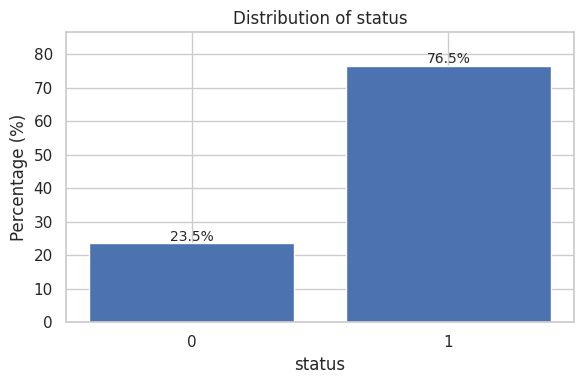

gender


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percentage (%)
gender,,
0,223,12.7000
1,1528,87.3000


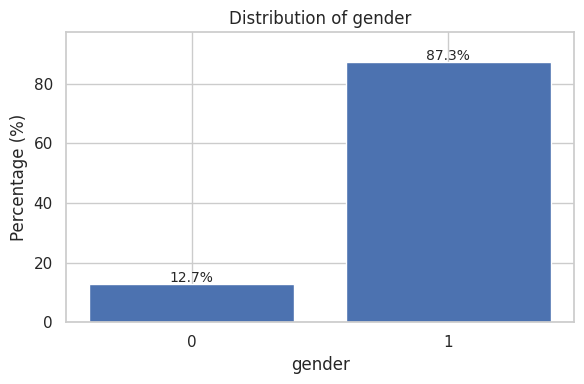

family_status


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percentage (%)
family_status,,
0,1119,63.9000
1,632,36.1000


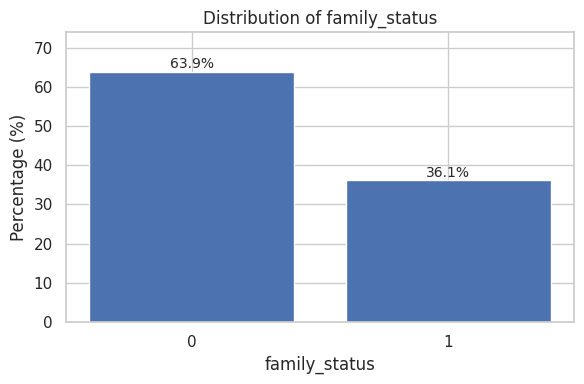

children


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percentage (%)
children,,
0,1344,76.8000
1,407,23.2000


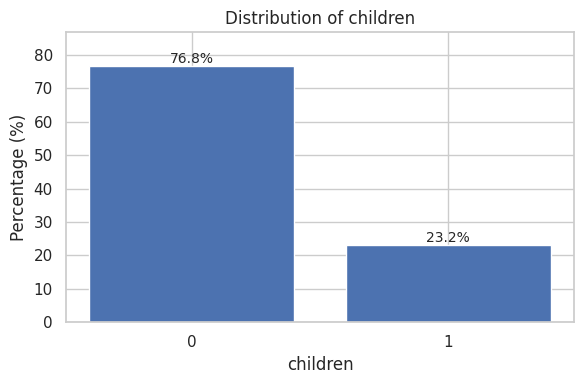

call_center


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percentage (%)
call_center,,
1,104,5.9000
2,94,5.4000
3,265,15.1000
4,288,16.4000
5,230,13.1000
6,233,13.3000
7,537,30.7000


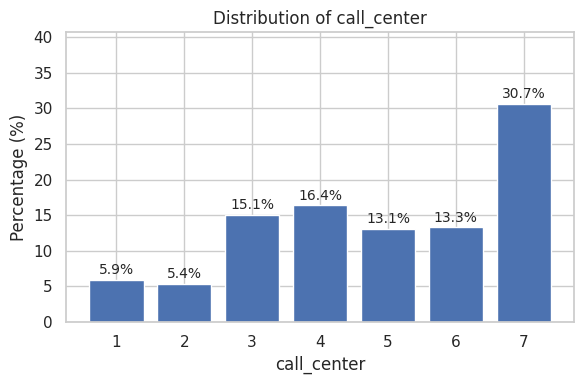

Team_size


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count,Percentage (%)
Team_size,,
1,253,14.4000
2,129,7.4000
3,472,27.0000
4,701,40.0000
5,196,11.2000


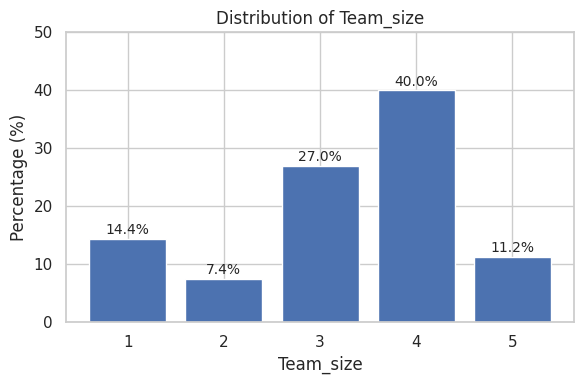

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# Distribution of categorical variables-5.3.2
# ============================================================

categorical_variables = [
    "status",
    "gender",
    "family_status",
    "children",
    "call_center",
    "Team_size"
]

for variable in categorical_variables:

    print("="*70)
    print(variable)
    print("="*70)

    plot_categorical_distribution(
        df_clean,
        variable
    )

### ממצאים עיקריים

מרבית העובדים במדגם עזבו במהלך תקופת המעקב, כאשר שיעור האירועים עמד על כ־76.5%.

המדגם כלל בעיקר נשים, ורוב העובדים היו לא נשואים וללא ילדים.

נמצא חוסר איזון בגודל המוקדים, כאשר מוקד 7 כלל את השיעור הגבוה ביותר של עובדים במדגם.

מבחינת גודל הצוות, הקטגוריה השכיחה ביותר הייתה קטגוריה 4, המייצגת צוותים של 20–25 נציגים.

## 5.4 Distribution of continuous variables

בחלק זה נבחנים המשתנים הרציפים באמצעות סטטיסטיקה תיאורית והתפלגויות.

המטרה היא:

- להכיר את טווחי הערכים.
- לזהות חריגים אפשריים.
- להעריך את צורת ההתפלגות.
- לוודא שערכי המשתנים סבירים לפני בניית מודל ההישרדות.

In [ ]:
# ============================================================
# 5.4.1 Descriptive Statistics
# ============================================================

continuous_variables = [
    "age",
    "time_in_company",
    "relative_salary",
    "bonus_avg",
    "part_time_percent"
]

descriptive_statistics = (
    df_clean[continuous_variables]
    .describe()
    .T[
        [
            "count",
            "mean",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max"
        ]
    ]
    .round(2)
)

descriptive_statistics["count"] = (
    descriptive_statistics["count"]
    .astype(int)
)

descriptive_statistics

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,mean,std,min,25%,50%,75%,max
age,1751,28.1100,5.5000,17.0000,24.0000,27.0000,31.0000,61.0000
time_in_company,1751,17.4300,21.7200,3.0000,6.0700,11.2000,21.0000,274.1300
relative_salary,1751,1.1100,0.1200,0.9400,1.0300,1.0900,1.1600,2.2200
bonus_avg,1751,653.2000,614.8500,0.0000,245.0600,541.3600,916.8400,"5,780.6300"
part_time_percent,1751,0.8700,0.2500,0.0300,0.7500,1.0000,1.0000,1.7700


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# Table 2 - Sample Characteristics
# Combines outputs from sections 5.1, 5.3 and 5.4.1
# ============================================================

table_rows = []

# ------------------------------------------------------------
# Categorical variables
# Uses the existing categorical_variables list from section 5.3
# ------------------------------------------------------------

for variable in categorical_variables:

    table_rows.append({
        "Variable": variable,
        "n (%) / Mean (SD)": "",
        "Median [Q1–Q3]": ""
    })

    counts = (
        df_clean[variable]
        .value_counts(dropna=False)
        .sort_index()
    )

    for category, n in counts.items():

        pct = n / len(df_clean) * 100

        table_rows.append({
            "Variable": f"   {category}",
            "n (%) / Mean (SD)": f"{n:,} ({pct:.1f}%)",
            "Median [Q1–Q3]": ""
        })


# ------------------------------------------------------------
# Continuous variables
# Uses the existing continuous_variables list from section 5.4.1
# ------------------------------------------------------------

for variable in continuous_variables:

    x = df_clean[variable].dropna()

    table_rows.append({
        "Variable": variable,
        "n (%) / Mean (SD)": (
            f"{x.mean():.2f} ({x.std():.2f})"
        ),
        "Median [Q1–Q3]": (
            f"{x.median():.2f} "
            f"[{x.quantile(0.25):.2f}–{x.quantile(0.75):.2f}]"
        )
    })


# ------------------------------------------------------------
# Create final publication table
# ------------------------------------------------------------

table_2 = pd.DataFrame(table_rows)

display(table_2)

,Variable,n (%) / Mean (SD),Median [Q1–Q3]
0,status,,
1,0,412 (23.5%),
2,1,"1,339 (76.5%)",
3,gender,,
4,0,223 (12.7%),
5,1,"1,528 (87.3%)",
6,family_status,,
7,0,"1,119 (63.9%)",
8,1,632 (36.1%),
9,children,,


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.4.2 Distribution plots for continuous variables
# ============================================================

def plot_continuous_distribution(df, column):

    data = df[column].dropna()

    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(7, 6),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    # Histogram
    axes[0].hist(
        data,
        bins=30,
        edgecolor="black"
    )

    axes[0].set_title(f"Distribution of {column}")
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Frequency")

    # Boxplot
    axes[1].boxplot(
        data,
        orientation="horizontal"
    )

    axes[1].set_xlabel(column)
    axes[1].set_yticks([])

    plt.tight_layout()
    plt.show()

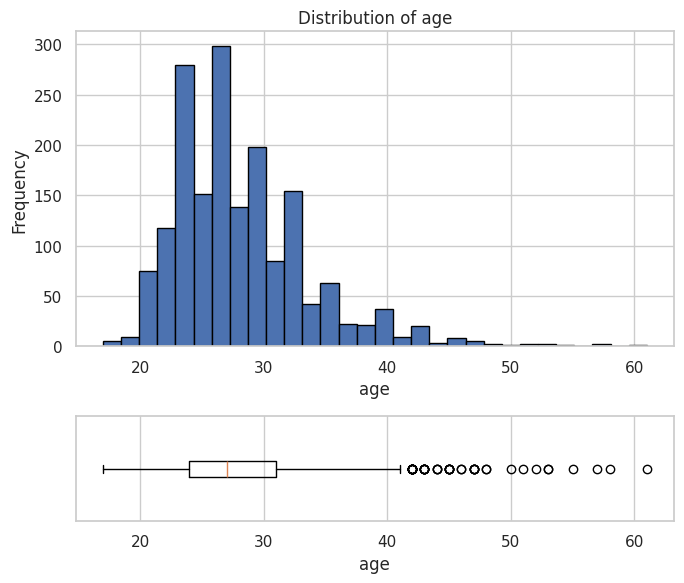

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


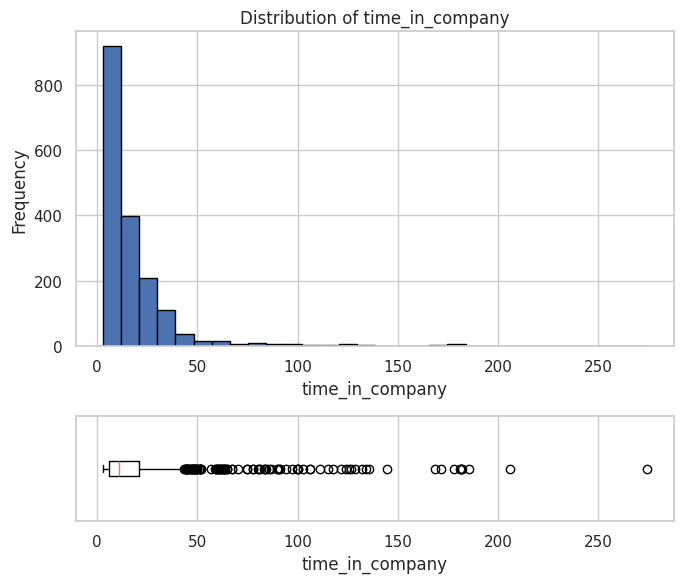

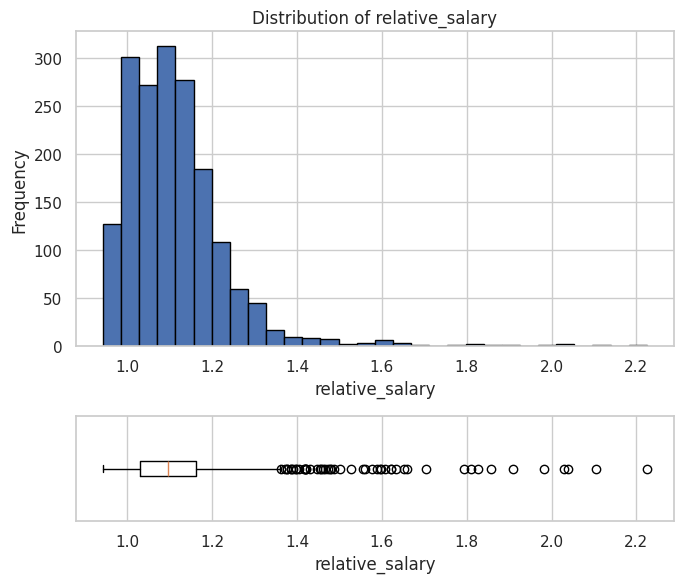

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


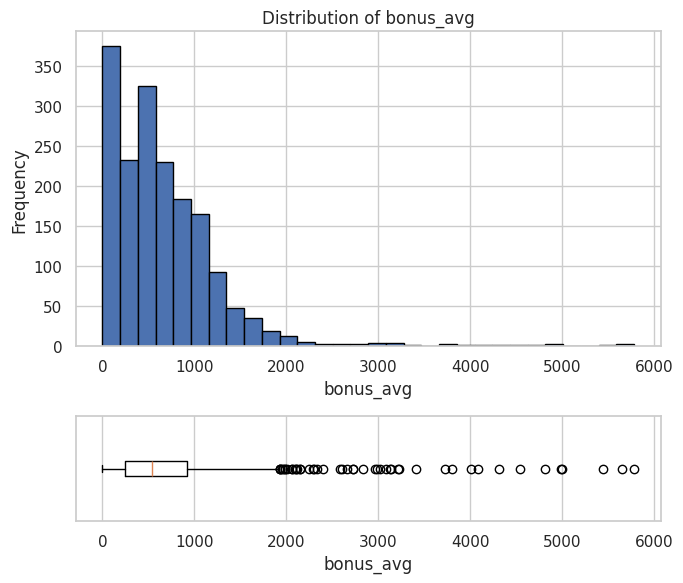

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# Run Continuous Distribution Plots
# ============================================================

continuous_plot_variables = [
    "age",
    "time_in_company",
    "relative_salary",
    "bonus_avg"
]

for variable in continuous_plot_variables:
    plot_continuous_distribution(
        df_clean,
        variable
    )

### ממצאים עיקריים

התפלגות הגיל הייתה מוטה מעט ימינה, כאשר רוב העובדים היו בשנות העשרים והשלושים המוקדמות לחייהם.

משך ההעסקה התאפיין בהתפלגות מוטה מאוד ימינה, כאשר מרבית העובדים היו בעלי ותק קצר יחסית, לצד מספר קטן של עובדים בעלי ותק ארוך במיוחד.

השכר השעתי התרכז בטווח צר יחסית, אך נצפו מספר ערכים גבוהים.

הבונוס החודשי הממוצע התאפיין בהתפלגות מוטה ימינה ובמספר ערכים חריגים גבוהים.

## 5.5 Kaplan–Meier survival curve

בחלק זה מוצגת עקומת ההישרדות מסוג Kaplan–Meier עבור כלל אוכלוסיית המחקר.

עקומת ההישרדות מתארת את ההסתברות שעובד ימשיך להיות מועסק בארגון לאורך זמן, תוך התחשבות בתצפיות מצונזרות.

הצגה זו מספקת תיאור ראשוני של דפוסי העזיבה באוכלוסיית המחקר לפני בניית מודל Cox Proportional Hazards.

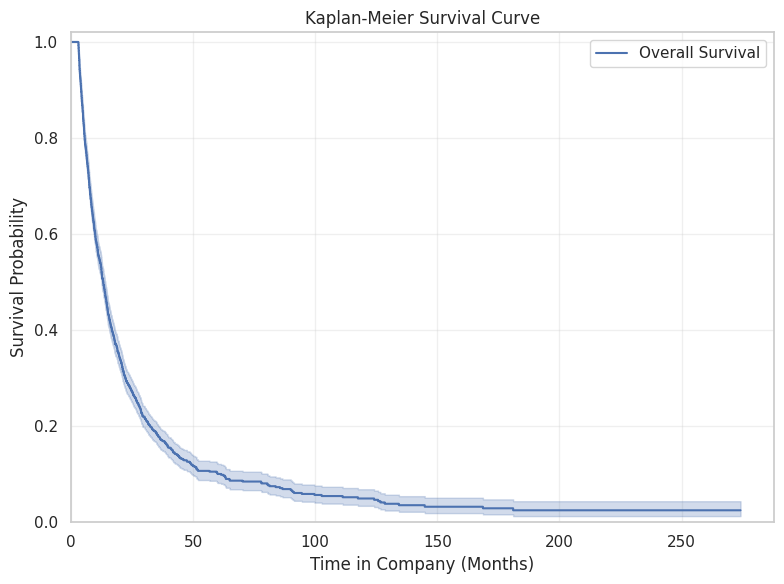

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.5 Kaplan-Meier survival curve
# ============================================================

from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()

kmf.fit(
    durations=df_clean[TIME_COL],
    event_observed=df_clean[EVENT_COL],
    label="Overall Survival"
)

plt.figure(figsize=(8,6))

kmf.plot_survival_function(
    ci_show=True,
    censor_styles={"marker": "|", "ms": 8}
)

plt.title("Kaplan-Meier Survival Curve")
plt.xlabel("Time in Company (Months)")
plt.ylabel("Survival Probability")

plt.xlim(left=0)
plt.ylim(0, 1.02)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### ממצאים עיקריים

עקומת Kaplan–Meier מצביעה על ירידה חדה בהסתברות ההישרדות במהלך החודשים הראשונים להעסקה, דבר המעיד כי מרבית העזיבות מתרחשות בשלבים מוקדמים של תקופת העבודה.

בהמשך תקופת המעקב קצב הירידה מתמתן, דבר המצביע על כך שעובדים שנותרו בארגון לאורך זמן נוטים להמשיך ולהישאר בו.

רצועות רווח הסמך מתרחבות בשלבים המאוחרים של המעקב, עקב ירידה במספר העובדים שנותרו במעקב לאורך זמן.

### 5.5.1 Survival probabilities at key time points

בנוסף לעקומת Kaplan–Meier, מוצגות הסתברויות ההישרדות בנקודות זמן מרכזיות (6, 12, 18 ו־24 חודשים), יחד עם רווחי סמך של 95%.

טבלה זו מאפשרת להציג בצורה מספרית את ההסתברות להישארות בארגון בנקודות זמן בעלות משמעות עסקית.

In [ ]:
# ============================================================
# 5.5.1 Kaplan-Meier survival at key time points
# ============================================================

report_times = [6, 12, 18, 24]

def km_ci_at_times(kmf_obj, times):

    sf = kmf_obj.survival_function_.iloc[:, 0]
    timeline = kmf_obj.survival_function_.index.values

    ci_df = getattr(
        kmf_obj,
        "confidence_interval_",
        None
    )

    if ci_df is None:
        ci_df = getattr(
            kmf_obj,
            "confidence_interval_survival_function_",
            None
        )

    lower_col = [c for c in ci_df.columns if "lower" in c][0]
    upper_col = [c for c in ci_df.columns if "upper" in c][0]

    rows = []

    for t in times:

        idx = np.searchsorted(
            timeline,
            t,
            side="right"
        ) - 1

        survival = float(sf.iloc[idx])

        lower = float(ci_df.iloc[idx][lower_col])
        upper = float(ci_df.iloc[idx][upper_col])

        rows.append({
            "Months": t,
            "Survival Probability": survival,
            "95% CI Lower": lower,
            "95% CI Upper": upper
        })

    return pd.DataFrame(rows)

km_table = (
    km_ci_at_times(kmf, report_times)
    .round(3)
)

km_table

,Months,Survival Probability,95% CI Lower,95% CI Upper
0,6,0.7800,0.7590,0.7990
1,12,0.5390,0.5150,0.5630
2,18,0.3740,0.3500,0.3980
3,24,0.2820,0.2590,0.3050


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
km_table_display = km_table.copy()

km_table_display["95% CI"] = (
    km_table_display["95% CI Lower"].map("{:.3f}".format)
    + " – " +
    km_table_display["95% CI Upper"].map("{:.3f}".format)
)

km_table_display = km_table_display[
    ["Months", "Survival Probability", "95% CI"]
]

km_table_display

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Months,Survival Probability,95% CI
0,6,0.7800,0.759 – 0.799
1,12,0.5390,0.515 – 0.563
2,18,0.3740,0.350 – 0.398
3,24,0.2820,0.259 – 0.305


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### ממצאים עיקריים

הסתברות ההישרדות של העובדים ירדה באופן ניכר במהלך תקופת המעקב.

לאחר שישה חודשי עבודה הסתברות ההישרדות עמדה על 78.0%, ולאחר שנה ירדה ל־53.9%.

לאחר שנתיים נותרה הסתברות הישרדות של 28.2% בלבד, דבר המעיד כי מרבית אירועי העזיבה התרחשו במהלך השנתיים הראשונות להעסקה.

### 5.5.2 Nelson–Aalen cumulative hazard

בנוסף לעקומת Kaplan–Meier חושב אומדן Nelson–Aalen, המציג את הסיכון המצטבר לעזיבה לאורך זמן.

בעוד שעקומת Kaplan–Meier מתארת את הסתברות ההישרדות, אומדן Nelson–Aalen מדגיש כיצד הסיכון המצטבר גדל במהלך תקופת המעקב.

/usr/local/lib/python3.12/dist-packages/lifelines/fitters/__init__.py:138: DeprecationWarning: The `plot` function is deprecated, and will be removed in future versions. Use `plot_cumulative_hazard_`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


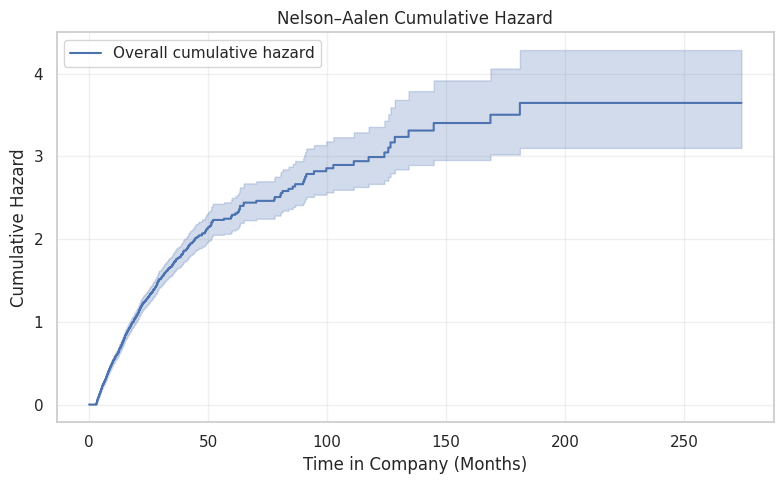

In [ ]:
# ============================================================
# 5.5.2 Nelson–Aalen cumulative hazard
# ============================================================

naf = NelsonAalenFitter()

naf.fit(
    durations=df_clean[TIME_COL],
    event_observed=df_clean[EVENT_COL],
    label="Overall cumulative hazard"
)

plt.figure(figsize=(8, 5))

naf.plot_cumulative_hazard(
    ci_show=True
)

plt.title("Nelson–Aalen Cumulative Hazard")
plt.xlabel("Time in Company (Months)")
plt.ylabel("Cumulative Hazard")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# חלק 5.6 – Kaplan–Meier Curves by Groups

### 5.6.1 עקומות Kaplan–Meier לפי גודל הצוות

אומד Kaplan–Meier משמש להשוואה תיאורית של הסתברות ההישרדות של העובדים בין קטגוריות שונות של גודל צוות.

המשתנה `Team_size` מסווג לחמש קטגוריות בהתאם למבנה הארגוני:

- 1 = עד 10 נציגים
- 2 = בין 10 ל־15 נציגים
- 3 = בין 15 ל־20 נציגים
- 4 = בין 20 ל־25 נציגים
- 5 = מעל 25 נציגים

מתחת לעקומות מוצגת טבלת Number at Risk, המציגה את מספר העובדים שנותרו במעקב בכל נקודת זמן.

בנוסף מבוצע מבחן Log-rank כולל, לבחינת ההשערה שהישרדות העובדים זהה בכל חמש קטגוריות גודל הצוות.

העקומות והמבחן מספקים השוואה חד־משתנית ראשונית לפני התאמת מודל Cox רב־משתני.

In [ ]:
# ============================================================
# 5.6.1 Helper function:
# Kaplan–Meier curves by categorical variable
# with Number at Risk and Global Log-rank Test
# ============================================================

from lifelines import KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import multivariate_logrank_test


def plot_kaplan_meier_by_group(
    df,
    group_column,
    group_labels,
    plot_title,
    legend_title,
    time_column=TIME_COL,
    event_column=EVENT_COL
):
    """
    Plot Kaplan–Meier survival curves by a categorical variable,
    add a Number at Risk table, and perform a global Log-rank test.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset used for the analysis.

    group_column : str
        Name of the categorical grouping variable.

    group_labels : dict
        Mapping between coded values and labels shown in the plot.

    plot_title : str
        English title shown above the plot.

    legend_title : str
        English title shown in the legend.

    time_column : str
        Survival-time variable.

    event_column : str
        Event-indicator variable, where 1 = event and 0 = censored.
    """

    # --------------------------------------------------------
    # Prepare analysis dataset
    # --------------------------------------------------------

    required_columns = [
        time_column,
        event_column,
        group_column
    ]

    analysis_data = (
        df[required_columns]
        .dropna()
        .copy()
    )

    analysis_data[event_column] = (
        analysis_data[event_column]
        .astype(int)
    )

    # Convert category values to their underlying numeric values
    # when possible, without modifying df_clean.
    try:
        analysis_data[group_column] = (
            analysis_data[group_column]
            .astype(int)
        )
    except (TypeError, ValueError):
        analysis_data[group_column] = (
            analysis_data[group_column]
            .astype(str)
        )

    observed_groups = sorted(
        analysis_data[group_column]
        .dropna()
        .unique()
        .tolist()
    )

    if len(observed_groups) < 2:
        raise ValueError(
            f"{group_column} must contain at least two groups."
        )

    # --------------------------------------------------------
    # Global Log-rank test
    # --------------------------------------------------------

    logrank_result = multivariate_logrank_test(
        event_durations=analysis_data[time_column],
        groups=analysis_data[group_column],
        event_observed=analysis_data[event_column]
    )

    test_statistic = float(
        logrank_result.test_statistic
    )

    p_value = float(
        logrank_result.p_value
    )

    degrees_of_freedom = len(observed_groups) - 1

    # --------------------------------------------------------
    # Kaplan–Meier curves
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    fitted_models = []

    for group_value in observed_groups:

        group_mask = (
            analysis_data[group_column]
            == group_value
        )

        group_size = int(
            group_mask.sum()
        )

        readable_label = group_labels.get(
            group_value,
            str(group_value)
        )

        curve_label = (
            f"{group_value} ({readable_label}), "
            f"n={group_size}"
        )

        kmf_group = KaplanMeierFitter()

        kmf_group.fit(
            durations=analysis_data.loc[
                group_mask,
                time_column
            ],
            event_observed=analysis_data.loc[
                group_mask,
                event_column
            ],
            label=curve_label
        )

        kmf_group.plot_survival_function(
            ax=ax,
            ci_show=False,
            show_censors=True,
            censor_styles={
                "marker": "|",
                "ms": 5
            }
        )

        fitted_models.append(kmf_group)

    # --------------------------------------------------------
    # Plot formatting
    # --------------------------------------------------------

    ax.set_title(plot_title)
    ax.set_xlabel("Time in Company (Months)")
    ax.set_ylabel("Survival Probability")

    ax.set_xlim(left=0)
    ax.set_ylim(0, 1.02)

    ax.grid(alpha=0.3)

    ax.legend(
        title=legend_title,
        loc="best",
        fontsize=9
    )

    # Display Log-rank p-value inside the graph
    if p_value < 0.001:
        p_text = "Log-rank p < 0.001"
    else:
        p_text = f"Log-rank p = {p_value:.3f}"

    ax.text(
        0.98,
        0.05,
        p_text,
        transform=ax.transAxes,
        horizontalalignment="right",
        verticalalignment="bottom",
        bbox={
            "boxstyle": "round",
            "facecolor": "white",
            "alpha": 0.8
        }
    )

    # --------------------------------------------------------
    # Number at Risk table
    # --------------------------------------------------------

    add_at_risk_counts(
        *fitted_models,
        ax=ax,
        rows_to_show=["At risk"],
        ypos=-0.30
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Summary table
    # --------------------------------------------------------

    logrank_summary = pd.DataFrame({
        "Test": [
            "Global Log-rank test"
        ],
        "Grouping Variable": [
            group_column
        ],
        "Number of Groups": [
            len(observed_groups)
        ],
        "Test Statistic": [
            round(test_statistic, 4)
        ],
        "Degrees of Freedom": [
            degrees_of_freedom
        ],
        "P-value": [
            round(p_value, 4)
        ],
        "Number of Observations": [
            len(analysis_data)
        ]
    })

    display(logrank_summary)

    return {
        "analysis_data": analysis_data,
        "fitters": fitted_models,
        "logrank_result": logrank_result,
        "summary": logrank_summary
    }

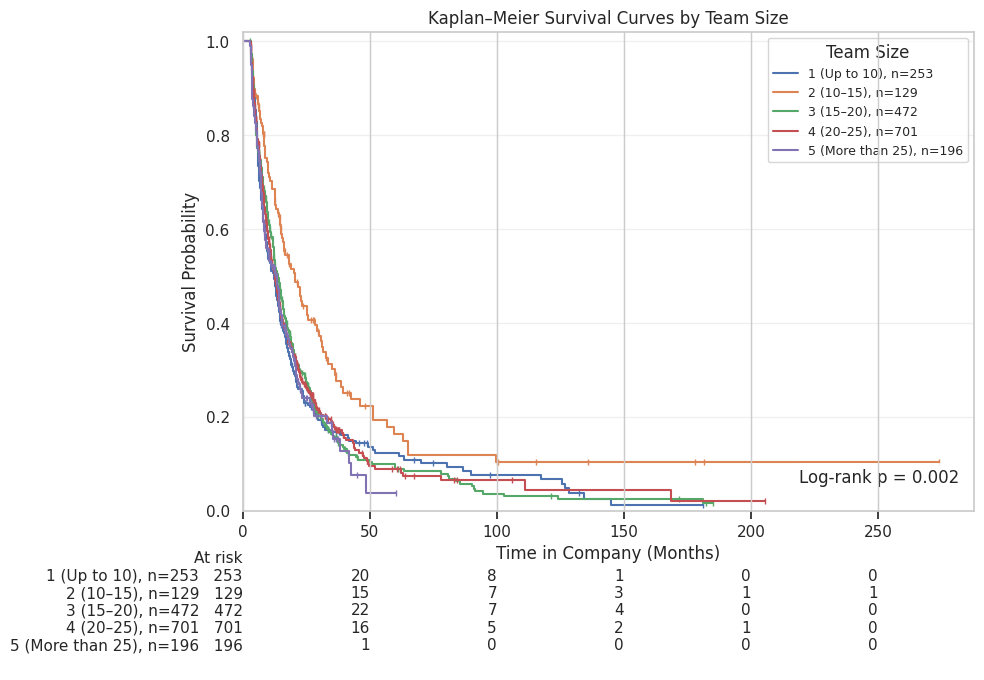

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Test,Grouping Variable,Number of Groups,Test Statistic,Degrees of Freedom,P-value,Number of Observations
0,Global Log-rank test,Team_size,5,16.9660,4,0.0020,1751


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.6.2 Kaplan–Meier Survival Curves by Team Size
# ============================================================

TEAM_SIZE_LABELS = {
    1: "Up to 10",
    2: "10–15",
    3: "15–20",
    4: "20–25",
    5: "More than 25"
}

team_size_km_results = plot_kaplan_meier_by_group(
    df=df_clean,
    group_column="Team_size",
    group_labels=TEAM_SIZE_LABELS,
    plot_title="Kaplan–Meier Survival Curves by Team Size",
    legend_title="Team Size"
)

### ממצאים עיקריים

עקומות Kaplan–Meier מצביעות על הבדלים בהסתברות ההישרדות בין קטגוריות שונות של גודל צוות.

מבחן Log-rank הכולל הצביע על הבדל מובהק סטטיסטית בין עקומות ההישרדות של חמש הקבוצות (`χ² = 16.97`, `df = 4`, `p = 0.002`). מכאן שקיימת עדות לכך שמשך ההישארות בארגון אינו זהה בכל קטגוריות גודל הצוות.

עם זאת, המבחן הכולל מצביע רק על כך שלפחות שתי קבוצות שונות זו מזו, ואינו מזהה אילו קבוצות אחראיות להבדל. בנוסף, יש לפרש בזהירות את החלקים המאוחרים של העקומות, שבהם מספר העובדים שנותרו בסיכון קטן מאוד.

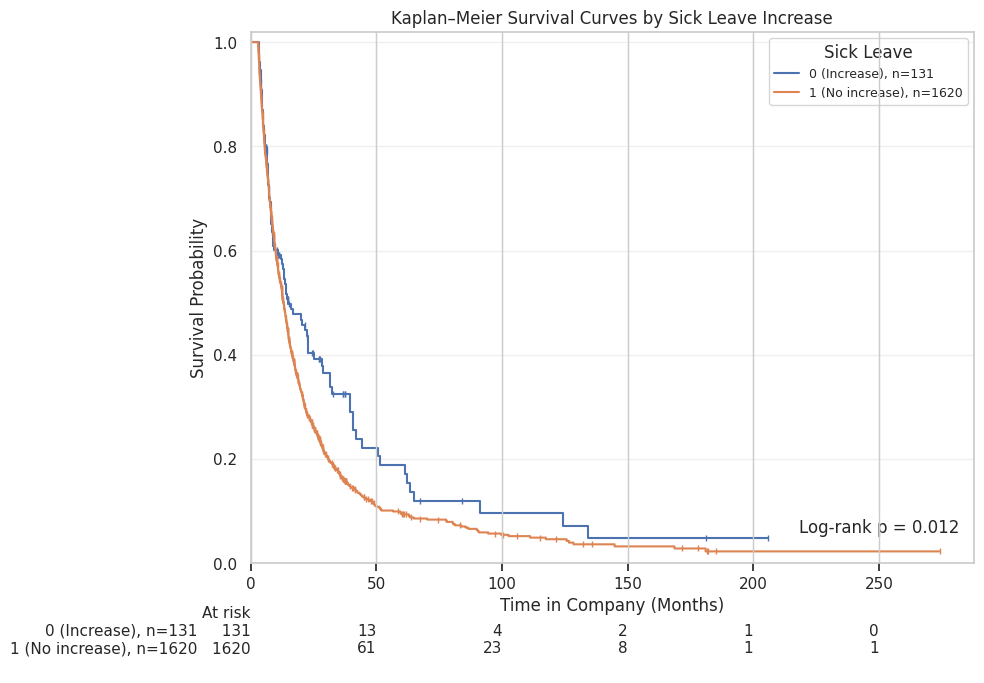

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Test,Grouping Variable,Number of Groups,Test Statistic,Degrees of Freedom,P-value,Number of Observations
0,Global Log-rank test,avg_annual_sick_increase,2,6.3229,1,0.0119,1751


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.6.3 Kaplan–Meier Survival Curves by Sick Leave Increase
# ============================================================

SICK_LEAVE_LABELS = {
    0: "Increase",
    1: "No increase"
}

sick_leave_km_results = plot_kaplan_meier_by_group(
    df=df_clean,
    group_column="avg_annual_sick_increase",
    group_labels=SICK_LEAVE_LABELS,
    plot_title="Kaplan–Meier Survival Curves by Sick Leave Increase",
    legend_title="Sick Leave"
)

### ממצאים עיקריים

עקומות Kaplan–Meier הראו הבדל בהסתברות ההישרדות בין עובדים שחלה אצלם עלייה בניצול ימי מחלה בשלושת החודשים האחרונים לבין עובדים שלא חלה אצלם עלייה.

מבחן **Global Log-rank** הצביע על הבדל מובהק סטטיסטית בין שתי עקומות ההישרדות (`χ² = 6.32`, `df = 1`, `p = 0.012`), דבר המעיד כי הסתברות ההישארות בארגון שונה בין שתי הקבוצות.

עם זאת, מדובר בניתוח חד-משתני בלבד, ולכן לא ניתן להסיק כי העלייה בניצול ימי המחלה מהווה גורם עצמאי לעזיבה. השפעת המשתנה תיבחן בהמשך במסגרת מודל Cox הרב-משתני.

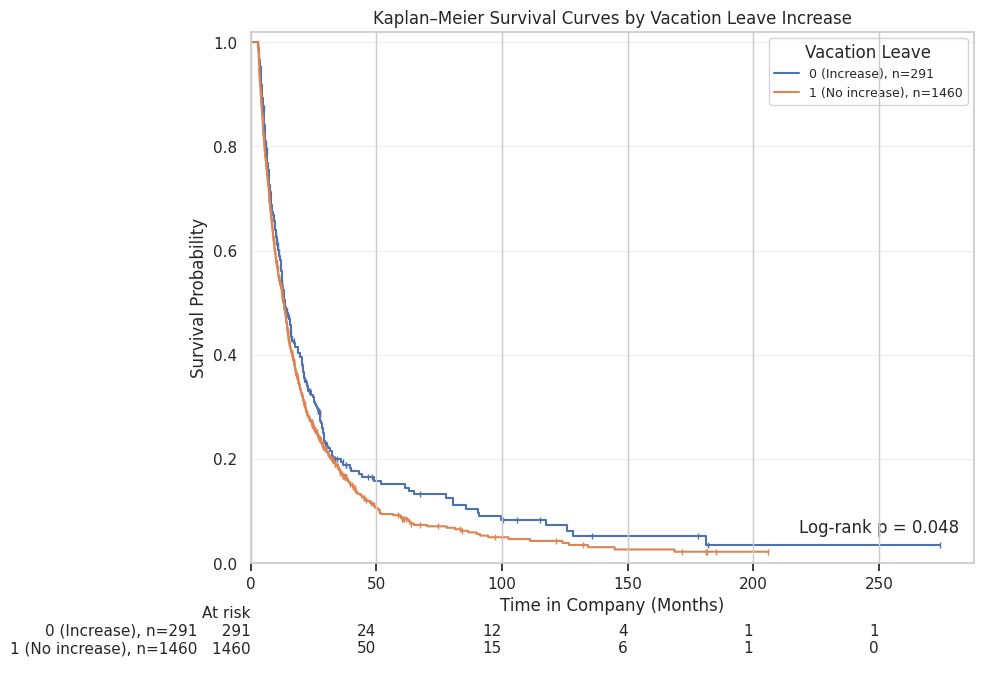

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Test,Grouping Variable,Number of Groups,Test Statistic,Degrees of Freedom,P-value,Number of Observations
0,Global Log-rank test,avg_annual_vacation_increase,2,3.8980,1,0.0483,1751


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.6.4 Kaplan–Meier Survival Curves by Vacation Leave Increase
# ============================================================

VACATION_LABELS = {
    0: "Increase",
    1: "No increase"
}

vacation_km_results = plot_kaplan_meier_by_group(
    df=df_clean,
    group_column="avg_annual_vacation_increase",
    group_labels=VACATION_LABELS,
    plot_title="Kaplan–Meier Survival Curves by Vacation Leave Increase",
    legend_title="Vacation Leave"
)

### ממצאים עיקריים

עקומות Kaplan–Meier הראו הבדל בהסתברות ההישרדות בין עובדים שחלה אצלם עלייה בניצול ימי חופשה בשלושת החודשים האחרונים לבין עובדים שלא חלה אצלם עלייה.

מבחן **Global Log-rank** הצביע על הבדל מובהק סטטיסטית בין שתי עקומות ההישרדות (`χ² = 3.90`, `df = 1`, `p = 0.048`), דבר המעיד כי הסתברות ההישארות בארגון שונה בין שתי הקבוצות.

עם זאת, מדובר בניתוח חד-משתני בלבד, ולכן לא ניתן להסיק כי העלייה בניצול ימי החופשה מהווה גורם עצמאי לעזיבה. השפעת המשתנה תיבחן בהמשך במסגרת מודל Cox הרב-משתני.

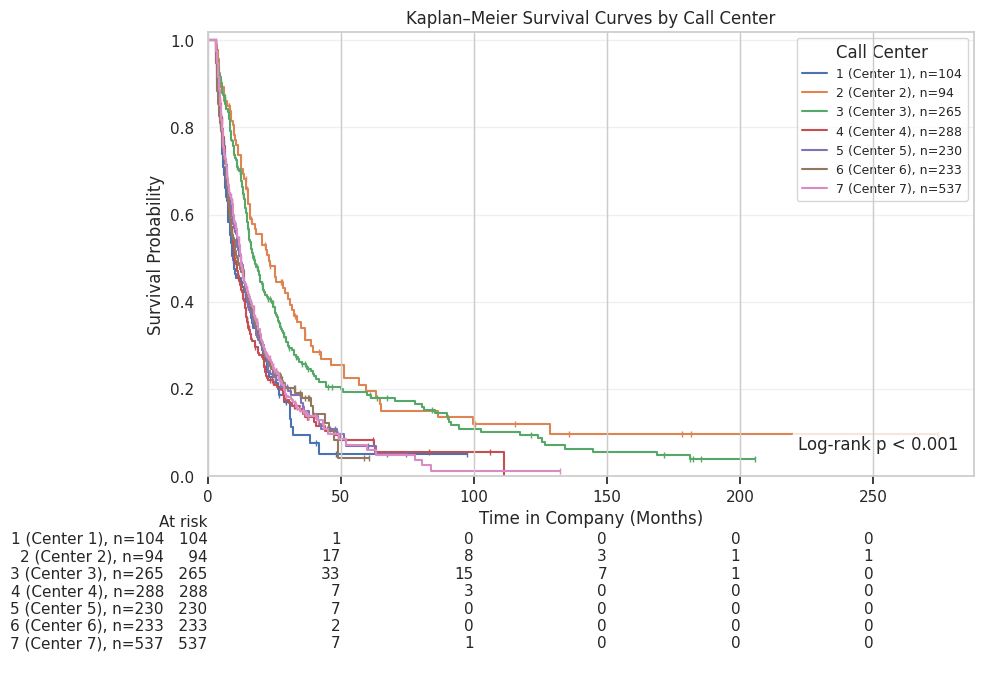

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Test,Grouping Variable,Number of Groups,Test Statistic,Degrees of Freedom,P-value,Number of Observations
0,Global Log-rank test,call_center,7,57.3611,6,0.0000,1751


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.6.5 Kaplan–Meier Survival Curves by Call Center
# ============================================================

CALL_CENTER_LABELS = {
    1: "Center 1",
    2: "Center 2",
    3: "Center 3",
    4: "Center 4",
    5: "Center 5",
    6: "Center 6",
    7: "Center 7"
}

call_center_km_results = plot_kaplan_meier_by_group(
    df=df_clean,
    group_column="call_center",
    group_labels=CALL_CENTER_LABELS,
    plot_title="Kaplan–Meier Survival Curves by Call Center",
    legend_title="Call Center"
)

### ממצאים עיקריים

עקומות Kaplan–Meier הראו הבדלים ברורים בהסתברות ההישרדות בין שבעת המוקדים שנכללו במחקר.

מבחן **Global Log-rank** הצביע על הבדל מובהק סטטיסטית בין עקומות ההישרדות של המוקדים (`χ² = 57.36`, `df = 6`, `p < 0.001`), דבר המעיד כי הסתברות ההישארות בארגון אינה זהה בין המוקדים.

מהגרף ניתן לראות כי קיימת שונות ניכרת בין המוקדים לאורך תקופת המעקב, כאשר חלק מהמוקדים מציגים הסתברות הישרדות גבוהה יותר לאורך זמן בהשוואה לאחרים.

עם זאת, מדובר בניתוח חד-משתני בלבד, ולכן לא ניתן להסיק כי ההבדלים נובעים מהמוקד עצמו. ייתכן שהבדלים אלה מושפעים ממאפייני העובדים, תנאי העבודה או גורמים נוספים. השפעת המשתנה תיבחן בהמשך במסגרת מודל Cox הרב-משתני.

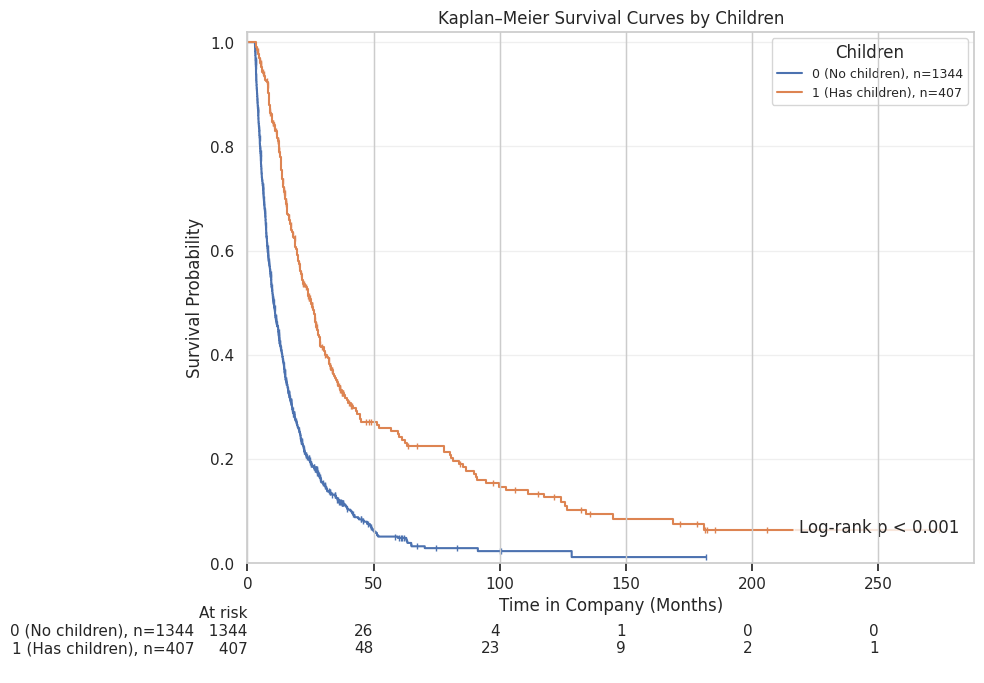

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Test,Grouping Variable,Number of Groups,Test Statistic,Degrees of Freedom,P-value,Number of Observations
0,Global Log-rank test,children,2,164.9773,1,0.0000,1751


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.6.6 Kaplan–Meier Survival Curves by Children
# ============================================================

CHILDREN_LABELS = {
    0: "No children",
    1: "Has children"
}

children_km_results = plot_kaplan_meier_by_group(
    df=df_clean,
    group_column="children",
    group_labels=CHILDREN_LABELS,
    plot_title="Kaplan–Meier Survival Curves by Children",
    legend_title="Children"
)

### ממצאים עיקריים

עקומות Kaplan–Meier הראו הבדל ברור בהסתברות ההישרדות בין עובדים שלהם ילדים לבין עובדים ללא ילדים.

מבחן **Global Log-rank** הצביע על הבדל מובהק סטטיסטית בין שתי עקומות ההישרדות (`χ² = 164.98`, `df = 1`, `p < 0.001`), דבר המעיד כי הסתברות ההישארות בארגון שונה באופן משמעותי בין שתי הקבוצות.

מהגרף ניתן לראות כי עובדים שלהם ילדים הציגו הסתברות הישרדות גבוהה יותר לאורך כל תקופת המעקב בהשוואה לעובדים ללא ילדים.

עם זאת, מדובר בניתוח חד-משתני בלבד, ולכן לא ניתן להסיק כי עצם קיומם של ילדים מהווה גורם עצמאי להישארות בארגון. ייתכן שהבדל זה מושפע גם מגורמים נוספים, כגון גיל, מצב משפחתי, שכר או מאפייני תעסוקה אחרים. השפעת המשתנה תיבחן בהמשך במסגרת מודל Cox הרב-משתני.

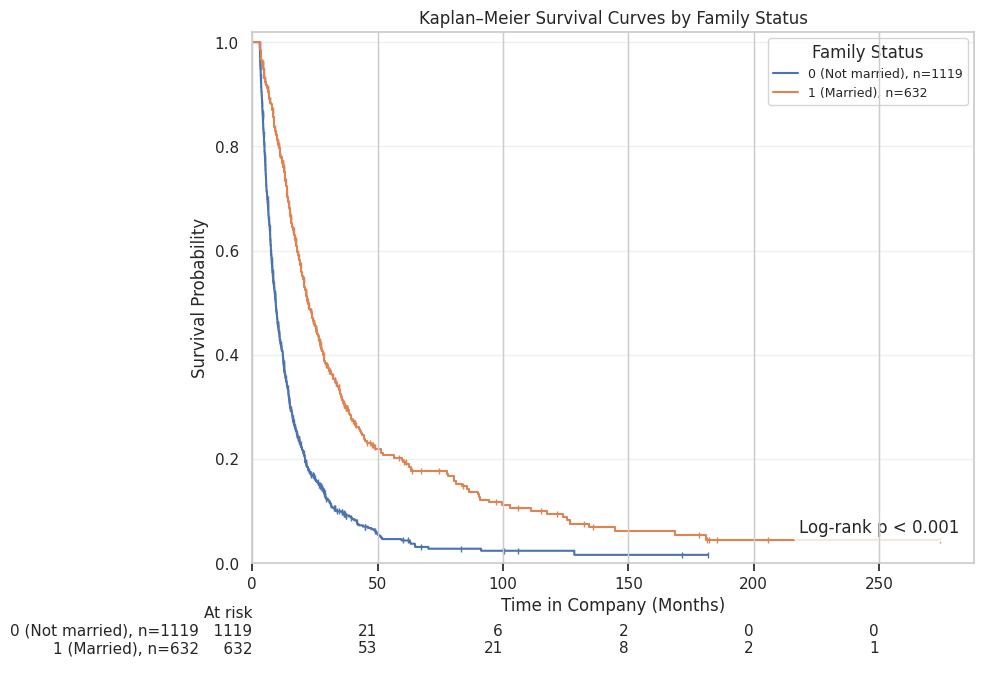

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Test,Grouping Variable,Number of Groups,Test Statistic,Degrees of Freedom,P-value,Number of Observations
0,Global Log-rank test,family_status,2,221.3184,1,0.0000,1751


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.6.7 Kaplan–Meier Survival Curves by Family Status
# ============================================================

FAMILY_STATUS_LABELS = {
    0: "Not married",
    1: "Married"
}

family_status_km_results = plot_kaplan_meier_by_group(
    df=df_clean,
    group_column="family_status",
    group_labels=FAMILY_STATUS_LABELS,
    plot_title="Kaplan–Meier Survival Curves by Family Status",
    legend_title="Family Status"
)

### ממצאים עיקריים

עקומות Kaplan–Meier הראו הבדל ברור בהסתברות ההישרדות בין עובדים נשואים לבין עובדים שאינם נשואים.

מבחן **Global Log-rank** הצביע על הבדל מובהק סטטיסטית בין שתי עקומות ההישרדות (`χ² = 221.32`, `df = 1`, `p < 0.001`), דבר המעיד כי הסתברות ההישארות בארגון שונה באופן משמעותי בין שתי הקבוצות.

מהגרף ניתן לראות כי עובדים נשואים הציגו הסתברות הישרדות גבוהה יותר לאורך כל תקופת המעקב בהשוואה לעובדים שאינם נשואים.

עם זאת, מדובר בניתוח חד-משתני בלבד, ולכן לא ניתן להסיק כי המצב המשפחתי מהווה גורם עצמאי להישארות בארגון. ייתכן שהבדל זה מושפע גם מגורמים נוספים, כגון גיל, קיומם של ילדים, שכר או מאפייני תעסוקה אחרים. השפעת המשתנה תיבחן בהמשך במסגרת מודל Cox הרב-משתני.

| משתנה            |         χ² |
| ---------------- | ---------: |
| מצב משפחתי       | **221.32** |
| ילדים            | **164.98** |
| מוקד             |      57.36 |
| גודל צוות        |      16.97 |
| עלייה בימי מחלה  |       6.32 |
| עלייה בימי חופשה |       3.90 |


# פרק 5.7 – Correlation and Multicollinearity Assessment  
המטרה של הפרק היא:

לזהות משתנים שמתארים כמעט את אותו המידע.  
למנוע בעיות במודל Cox.  
להבין מראש אילו משתנים עלולים "להתחרות" ביניהם.  


# 5.7.1 Correlation Matrix


בשלב זה נבדקו המתאמים בין המשתנים הכמותיים באמצעות מקדם המתאם של Pearson.

מטרת הניתוח הייתה לזהות משתנים בעלי מתאם גבוה, העלולים להעיד על Multicollinearity לפני בניית מודל Cox הרב-משתני.

המתאמים מוצגים באמצעות Heatmap.

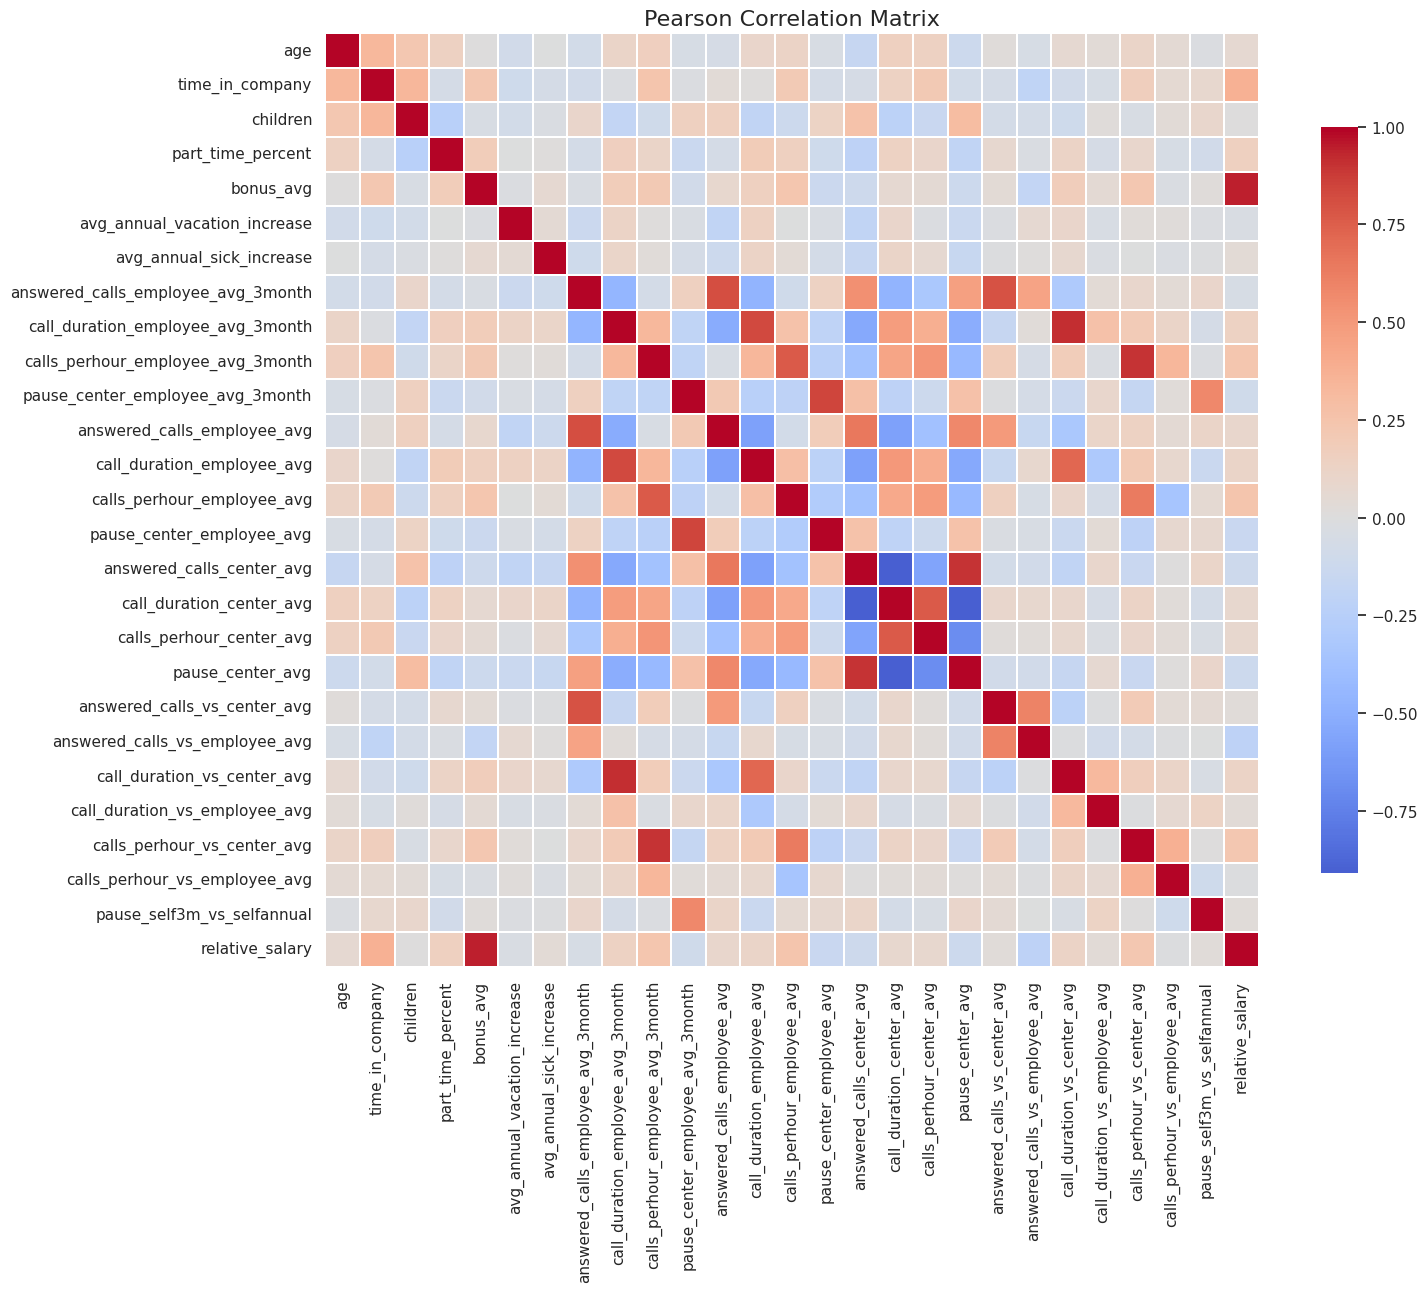

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.7.1 Correlation Matrix
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Numeric variables only
numeric_df = df_clean.select_dtypes(include=["number"]).copy()

# Correlation matrix
corr_matrix = numeric_df.corr(method="pearson")

plt.figure(figsize=(16, 13))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink":0.8}
)

plt.title("Pearson Correlation Matrix", fontsize=16)
plt.tight_layout()
plt.show()

# 5.7.2 High Correlation Pairs


לאחר הצגת מטריצת המתאמים, זוהו זוגות משתנים בעלי מתאם גבוה.

לצורך המחקר הוגדר כי מתאם מוחלט של |r| ≥ 0.70 ייחשב כמתאם גבוה העלול להעיד על Multicollinearity.

טבלה זו משמשת לזיהוי משתנים שעשויים לדרוש בחינה נוספת לפני בניית מודל Cox הרב-משתני.

In [ ]:
# ============================================================
# 5.7.2 High Correlation Pairs
# ============================================================

import numpy as np

threshold = 0.70

corr = corr_matrix.copy()

# keep only upper triangle
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

high_corr = (
    upper.stack()
         .reset_index()
         .rename(columns={
             "level_0": "Variable 1",
             "level_1": "Variable 2",
             0: "Correlation"
         })
)

high_corr = high_corr[
    high_corr["Correlation"].abs() >= threshold
]

high_corr = high_corr.reindex(
    high_corr["Correlation"].abs().sort_values(ascending=False).index
)

display(high_corr.reset_index(drop=True))

,Variable 1,Variable 2,Correlation
0,bonus_avg,relative_salary,0.9456
1,call_duration_employee_avg_3month,call_duration_vs_center_avg,0.9151
2,answered_calls_center_avg,call_duration_center_avg,-0.9098
3,call_duration_center_avg,pause_center_avg,-0.9055
4,calls_perhour_employee_avg_3month,calls_perhour_vs_center_avg,0.9018
5,answered_calls_center_avg,pause_center_avg,0.9011
6,pause_center_employee_avg_3month,pause_center_employee_avg,0.8481
7,call_duration_employee_avg_3month,call_duration_employee_avg,0.8358
8,answered_calls_employee_avg_3month,answered_calls_employee_avg,0.8176
9,answered_calls_employee_avg_3month,answered_calls_vs_center_avg,0.7978


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### ממצאים עיקריים

נמצאו מספר זוגות משתנים בעלי מתאם גבוה (|r| ≥ 0.70).

מרבית המתאמים הגבוהים הופיעו בין מדדי ביצוע המתארים את אותו KPI בתקופות זמן שונות (לדוגמה, ממוצע שנתי לעומת ממוצע של שלושת החודשים האחרונים), או בין מדדי ביצוע לבין המדדים היחסיים המחושבים מהם.

דפוס זה היה צפוי לאור אופן בניית המשתנים ואינו מעיד בהכרח על כפילות שגויה בנתונים.

עם זאת, קיומם של מתאמים גבוהים מחייב בדיקה נוספת של Multicollinearity לפני בניית מודל Cox הרב-משתני. לצורך כך יחושב בהמשך Variance Inflation Factor (VIF).

### 5.7.3 קשר בין משתנים קטגוריאליים באמצעות Cramér's V

לאחר בדיקת המתאמים בין המשתנים הכמותיים, נבדק הקשר בין המשתנים הקטגוריאליים באמצעות מדד Cramér's V.

המדד נע בין 0 ל־1:

- ערך הקרוב ל־0 מצביע על קשר חלש או היעדר קשר.
- ערך הקרוב ל־1 מצביע על קשר חזק בין המשתנים.

בדיקה זו חשובה במיוחד לזיהוי קשר אפשרי בין משתנים כגון מצב משפחתי וקיומם של ילדים, וכן בין מוקד וגודל צוות, לפני התאמת מודל Cox הרב־משתני.

In [ ]:
# ============================================================
# 5.7.3 Association Between Categorical Variables
# Using Bias-Corrected Cramér's V
# ============================================================

from itertools import combinations

from scipy.stats import chi2_contingency


def cramers_v_bias_corrected(x, y):
    """
    Calculate bias-corrected Cramér's V for two categorical variables.

    Parameters
    ----------
    x, y : pandas.Series
        Two categorical or discrete variables.

    Returns
    -------
    float
        Bias-corrected Cramér's V.
    """

    valid_data = pd.DataFrame({
        "x": x,
        "y": y
    }).dropna()

    contingency_table = pd.crosstab(
        valid_data["x"],
        valid_data["y"]
    )

    if contingency_table.shape[0] < 2 or contingency_table.shape[1] < 2:
        return np.nan

    chi2, _, _, _ = chi2_contingency(
        contingency_table,
        correction=False
    )

    n = contingency_table.to_numpy().sum()

    if n <= 1:
        return np.nan

    phi2 = chi2 / n
    rows, columns = contingency_table.shape

    # Bias correction
    phi2_corrected = max(
        0,
        phi2 - ((columns - 1) * (rows - 1)) / (n - 1)
    )

    rows_corrected = rows - ((rows - 1) ** 2) / (n - 1)
    columns_corrected = columns - ((columns - 1) ** 2) / (n - 1)

    denominator = min(
        columns_corrected - 1,
        rows_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )


# ------------------------------------------------------------
# Variables treated as categorical for this assessment
# ------------------------------------------------------------

categorical_association_variables = [
    "gender",
    "children",
    "family_status",
    "call_center",
    "Team_size",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase"
]

# Verify that all required variables exist
missing_categorical_variables = [
    variable
    for variable in categorical_association_variables
    if variable not in df_clean.columns
]

assert not missing_categorical_variables, (
    "Missing categorical variables: "
    f"{missing_categorical_variables}"
)

# ------------------------------------------------------------
# Calculate all pairwise Cramér's V values
# ------------------------------------------------------------

cramers_v_rows = []

for variable_1, variable_2 in combinations(
    categorical_association_variables,
    2
):
    valid_pair = df_clean[
        [variable_1, variable_2]
    ].dropna()

    cramers_v_value = cramers_v_bias_corrected(
        valid_pair[variable_1],
        valid_pair[variable_2]
    )

    cramers_v_rows.append({
        "Variable 1": variable_1,
        "Variable 2": variable_2,
        "Cramér's V": cramers_v_value,
        "Valid Observations": len(valid_pair)
    })

cramers_v_pairs = pd.DataFrame(
    cramers_v_rows
)

cramers_v_pairs = (
    cramers_v_pairs
    .sort_values(
        "Cramér's V",
        ascending=False
    )
    .reset_index(drop=True)
)

cramers_v_pairs["Cramér's V"] = (
    cramers_v_pairs["Cramér's V"]
    .round(4)
)

display(cramers_v_pairs)

,Variable 1,Variable 2,Cramér's V,Valid Observations
0,children,family_status,0.6616,1751
1,call_center,Team_size,0.6018,1751
2,children,call_center,0.4664,1751
3,family_status,call_center,0.3846,1751
4,gender,call_center,0.3169,1751
5,call_center,avg_annual_vacation_increase,0.2850,1751
6,gender,family_status,0.2181,1751
7,children,Team_size,0.1888,1751
8,call_center,avg_annual_sick_increase,0.1783,1751
9,gender,Team_size,0.1764,1751


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


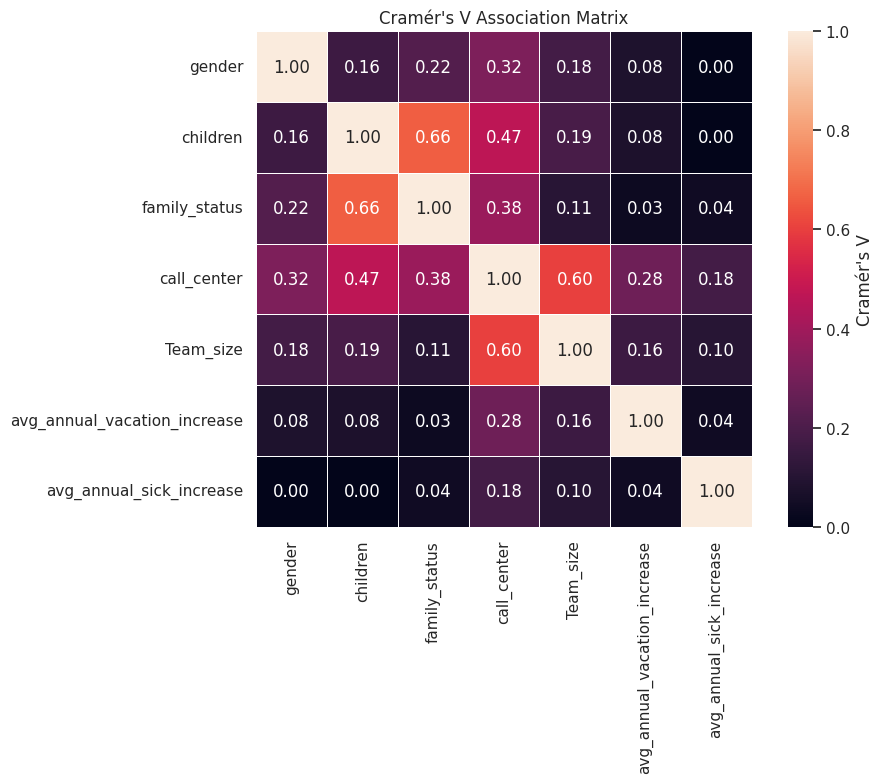

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 5.7.3.1 Cramér's V Association Matrix
# ============================================================

cramers_v_matrix = pd.DataFrame(
    np.eye(len(categorical_association_variables)),
    index=categorical_association_variables,
    columns=categorical_association_variables
)

for _, row in cramers_v_pairs.iterrows():

    variable_1 = row["Variable 1"]
    variable_2 = row["Variable 2"]
    association = row["Cramér's V"]

    cramers_v_matrix.loc[
        variable_1,
        variable_2
    ] = association

    cramers_v_matrix.loc[
        variable_2,
        variable_1
    ] = association

plt.figure(figsize=(10, 8))

sns.heatmap(
    cramers_v_matrix,
    annot=True,
    fmt=".2f",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.4,
    cbar_kws={
        "label": "Cramér's V"
    }
)

plt.title(
    "Cramér's V Association Matrix"
)

plt.tight_layout()
plt.show()

### ממצאים עיקריים

בדיקת הקשר בין המשתנים הקטגוריאליים באמצעות Cramér's V הצביעה על מספר קשרים בינוניים עד חזקים בין חלק מהמשתנים.

הקשר החזק ביותר נמצא בין **מצב משפחתי** לבין **קיומם של ילדים** (Cramér's V = 0.66), דבר התואם את הציפייה כי עובדים נשואים נוטים יותר להיות הורים.

בנוסף, נמצא קשר בינוני בין **מוקד** לבין **גודל הצוות** (Cramér's V = 0.60), המעיד כי גודל הצוות משתנה בין מוקדי השירות השונים.

יתר הקשרים שנמצאו היו חלשים עד בינוניים (Cramér's V < 0.50), ולכן אינם מצביעים על תלות חזקה בין המשתנים.

ממצאים אלו מצביעים על כך שקיימים מספר קשרים בין משתנים קטגוריאליים, אך הם אינם מעידים בהכרח על בעיית Multicollinearity. נושא זה ייבחן באופן ישיר באמצעות Variance Inflation Factor (VIF) לפני התאמת מודל Cox הרב-משתני.


# 5.7.4 Variance Inflation Factor (VIF)

לאחר בחינת המתאמים בין המשתנים, נבדקה Multicollinearity באמצעות Variance Inflation Factor (VIF).

הבדיקה בוצעה על משתני המודל בלבד, במטרה לזהות משתנים המספקים מידע חופף העלול לגרום לחוסר יציבות באמידת מקדמי מודל Cox.

ככלל:

- VIF < 2 מעיד על היעדר Multicollinearity משמעותית.
- VIF בין 2 ל־5 נחשב מקובל.
- VIF > 5 עשוי להעיד על תלות גבוהה בין משתנים.

In [ ]:
# ============================================================
# 5.7.4 Preliminary Variance Inflation Factor (VIF)
# for Candidate Predictor Variables
# ============================================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# ------------------------------------------------------------
# 1. Create a preliminary predictor matrix
#    Outcome and survival-time variables are excluded
# ------------------------------------------------------------

vif_candidate_data = df_clean.drop(
    columns=[
        EVENT_COL,
        TIME_COL
    ]
).copy()

# ------------------------------------------------------------
# 2. Convert categorical variables into dummy variables
# ------------------------------------------------------------

vif_design_matrix = pd.get_dummies(
    vif_candidate_data,
    drop_first=True,
    dtype=float
)

# ------------------------------------------------------------
# 3. Force every column to numeric float
# ------------------------------------------------------------

vif_design_matrix = vif_design_matrix.apply(
    pd.to_numeric,
    errors="coerce"
).astype(float)

# ------------------------------------------------------------
# 4. Replace infinite values and retain complete rows
#    This does not modify df_clean
# ------------------------------------------------------------

vif_design_matrix = (
    vif_design_matrix
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# ------------------------------------------------------------
# 5. Remove zero-variance columns, if any
# ------------------------------------------------------------

zero_variance_columns = [
    column
    for column in vif_design_matrix.columns
    if vif_design_matrix[column].nunique(dropna=True) <= 1
]

if zero_variance_columns:
    vif_design_matrix = vif_design_matrix.drop(
        columns=zero_variance_columns
    )

# ------------------------------------------------------------
# 6. Add an intercept for the auxiliary regressions
# ------------------------------------------------------------

vif_matrix_with_constant = add_constant(
    vif_design_matrix,
    has_constant="add"
).astype(float)

# ------------------------------------------------------------
# 7. Verify that the matrix is valid
# ------------------------------------------------------------

assert vif_matrix_with_constant.shape[0] > 0, (
    "No complete observations remained for the preliminary VIF analysis."
)

assert np.isfinite(
    vif_matrix_with_constant.to_numpy(dtype=float)
).all(), (
    "The VIF design matrix still contains non-finite values."
)

# ------------------------------------------------------------
# 8. Calculate VIF
# ------------------------------------------------------------

vif_rows = []

for column_index, column_name in enumerate(
    vif_matrix_with_constant.columns
):
    if column_name == "const":
        continue

    vif_value = variance_inflation_factor(
        vif_matrix_with_constant.to_numpy(dtype=float),
        column_index
    )

    vif_rows.append({
        "Variable": column_name,
        "VIF": vif_value
    })

preliminary_vif_results = pd.DataFrame(
    vif_rows
)

preliminary_vif_results = (
    preliminary_vif_results
    .sort_values(
        "VIF",
        ascending=False
    )
    .reset_index(drop=True)
)

preliminary_vif_results["VIF"] = (
    preliminary_vif_results["VIF"]
    .round(2)
)

print("Preliminary VIF analysis")
print("-" * 40)
print(
    f"Complete observations used: "
    f"{vif_design_matrix.shape[0]:,}"
)
print(
    f"Predictor columns assessed: "
    f"{vif_design_matrix.shape[1]}"
)

if zero_variance_columns:
    print(
        "Zero-variance columns removed:",
        zero_variance_columns
    )

display(preliminary_vif_results)

Preliminary VIF analysis
----------------------------------------
Complete observations used: 1,288
Predictor columns assessed: 38


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Variable,VIF
0,call_duration_employee_avg,inf
1,calls_perhour_employee_avg,inf
2,answered_calls_employee_avg,inf
3,calls_perhour_employee_avg_3month,inf
4,call_duration_employee_avg_3month,inf
5,answered_calls_employee_avg_3month,inf
6,call_center_6,inf
7,call_center_7,inf
8,call_center_3,inf
9,call_center_4,inf


בוצעה בדיקת VIF ראשונית על כל משתני ההסבר שנשקלו להיכלל במודל, במטרה לזהות מולטיקולינאריות (Multicollinearity) בין המשתנים. כצפוי, מספר משתנים תפעוליים שנגזרו מאותם מדדי KPI הציגו מולטיקולינאריות מלאה או כמעט מלאה, משום שהם מחושבים מתמטית מתוך אותם נתוני בסיס. לכן, לאחר שלב בחירת המשתנים (Variable Selection), נבדקה המולטיקולינאריות מחדש, וערכי ה-VIF הסופיים חושבו רק עבור המשתנים שנשארו במודל ה-Cox הסופי.

# חלק 6 – Complete Case Analysis (CCA)

# 6.1 Create Complete Case Dataset

בשלב זה נוצר מערך הנתונים Complete Case Analysis (CCA).

המערך כולל רק עובדים שעבורם קיימים ערכים מלאים בכל משתני ההסבר המועמדים למודל Cox.

מערך זה ישמש לבניית המודל הראשי לפני ביצוע Multiple Imputation.

לאחר יצירתו תבוצע השוואה בין גודל המדגם המקורי לבין מערך ה־Complete Case.

In [ ]:
# ============================================================
# 6.1 Create Complete Case Dataset
# ============================================================

# ------------------------------------------------------------
# Variables intended for Cox modeling
# ------------------------------------------------------------

candidate_predictors = [

    # Demographic and employment variables
    "gender",
    "age",
    "relative_salary",
    "children",
    "call_center",
    "family_status",
    "Team_size",
    "part_time_percent",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase",

    # Derived KPI variables only
    "answered_calls_vs_center_avg",
    "answered_calls_vs_employee_avg",

    "call_duration_vs_center_avg",
    "call_duration_vs_employee_avg",

    "calls_perhour_vs_center_avg",
    "calls_perhour_vs_employee_avg",

    "pause_self3m_vs_selfannual"
]

# ------------------------------------------------------------
# Verify that all candidate predictors exist
# ------------------------------------------------------------

missing_candidate_predictors = [
    column
    for column in candidate_predictors
    if column not in df_clean.columns
]

assert not missing_candidate_predictors, (
    "Candidate predictors are missing from df_clean: "
    f"{missing_candidate_predictors}"
)

# ------------------------------------------------------------
# Verify excluded salary variables
# ------------------------------------------------------------

assert "salary_per_hour" not in candidate_predictors, (
    "salary_per_hour should not be included after creating "
    "relative_salary."
)

assert "bonus_avg" not in candidate_predictors, (
    "bonus_avg should not be included separately because it is "
    "already incorporated into relative_salary."
)

assert "relative_salary" in candidate_predictors, (
    "relative_salary must be included in the candidate predictors."
)

# ------------------------------------------------------------
# Verify raw KPI variables are excluded
# ------------------------------------------------------------

raw_kpi_columns = [
    "answered_calls_employee_avg_3month",
    "call_duration_employee_avg_3month",
    "calls_perhour_employee_avg_3month",
    "pause_center_employee_avg_3month",

    "answered_calls_employee_avg",
    "call_duration_employee_avg",
    "calls_perhour_employee_avg",
    "pause_center_employee_avg",

    "answered_calls_center_avg",
    "call_duration_center_avg",
    "calls_perhour_center_avg",
    "pause_center_avg"
]

included_raw_kpi_columns = [
    column
    for column in raw_kpi_columns
    if column in candidate_predictors
]

assert not included_raw_kpi_columns, (
    "Raw KPI variables should not be included in the Cox model: "
    f"{included_raw_kpi_columns}"
)

# ------------------------------------------------------------
# Create Complete Case dataset
# ------------------------------------------------------------

cca_columns = [
    EVENT_COL,
    TIME_COL
] + candidate_predictors

df_cc = df_clean.dropna(
    subset=cca_columns
).copy()

print("Complete Case dataset created successfully.")
print("-" * 45)
print(f"Original dataset: {len(df_clean):,}")
print(f"Complete Case dataset: {len(df_cc):,}")
print(f"Rows removed: {len(df_clean) - len(df_cc):,}")
print(f"Candidate predictors: {len(candidate_predictors)}")

Complete Case dataset created successfully.
---------------------------------------------
Original dataset: 1,751
Complete Case dataset: 1,288
Rows removed: 463
Candidate predictors: 17


# 6.2 Validate Complete Case Dataset

לאחר יצירת מערך הנתונים Complete Case בוצעו בדיקות תקינות, הכוללות:

- מספר התצפיות
- מספר האירועים
- מספר העובדים המצונזרים
- בדיקת ערכים חסרים
- בדיקת כפילויות

מערך נתונים זה ישמש בכל שלבי בניית מודל ה-Cox לפני ביצוע Multiple Imputation.

In [ ]:
# ============================================================
# 6.2 Validate Complete Case Dataset
# ============================================================

cca_summary = pd.DataFrame({

    "Metric": [

        "Observations",

        "Variables",

        "Events",

        "Censored",

        "Missing values",

        "Duplicate rows"

    ],

    "Value": [

        len(df_cc),

        df_cc.shape[1],

        int((df_cc[EVENT_COL] == 1).sum()),

        int((df_cc[EVENT_COL] == 0).sum()),

        int(df_cc.isna().sum().sum()),

        int(df_cc.duplicated().sum())

    ]

})

display(cca_summary)

assert df_cc.isna().sum().sum() == 0

assert df_cc.duplicated().sum() == 0

print("Complete Case dataset validation completed successfully.")

,Metric,Value
0,Observations,1288
1,Variables,32
2,Events,985
3,Censored,303
4,Missing values,0
5,Duplicate rows,0


Complete Case dataset validation completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 6.3 ניתוח Cox חד־משתני

בשלב זה הותאם מודל Cox Proportional Hazards נפרד לכל אחד ממשתני ההסבר המועמדים.

מטרת הניתוח היא להעריך את הקשר החד־משתני בין כל משתנה לבין הסיכון לעזיבת הארגון, באמצעות:

- Hazard Ratio (HR)
- רווח סמך של 95%
- ערך p
- מקדם המודל (`coef`)

משתנים קטגוריאליים בעלי יותר משתי רמות קודדו באמצעות משתני Dummy, כאשר הקטגוריה הראשונה משמשת כקטגוריית הייחוס.

ניתוח זה הוא תיאורי וחד־משתני בלבד. בחירת המשתנים למודל הרב־משתני תתבצע בהמשך באמצעות LASSO ו־Stepwise.

In [ ]:
# ============================================================
# 6.3.1 Univariable Cox Proportional Hazards Analysis
# ============================================================

from lifelines import CoxPHFitter
from lifelines.exceptions import ConvergenceError

# ------------------------------------------------------------
# Variables to assess
# ------------------------------------------------------------

univariable_predictors = candidate_predictors.copy()

categorical_univariable_columns = [
    "gender",
    "children",
    "call_center",
    "family_status",
    "Team_size",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase"
]

# ------------------------------------------------------------
# Run one Cox model per predictor
# ------------------------------------------------------------

univariable_results = []
univariable_failures = []

for predictor in univariable_predictors:

    model_data = df_cc[
        [
            TIME_COL,
            EVENT_COL,
            predictor
        ]
    ].copy()

    # Cox requires numeric event indicator
    model_data[EVENT_COL] = (
        model_data[EVENT_COL]
        .astype(int)
    )

    # --------------------------------------------------------
    # Categorical predictor
    # --------------------------------------------------------

    if predictor in categorical_univariable_columns:

        encoded_data = pd.get_dummies(
            model_data,
            columns=[predictor],
            drop_first=True,
            dtype=float
        )

        predictor_columns = [
            column
            for column in encoded_data.columns
            if column not in [TIME_COL, EVENT_COL]
        ]

        reference_category = sorted(
            df_cc[predictor]
            .astype(int)
            .unique()
            .tolist()
        )[0]

    # --------------------------------------------------------
    # Continuous predictor
    # --------------------------------------------------------

    else:

        encoded_data = model_data.copy()

        encoded_data[predictor] = pd.to_numeric(
            encoded_data[predictor],
            errors="coerce"
        ).astype(float)

        predictor_columns = [predictor]
        reference_category = None

    # --------------------------------------------------------
    # Validate model matrix
    # --------------------------------------------------------

    encoded_data = (
        encoded_data
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if len(encoded_data) == 0:
        univariable_failures.append({
            "Predictor": predictor,
            "Reason": "No valid observations remained."
        })
        continue

    try:

        cph_univariable = CoxPHFitter()

        cph_univariable.fit(
            encoded_data,
            duration_col=TIME_COL,
            event_col=EVENT_COL
        )

        summary = (
            cph_univariable.summary
            .reset_index()
        )

        for _, row in summary.iterrows():

            model_term = row["covariate"]

            univariable_results.append({
                "Original Variable": predictor,
                "Model Term": model_term,
                "Reference Category": reference_category,
                "Coefficient": row["coef"],
                "Hazard Ratio": row["exp(coef)"],
                "95% CI Lower": row["exp(coef) lower 95%"],
                "95% CI Upper": row["exp(coef) upper 95%"],
                "Z Statistic": row["z"],
                "P-value": row["p"],
                "Observations": len(encoded_data),
                "Events": int(
                    encoded_data[EVENT_COL].sum()
                )
            })

    except (
        ConvergenceError,
        ValueError,
        TypeError,
        np.linalg.LinAlgError
    ) as error:

        univariable_failures.append({
            "Predictor": predictor,
            "Reason": str(error)
        })

# ------------------------------------------------------------
# Create formatted results table
# ------------------------------------------------------------

univariable_cox_results = pd.DataFrame(
    univariable_results
)

assert not univariable_cox_results.empty, (
    "No univariable Cox models were fitted successfully."
)

univariable_cox_results = (
    univariable_cox_results
    .sort_values(
        ["P-value", "Original Variable", "Model Term"]
    )
    .reset_index(drop=True)
)

numeric_result_columns = [
    "Coefficient",
    "Hazard Ratio",
    "95% CI Lower",
    "95% CI Upper",
    "Z Statistic",
    "P-value"
]

univariable_cox_results[
    numeric_result_columns
] = univariable_cox_results[
    numeric_result_columns
].round(4)

display(univariable_cox_results)

# ------------------------------------------------------------
# Report failures, if any
# ------------------------------------------------------------

if univariable_failures:

    print("\nModels that could not be fitted:")

    univariable_failure_table = pd.DataFrame(
        univariable_failures
    )

    display(univariable_failure_table)

else:

    print(
        "\nAll univariable Cox models "
        "were fitted successfully."
    )

,Original Variable,Model Term,Reference Category,Coefficient,Hazard Ratio,95% CI Lower,95% CI Upper,Z Statistic,P-value,Observations,Events
0,family_status,family_status_1,0.0000,-0.9127,0.4014,0.3442,0.4682,-11.6305,0.0000,1288,985
1,relative_salary,relative_salary,NaN,-3.8316,0.0217,0.0113,0.0415,-11.5583,0.0000,1288,985
2,children,children_1,0.0000,-1.0030,0.3668,0.3041,0.4424,-10.4824,0.0000,1288,985
3,answered_calls_vs_employee_avg,answered_calls_vs_employee_avg,NaN,0.0015,1.0015,1.0011,1.0020,6.5697,0.0000,1288,985
4,age,age,NaN,-0.0359,0.9647,0.9531,0.9765,-5.7984,0.0000,1288,985
5,calls_perhour_vs_center_avg,calls_perhour_vs_center_avg,NaN,-0.0765,0.9264,0.9009,0.9526,-5.3737,0.0000,1288,985
6,Team_size,Team_size_2,1.0000,-0.7315,0.4812,0.3677,0.6298,-5.3281,0.0000,1288,985
7,part_time_percent,part_time_percent,NaN,0.6092,1.8389,1.4192,2.3826,4.6089,0.0000,1288,985
8,call_center,call_center_2,1.0000,-0.8104,0.4447,0.3143,0.6292,-4.5761,0.0000,1288,985
9,call_center,call_center_3,1.0000,-0.6079,0.5445,0.4042,0.7335,-3.9983,0.0001,1288,985



All univariable Cox models were fitted successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 6.3.2 Forest Plot of Univariable Cox Regression

לצורך המחשה גרפית של תוצאות מודלי Cox החד־משתניים, נבנה Forest Plot המציג את Hazard Ratio ורווח הסמך של 95% עבור כל אחד ממשתני ההסבר.

משתנים קטגוריאליים מוצגים ביחס לקטגוריית הייחוס שלהם.

/usr/local/lib/python3.12/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.12/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2024: PyparsingDeprecationWarning: 'oneO

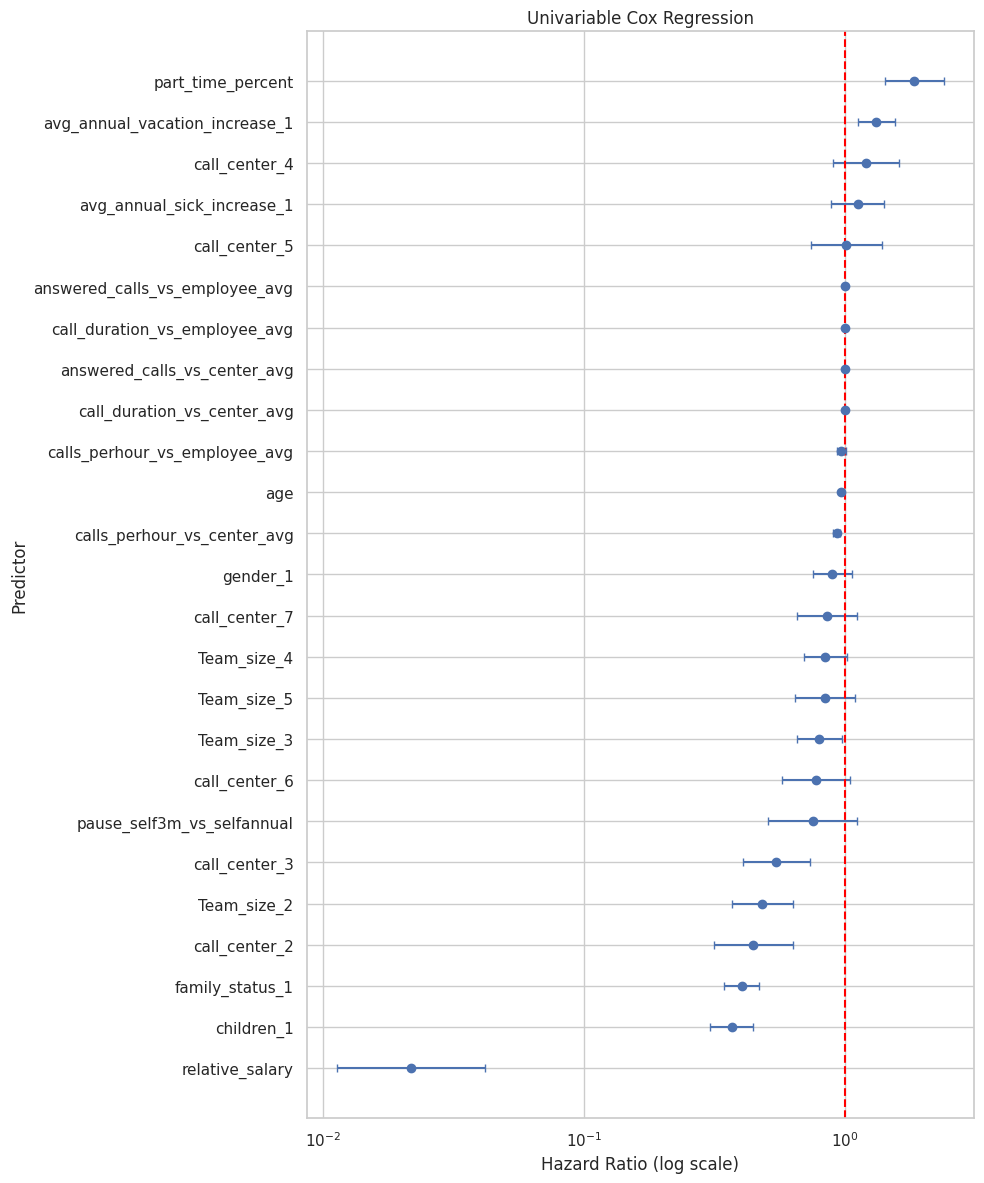

In [ ]:
# ============================================================
# 6.3.2 Forest Plot of Univariable Cox Results
# ============================================================

import matplotlib.pyplot as plt

forest_df = univariable_cox_results.copy()

# Remove extreme values to keep the figure readable
forest_df = forest_df[
    forest_df["Hazard Ratio"] < 20
].copy()

forest_df = forest_df.sort_values(
    "Hazard Ratio"
)

plt.figure(figsize=(10,12))

plt.errorbar(

    forest_df["Hazard Ratio"],

    forest_df["Model Term"],

    xerr=[
        forest_df["Hazard Ratio"] - forest_df["95% CI Lower"],
        forest_df["95% CI Upper"] - forest_df["Hazard Ratio"]
    ],

    fmt="o",

    capsize=3

)

plt.axvline(
    1,
    color="red",
    linestyle="--"
)

plt.xscale("log")

plt.xlabel("Hazard Ratio (log scale)")

plt.ylabel("Predictor")

plt.title("Univariable Cox Regression")

plt.tight_layout()

plt.show()

### 6.3.3 Overall Significance of Multi-category Variables

עבור משתנים קטגוריאליים בעלי יותר משתי רמות (מוקד וגודל צוות), בוצע מבחן Wald כולל לבדיקת תרומת המשתנה כולו למודל.

בדיקה זו משלימה את ההשוואות הבודדות בין כל קטגוריה לבין קטגוריית הייחוס.

In [ ]:
# ============================================================
# 6.3.3 Overall Wald Tests
# ============================================================

from lifelines import CoxPHFitter

multi_level_variables = [

    "call_center",

    "Team_size"

]

overall_tests = []

for variable in multi_level_variables:

    tmp = df_cc[
        [
            TIME_COL,
            EVENT_COL,
            variable
        ]
    ].copy()

    tmp = pd.get_dummies(

        tmp,

        columns=[variable],

        drop_first=True,

        dtype=float

    )

    cph = CoxPHFitter()

    cph.fit(

        tmp,

        duration_col=TIME_COL,

        event_col=EVENT_COL

    )

    overall_tests.append({

        "Variable": variable,

        "Likelihood Ratio χ²":

            round(cph.log_likelihood_ratio_test().test_statistic,2),

        "Degrees of Freedom":

            cph.log_likelihood_ratio_test().degrees_freedom,

        "P-value":

            round(cph.log_likelihood_ratio_test().p_value,5)

    })

overall_tests = pd.DataFrame(overall_tests)

display(overall_tests)

/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:1185: UserWarning: Attempting to convert an unexpected datatype 'category' to float. Suggestion: 1) use `lifelines.utils.datetimes_to_durations` to do conversions or 2) manually convert to floats/booleans.
  warnings.warn(warning_text, UserWarning)
/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:1185: UserWarning: Attempting to convert an unexpected datatype 'category' to float. Suggestion: 1) use `lifelines.utils.datetimes_to_durations` to do conversions or 2) manually convert to floats/booleans.
  warnings.warn(warning_text, UserWarning)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Variable,Likelihood Ratio χ²,Degrees of Freedom,P-value
0,call_center,75.9700,6,0.0000
1,Team_size,33.0100,4,0.0000


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 6.4 בחירת משתנים באמצעות LASSO Cox

### 6.4.1 Preparation of Data for LASSO Cox Regression

בשלב זה הוכנה מטריצת המשתנים לצורך בחירת משתנים באמצעות מודל **LASSO Cox Regression**.

המשתנים הקטגוריאליים קודדו באמצעות משתני Dummy, כאשר הקטגוריה הראשונה בכל משתנה שימשה כקטגוריית הייחוס.

המשתנים הכמותיים נשמרו במטריצת הנתונים המקורית ובשלב הבא עברו **Standardization**, כדי שהענישה המופעלת על ידי LASSO תחול באופן אחיד ללא תלות ביחידות המדידה ובטווח הערכים של המשתנים.

מטריצת הנתונים שהתקבלה שימשה כקלט להתאמת מודל **LASSO Cox** בהתאם לפרוטוקול המחקר.

In [ ]:
# ============================================================
# 6.4.1 Prepare Complete-Case Data for LASSO Cox
# ============================================================

# ------------------------------------------------------------
# Categorical predictors
# ------------------------------------------------------------

lasso_categorical_predictors = [
    "gender",
    "children",
    "call_center",
    "family_status",
    "Team_size",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase"
]

# ------------------------------------------------------------
# Continuous predictors (to be standardized in Section 6.4.2)
# ------------------------------------------------------------

lasso_continuous_predictors = [
    predictor
    for predictor in candidate_predictors
    if predictor not in lasso_categorical_predictors
]

# ------------------------------------------------------------
# Create predictor matrix from the Complete Case dataset
# ------------------------------------------------------------

X_lasso_raw = df_cc[
    candidate_predictors
].copy()

# Explicit conversion to numeric before dummy encoding
for column in lasso_continuous_predictors:
    X_lasso_raw[column] = pd.to_numeric(
        X_lasso_raw[column],
        errors="coerce"
    )

# Dummy encoding:
# the first category is used as the reference category
X_lasso = pd.get_dummies(
    X_lasso_raw,
    columns=lasso_categorical_predictors,
    drop_first=True,
    dtype=float
)

# Ensure all columns are numeric floats
X_lasso = X_lasso.astype(float)

# Survival outcome
y_lasso = df_cc[
    [TIME_COL, EVENT_COL]
].copy()

y_lasso[TIME_COL] = pd.to_numeric(
    y_lasso[TIME_COL],
    errors="coerce"
).astype(float)

y_lasso[EVENT_COL] = pd.to_numeric(
    y_lasso[EVENT_COL],
    errors="coerce"
).astype(int)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert X_lasso.index.equals(y_lasso.index), (
    "Predictor and outcome indices are not aligned."
)

assert X_lasso.isna().sum().sum() == 0, (
    "X_lasso contains missing values."
)

assert y_lasso.isna().sum().sum() == 0, (
    "y_lasso contains missing values."
)

assert np.isfinite(
    X_lasso.to_numpy(dtype=float)
).all(), (
    "X_lasso contains infinite or invalid values."
)

zero_variance_lasso_columns = [
    column
    for column in X_lasso.columns
    if X_lasso[column].nunique(dropna=True) <= 1
]

if zero_variance_lasso_columns:
    X_lasso = X_lasso.drop(
        columns=zero_variance_lasso_columns
    )

# ------------------------------------------------------------
# Display preparation summary
# ------------------------------------------------------------

lasso_preparation_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Candidate variables before dummy encoding",
        "Model columns after dummy encoding",
        "Continuous predictors",
        "Categorical predictors",
        "Events",
        "Censored",
        "Missing predictor values",
        "Zero-variance columns removed"
    ],
    "Value": [
        len(X_lasso),
        len(candidate_predictors),
        X_lasso.shape[1],
        len(lasso_continuous_predictors),
        len(lasso_categorical_predictors),
        int(y_lasso[EVENT_COL].sum()),
        int((y_lasso[EVENT_COL] == 0).sum()),
        int(X_lasso.isna().sum().sum()),
        len(zero_variance_lasso_columns)
    ]
})

display(lasso_preparation_summary)

print("\nColumns in the LASSO design matrix:")
print(X_lasso.columns.tolist())

if zero_variance_lasso_columns:
    print(
        "\nZero-variance columns removed:",
        zero_variance_lasso_columns
    )

print("\nLASSO preparation completed successfully.")

,Metric,Value
0,Observations,1288
1,Candidate variables before dummy encoding,17
2,Model columns after dummy encoding,25
3,Continuous predictors,10
4,Categorical predictors,7
5,Events,985
6,Censored,303
7,Missing predictor values,0
8,Zero-variance columns removed,0



Columns in the LASSO design matrix:
['age', 'relative_salary', 'part_time_percent', 'answered_calls_vs_center_avg', 'answered_calls_vs_employee_avg', 'call_duration_vs_center_avg', 'call_duration_vs_employee_avg', 'calls_perhour_vs_center_avg', 'calls_perhour_vs_employee_avg', 'pause_self3m_vs_selfannual', 'gender_1', 'children_1', 'call_center_2', 'call_center_3', 'call_center_4', 'call_center_5', 'call_center_6', 'call_center_7', 'family_status_1', 'Team_size_2', 'Team_size_3', 'Team_size_4', 'Team_size_5', 'avg_annual_vacation_increase_1', 'avg_annual_sick_increase_1']

LASSO preparation completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 6.4.2 Standardization and Cross-Validation Setup

To identify the optimal penalty parameter (λ), a 10-fold cross-validation procedure was used.

Because LASSO penalization is sensitive to the scale of the predictors, all continuous variables were standardized within each training fold before model fitting. This approach prevents information leakage from the validation data.

A logarithmically spaced grid of penalty values was evaluated, and model performance was assessed across all folds to identify the optimal amount of regularization.

In [ ]:
# ============================================================
# 6.4.2 Standardize Predictors for LASSO Cox
# ============================================================

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Continuous variables to standardize
# ------------------------------------------------------------

continuous_columns = [
    column
    for column in X_lasso.columns
    if column in lasso_continuous_predictors
]

# ------------------------------------------------------------
# Create standardized design matrix
# ------------------------------------------------------------

X_lasso_standardized = X_lasso.copy()

lasso_scaler = StandardScaler()

X_lasso_standardized[continuous_columns] = (
    lasso_scaler.fit_transform(
        X_lasso_standardized[continuous_columns]
    )
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert X_lasso_standardized.shape == X_lasso.shape, (
    "The dimensions changed during standardization."
)

assert X_lasso_standardized.isna().sum().sum() == 0, (
    "Missing values were created during standardization."
)

assert np.isfinite(
    X_lasso_standardized.to_numpy(dtype=float)
).all(), (
    "The standardized matrix contains invalid values."
)

standardization_check = pd.DataFrame({
    "Variable": continuous_columns,
    "Mean after standardization": [
        X_lasso_standardized[column].mean()
        for column in continuous_columns
    ],
    "Standard deviation after standardization": [
        X_lasso_standardized[column].std(ddof=0)
        for column in continuous_columns
    ]
})

standardization_check[
    [
        "Mean after standardization",
        "Standard deviation after standardization"
    ]
] = standardization_check[
    [
        "Mean after standardization",
        "Standard deviation after standardization"
    ]
].round(4)

display(standardization_check)

print("Predictor standardization completed successfully.")
print(f"Continuous predictors standardized: {len(continuous_columns)}")
print(
    "Binary and dummy variables were retained "
    "in their original 0/1 coding."
)

,Variable,Mean after standardization,Standard deviation after standardization
0,age,0.0000,1.0000
1,relative_salary,-0.0000,1.0000
2,part_time_percent,0.0000,1.0000
3,answered_calls_vs_center_avg,-0.0000,1.0000
4,answered_calls_vs_employee_avg,0.0000,1.0000
5,call_duration_vs_center_avg,0.0000,1.0000
6,call_duration_vs_employee_avg,0.0000,1.0000
7,calls_perhour_vs_center_avg,0.0000,1.0000
8,calls_perhour_vs_employee_avg,0.0000,1.0000
9,pause_self3m_vs_selfannual,-0.0000,1.0000


Predictor standardization completed successfully.
Continuous predictors standardized: 10
Binary and dummy variables were retained in their original 0/1 coding.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


6.4.3 Sensitivity Analysis for the Penalizer

### 6.4.3 ניתוח רגישות לעוצמת הענישה

בחירת פרמטר הרגולריזציה (λ) – הפרמטר λ קובע את עוצמת הענישה המופעלת על מקדמי המודל. במחקר הנוכחי בוצע ניתוח רגישות באמצעות מספר ערכי Penalizer שהוגדרו מראש: 0.005, 0.01, 0.02, 0.05 ו־0.10. עבור כל ערך נבחנה רשימת המשתנים שנבחרה ומידת יציבותה. בהתאם לתוצאות הבדיקה נבחר penalizer = 0.02 להתאמת מודל ה־LASSO הסופי.

In [ ]:
# ============================================================
# 6.4.3 Sensitivity Analysis for the LASSO Penalizer
# ============================================================

from lifelines import CoxPHFitter

# ------------------------------------------------------------
# Predefined penalizer values
# ------------------------------------------------------------

PENALIZER_VALUES = [
    0.005,
    0.01,
    0.02,
    0.05,
    0.10
]

LASSO_L1_RATIO = 1.0

# lifelines may return extremely small coefficients
# instead of exact numerical zeros
COEFFICIENT_THRESHOLD = 1e-6

# ------------------------------------------------------------
# Combine standardized predictors with survival outcome
# ------------------------------------------------------------

lasso_sensitivity_data = X_lasso_standardized.copy()

lasso_sensitivity_data[TIME_COL] = (
    y_lasso[TIME_COL]
    .astype(float)
)

lasso_sensitivity_data[EVENT_COL] = (
    y_lasso[EVENT_COL]
    .astype(int)
)

assert lasso_sensitivity_data.isna().sum().sum() == 0, (
    "The LASSO sensitivity dataset contains missing values."
)

assert np.isfinite(
    lasso_sensitivity_data.to_numpy(dtype=float)
).all(), (
    "The LASSO sensitivity dataset contains invalid values."
)

# ------------------------------------------------------------
# Map dummy terms to their original variables
# ------------------------------------------------------------

def map_term_to_original_variable(term):

    if term.startswith("call_center_"):
        return "call_center"

    if term.startswith("Team_size_"):
        return "Team_size"

    if term == "gender_1":
        return "gender"

    if term == "children_1":
        return "children"

    if term == "family_status_1":
        return "family_status"

    if term == "avg_annual_vacation_increase_1":
        return "avg_annual_vacation_increase"

    if term == "avg_annual_sick_increase_1":
        return "avg_annual_sick_increase"

    return term


# ------------------------------------------------------------
# Fit one LASSO Cox model for each penalizer value
# ------------------------------------------------------------

penalizer_summary_rows = []
penalizer_coefficient_rows = []

for penalizer_value in PENALIZER_VALUES:

    sensitivity_model = CoxPHFitter(
        penalizer=penalizer_value,
        l1_ratio=LASSO_L1_RATIO
    )

    sensitivity_model.fit(
        lasso_sensitivity_data,
        duration_col=TIME_COL,
        event_col=EVENT_COL
    )

    coefficients = (
        sensitivity_model.params_
        .rename("Coefficient")
        .reset_index()
        .rename(columns={"covariate": "Model Term"})
    )

    coefficients["Absolute Coefficient"] = (
        coefficients["Coefficient"].abs()
    )

    coefficients["Selected"] = (
        coefficients["Absolute Coefficient"]
        > COEFFICIENT_THRESHOLD
    )

    coefficients["Penalizer"] = penalizer_value

    coefficients["Original Variable"] = (
        coefficients["Model Term"]
        .apply(map_term_to_original_variable)
    )

    selected_terms = (
        coefficients
        .loc[
            coefficients["Selected"],
            "Model Term"
        ]
        .tolist()
    )

    selected_original_variables = list(
        dict.fromkeys(
            coefficients
            .loc[
                coefficients["Selected"],
                "Original Variable"
            ]
            .tolist()
        )
    )

    penalizer_summary_rows.append({
        "Penalizer": penalizer_value,
        "Selected Model Terms": len(selected_terms),
        "Selected Original Variables": (
            len(selected_original_variables)
        ),
        "Selected Variables": ", ".join(
            selected_original_variables
        )
    })

    penalizer_coefficient_rows.append(
        coefficients
    )

# ------------------------------------------------------------
# Create summary tables
# ------------------------------------------------------------

lasso_penalizer_sensitivity = pd.DataFrame(
    penalizer_summary_rows
)

lasso_penalizer_coefficients = pd.concat(
    penalizer_coefficient_rows,
    ignore_index=True
)

lasso_penalizer_sensitivity[
    "Penalizer"
] = lasso_penalizer_sensitivity[
    "Penalizer"
].round(3)

display(lasso_penalizer_sensitivity)

print(
    "Penalizer sensitivity analysis "
    "completed successfully."
)

,Penalizer,Selected Model Terms,Selected Original Variables,Selected Variables
0,0.0050,25,17,"age, relative_salary, part_time_percent, answe..."
1,0.0100,22,17,"age, relative_salary, part_time_percent, answe..."
2,0.0200,13,10,"age, relative_salary, part_time_percent, answe..."
3,0.0500,11,9,"age, relative_salary, part_time_percent, answe..."
4,0.1000,6,6,"relative_salary, answered_calls_vs_employee_av..."


Penalizer sensitivity analysis completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 6.4.3.1 Variable-Selection Stability Across Penalizers
# ============================================================

selection_stability = (
    lasso_penalizer_coefficients
    .pivot_table(
        index="Original Variable",
        columns="Penalizer",
        values="Selected",
        aggfunc="max",
        fill_value=False
    )
)

selection_stability = (
    selection_stability
    .astype(bool)
)

selection_stability["Times Selected"] = (
    selection_stability[
        PENALIZER_VALUES
    ]
    .sum(axis=1)
)

selection_stability = (
    selection_stability
    .sort_values(
        [
            "Times Selected"
        ] + PENALIZER_VALUES,
        ascending=False
    )
)

display(selection_stability)

Penalizer,0.0050,0.0100,0.0200,0.0500,0.1000,Times Selected
Original Variable,,,,,,
answered_calls_vs_employee_avg,True,True,True,True,True,5
call_center,True,True,True,True,True,5
calls_perhour_vs_center_avg,True,True,True,True,True,5
children,True,True,True,True,True,5
family_status,True,True,True,True,True,5
relative_salary,True,True,True,True,True,5
age,True,True,True,True,False,4
call_duration_vs_employee_avg,True,True,True,True,False,4
part_time_percent,True,True,True,True,False,4


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.12/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


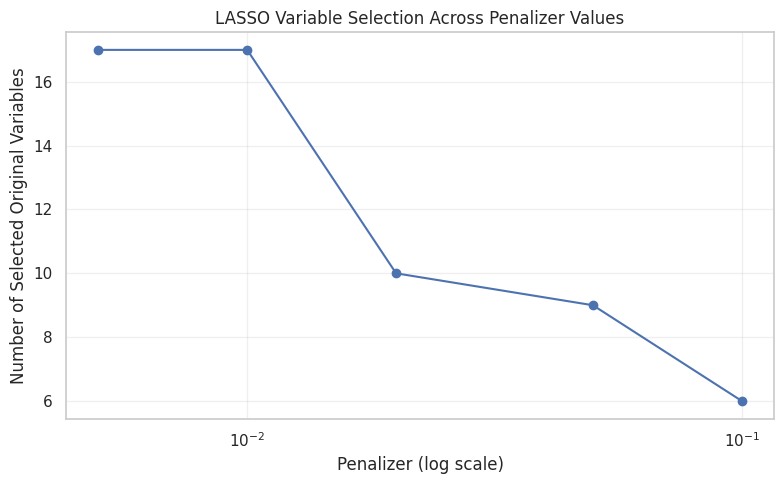

In [ ]:
# ============================================================
# 6.4.3.2 Number of Selected Variables by Penalizer
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    lasso_penalizer_sensitivity["Penalizer"],
    lasso_penalizer_sensitivity[
        "Selected Original Variables"
    ],
    marker="o"
)

plt.xscale("log")

plt.xlabel("Penalizer (log scale)")
plt.ylabel("Number of Selected Original Variables")
plt.title(
    "LASSO Variable Selection Across Penalizer Values"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 6.4.3.3 Variables Selected with Penalizer = 0.02
# ============================================================

PENALIZER_TO_INSPECT = 0.02

selected_at_002 = (
    lasso_penalizer_coefficients
    .loc[
        (lasso_penalizer_coefficients["Penalizer"] == PENALIZER_TO_INSPECT)
        & (lasso_penalizer_coefficients["Selected"]),
        [
            "Model Term",
            "Original Variable",
            "Coefficient",
            "Absolute Coefficient"
        ]
    ]
    .copy()
)

selected_at_002 = (
    selected_at_002
    .sort_values(
        "Absolute Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

selected_at_002[
    [
        "Coefficient",
        "Absolute Coefficient"
    ]
] = selected_at_002[
    [
        "Coefficient",
        "Absolute Coefficient"
    ]
].round(6)

display(selected_at_002)

selected_original_variables_002 = list(
    dict.fromkeys(
        selected_at_002["Original Variable"].tolist()
    )
)

print("Penalizer = 0.02")
print("-" * 40)
print(
    f"Selected model terms: "
    f"{len(selected_at_002)}"
)
print(
    f"Selected original variables: "
    f"{len(selected_original_variables_002)}"
)

print("\nSelected original variables:")
for variable in selected_original_variables_002:
    print(f"- {variable}")

,Model Term,Original Variable,Coefficient,Absolute Coefficient
0,call_center_2,call_center,-0.9204,0.9204
1,family_status_1,family_status,-0.4902,0.4902
2,children_1,children,-0.4799,0.4799
3,relative_salary,relative_salary,-0.4194,0.4194
4,call_center_5,call_center,0.1835,0.1835
5,call_center_3,call_center,-0.1748,0.1748
6,answered_calls_vs_employee_avg,answered_calls_vs_employee_avg,0.1375,0.1375
7,call_duration_vs_employee_avg,call_duration_vs_employee_avg,0.1094,0.1094
8,age,age,-0.0924,0.0924
9,part_time_percent,part_time_percent,0.0864,0.0864


Penalizer = 0.02
----------------------------------------
Selected model terms: 13
Selected original variables: 10

Selected original variables:
- call_center
- family_status
- children
- relative_salary
- answered_calls_vs_employee_avg
- call_duration_vs_employee_avg
- age
- part_time_percent
- calls_perhour_vs_center_avg
- avg_annual_sick_increase


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 6.4.4 Fit Final LASSO Cox Model Using the Selected Penalizer
# ============================================================

from lifelines import CoxPHFitter

# ------------------------------------------------------------
# Penalizer selected following the sensitivity analysis
# ------------------------------------------------------------

SELECTED_PENALIZER = 0.02
LASSO_L1_RATIO = 1.0

# lifelines may return extremely small coefficients instead
# of exact numerical zeros
COEFFICIENT_THRESHOLD = 1e-6

# ------------------------------------------------------------
# Combine standardized predictors with survival outcome
# ------------------------------------------------------------

lasso_model_data = X_lasso_standardized.copy()

lasso_model_data[TIME_COL] = (
    y_lasso[TIME_COL]
    .astype(float)
)

lasso_model_data[EVENT_COL] = (
    y_lasso[EVENT_COL]
    .astype(int)
)

# ------------------------------------------------------------
# Validate the final LASSO dataset
# ------------------------------------------------------------

assert lasso_model_data.isna().sum().sum() == 0, (
    "The final LASSO dataset contains missing values."
)

assert np.isfinite(
    lasso_model_data.to_numpy(dtype=float)
).all(), (
    "The final LASSO dataset contains invalid values."
)

# ------------------------------------------------------------
# Fit the final LASSO Cox model
# ------------------------------------------------------------

lasso_penalizer_used = SELECTED_PENALIZER

lasso_model = CoxPHFitter(
    penalizer=lasso_penalizer_used,
    l1_ratio=LASSO_L1_RATIO
)

lasso_model.fit(
    lasso_model_data,
    duration_col=TIME_COL,
    event_col=EVENT_COL
)

# ------------------------------------------------------------
# Extract and classify coefficients
# ------------------------------------------------------------

lasso_coefficient_table = (
    lasso_model.summary
    .reset_index()
    .rename(columns={"covariate": "Variable"})
)

lasso_coefficient_table["Absolute Coefficient"] = (
    lasso_coefficient_table["coef"].abs()
)

lasso_coefficient_table["Selected"] = (
    lasso_coefficient_table["Absolute Coefficient"]
    > COEFFICIENT_THRESHOLD
)

selected_lasso_variables = (
    lasso_coefficient_table
    .loc[
        lasso_coefficient_table["Selected"],
        "Variable"
    ]
    .tolist()
)

# ------------------------------------------------------------
# Format results
# ------------------------------------------------------------

lasso_coefficient_results = (
    lasso_coefficient_table[
        [
            "Variable",
            "coef",
            "exp(coef)",
            "Absolute Coefficient",
            "Selected"
        ]
    ]
    .rename(columns={
        "coef": "Coefficient",
        "exp(coef)": "Hazard Ratio"
    })
    .sort_values(
        "Absolute Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

lasso_coefficient_results[
    [
        "Coefficient",
        "Hazard Ratio",
        "Absolute Coefficient"
    ]
] = lasso_coefficient_results[
    [
        "Coefficient",
        "Hazard Ratio",
        "Absolute Coefficient"
    ]
].round(6)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("Final LASSO Cox model completed successfully.")
print("-" * 50)
print(f"Selected penalizer: {lasso_penalizer_used}")
print(f"L1 ratio: {LASSO_L1_RATIO}")
print(
    f"Predictor columns evaluated: "
    f"{X_lasso_standardized.shape[1]}"
)
print(
    f"Predictor columns retained: "
    f"{len(selected_lasso_variables)}"
)

display(lasso_coefficient_results)

print("\nModel terms retained by the final LASSO model:")
for variable in selected_lasso_variables:
    print(f"- {variable}")

Final LASSO Cox model completed successfully.
--------------------------------------------------
Selected penalizer: 0.02
L1 ratio: 1.0
Predictor columns evaluated: 25
Predictor columns retained: 13


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Variable,Coefficient,Hazard Ratio,Absolute Coefficient,Selected
0,call_center_2,-0.9204,0.3983,0.9204,True
1,family_status_1,-0.4902,0.6125,0.4902,True
2,children_1,-0.4799,0.6189,0.4799,True
3,relative_salary,-0.4194,0.6574,0.4194,True
4,call_center_5,0.1835,1.2014,0.1835,True
5,call_center_3,-0.1748,0.8396,0.1748,True
6,answered_calls_vs_employee_avg,0.1375,1.1474,0.1375,True
7,call_duration_vs_employee_avg,0.1094,1.1156,0.1094,True
8,age,-0.0924,0.9117,0.0924,True
9,part_time_percent,0.0864,1.0903,0.0864,True



Model terms retained by the final LASSO model:
- age
- relative_salary
- part_time_percent
- answered_calls_vs_employee_avg
- call_duration_vs_employee_avg
- calls_perhour_vs_center_avg
- children_1
- call_center_2
- call_center_3
- call_center_4
- call_center_5
- family_status_1
- avg_annual_sick_increase_1


מודל ה־LASSO Cox הסופי שמר במודל רק משתנים שמקדמי הרגרסיה שלהם נותרו שונים מאפס לאחר החלת הענישה באמצעות ערך ה־penalizer שנבחר (penalizer = 0.02).

במשתנים קטגוריאליים שיוצגו באמצעות מספר משתני דמה (Dummy Variables), בחירה של אחד או יותר ממקדמי ה־Dummy פורשה כבחירה של המשתנה המקורי.

המשתנים שנבחרו במודל ה־LASSO הסופי שימשו בהמשך להתאמת מודל Cox Proportional Hazards רב־משתני.

In [ ]:
# ============================================================
# 6.4.5 Variables Selected by the Final LASSO Model
# ============================================================

# ------------------------------------------------------------
# Convert dummy variables back to original variables
# ------------------------------------------------------------

def map_lasso_variable(variable):

    if variable.startswith("call_center_"):
        return "call_center"

    if variable.startswith("Team_size_"):
        return "Team_size"

    if variable == "children_1":
        return "children"

    if variable == "family_status_1":
        return "family_status"

    if variable == "gender_1":
        return "gender"

    if variable == "avg_annual_vacation_increase_1":
        return "avg_annual_vacation_increase"

    if variable == "avg_annual_sick_increase_1":
        return "avg_annual_sick_increase"

    return variable


selected_original_variables = (
    lasso_coefficient_results
    .loc[
        lasso_coefficient_results["Selected"],
        "Variable"
    ]
    .apply(map_lasso_variable)
)

selected_original_variables = (
    pd.Series(selected_original_variables.unique())
    .sort_values()
    .reset_index(drop=True)
)

selected_variables_table = pd.DataFrame({

    "Selected Variable": selected_original_variables

})

display(selected_variables_table)

print("-" * 50)
print(
    f"Number of original variables retained: "
    f"{len(selected_variables_table)}"
)

,Selected Variable
0,age
1,answered_calls_vs_employee_avg
2,avg_annual_sick_increase
3,call_center
4,call_duration_vs_employee_avg
5,calls_perhour_vs_center_avg
6,children
7,family_status
8,part_time_percent
9,relative_salary


--------------------------------------------------
Number of original variables retained: 10


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


הממצאים של LASSO

מתוך 17 המשתנים המקוריים שנכנסו ל־LASSO, נבחרו 10 משתנים (58.8%):  
| קטגוריה   | משתנה                          |
| --------- | ------------------------------ |
| דמוגרפי   | age                            |
| דמוגרפי   | children                       |
| דמוגרפי   | family_status                  |
| תגמול     | relative_salary                |
| תעסוקה    | part_time_percent              |
| ארגוני    | call_center                    |
| היעדרויות | avg_annual_sick_increase       |
| KPI       | answered_calls_vs_employee_avg |
| KPI       | call_duration_vs_employee_avg  |
| KPI       | calls_perhour_vs_center_avg    |
  
  המשתנים שלא נבחרו
Team_size  
gender  
avg_annual_vacation_increase  
answered_calls_vs_center_avg  
call_duration_vs_center_avg  
calls_perhour_vs_employee_avg  
pause_self3m_vs_selfannual

ממצאים עיקריים

מודל ה־LASSO Cox הסופי בחר 10 מתוך 17 משתני המועמד שנכללו בניתוח.

המשתנים שנבחרו מייצגים מאפיינים דמוגרפיים, מאפייני תעסוקה, גורמים ארגוניים, היעדרויות ומדדי ביצוע תפעוליים (KPI).

מבין משתני ה־KPI הנגזרים, שלושה משתנים נותרו במודל הסופי:

ההפרש בין ממוצע השיחות הנענות של העובד בשלושת החודשים האחרונים לבין ממוצע השיחות הנענות של אותו עובד בשנה האחרונה.
ההפרש בין ממוצע משך השיחה של העובד בשלושת החודשים האחרונים לבין ממוצע משך השיחה של אותו עובד בשנה האחרונה.
ההפרש בין ממוצע מספר השיחות לשעה של העובד בשלושת החודשים האחרונים לבין ממוצע מספר השיחות לשעה במוקד כולו בשנה האחרונה.

המשתנים שנבחרו שימשו בהמשך להתאמת מודל Cox Proportional Hazards הרב־משתני.

# 6.5 Multivariable Cox Model Using LASSO-Selected Variables

המטרה היא לקחת את 10 המשתנים המקוריים שנבחרו על ידי LASSO ולהתאים מודל Cox רב־משתני "רגיל" (ללא ענישה), כדי לקבל:

מקדמים (β)
Hazard Ratios
רווחי סמך 95%
ערכי p
מבחן Wald
Log-likelihood
Concordance Index (נציג אותו כתוצר של lifelines, אבל לא נשתמש בו לבחירת המודל)
Likelihood Ratio Test

זהו המודל שנשווה בהמשך למודל שנבחר באמצעות Stepwise.

### 6.5.1 הכנת הנתונים למודל Cox הרב־משתני

בשלב זה נבנתה מסגרת הנתונים עבור מודל Cox הרב־משתני, תוך שימוש אך ורק במשתנים שנבחרו על ידי מודל ה־LASSO הסופי.

משתנים קטגוריאליים קודדו באמצעות משתני Dummy, כאשר הקטגוריה הראשונה שימשה כקטגוריית הייחוס.

מערך הנתונים שהתקבל שימש להתאמת מודל Cox הרב־משתני.

In [ ]:
# ============================================================
# 6.5.1 Prepare Data for the Final Multivariable Cox Model
# ============================================================

# ------------------------------------------------------------
# Original variables selected by the final LASSO model
# ------------------------------------------------------------

lasso_final_predictors = [

    "age",
    "relative_salary",
    "part_time_percent",

    "children",
    "family_status",
    "call_center",

    "avg_annual_sick_increase",

    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg",
    "calls_perhour_vs_center_avg"

]

# ------------------------------------------------------------
# Categorical variables
# ------------------------------------------------------------

lasso_final_categorical = [

    "children",
    "family_status",
    "call_center",
    "avg_annual_sick_increase"

]

# ------------------------------------------------------------
# Create design matrix
# ------------------------------------------------------------

X_final = df_cc[
    lasso_final_predictors
].copy()

X_final = pd.get_dummies(

    X_final,

    columns=lasso_final_categorical,

    drop_first=True,

    dtype=float

)

# ------------------------------------------------------------
# Combine with survival outcome
# ------------------------------------------------------------

cox_final_data = X_final.copy()

cox_final_data[TIME_COL] = (
    df_cc[TIME_COL]
    .astype(float)
)

cox_final_data[EVENT_COL] = (
    df_cc[EVENT_COL]
    .astype(int)
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert cox_final_data.isna().sum().sum() == 0

assert np.isfinite(
    cox_final_data.to_numpy(dtype=float)
).all()

summary_final_dataset = pd.DataFrame({

    "Metric":[

        "Observations",

        "Events",

        "Censored",

        "Predictors",

        "Model columns"

    ],

    "Value":[

        len(cox_final_data),

        int(cox_final_data[EVENT_COL].sum()),

        int((cox_final_data[EVENT_COL]==0).sum()),

        len(lasso_final_predictors),

        X_final.shape[1]

    ]

})

display(summary_final_dataset)

print("\nModel columns:")

print(X_final.columns.tolist())

,Metric,Value
0,Observations,1288
1,Events,985
2,Censored,303
3,Predictors,10
4,Model columns,15



Model columns:
['age', 'relative_salary', 'part_time_percent', 'answered_calls_vs_employee_avg', 'call_duration_vs_employee_avg', 'calls_perhour_vs_center_avg', 'children_1', 'family_status_1', 'call_center_2', 'call_center_3', 'call_center_4', 'call_center_5', 'call_center_6', 'call_center_7', 'avg_annual_sick_increase_1']


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 6.5.2 Fit the Multivariable Cox Model
# Using LASSO-Selected Variables
# ============================================================

from lifelines import CoxPHFitter

# ------------------------------------------------------------
# Fit an unpenalized multivariable Cox model
# ------------------------------------------------------------

cox_lasso_selected_model = CoxPHFitter()

cox_lasso_selected_model.fit(
    cox_final_data,
    duration_col=TIME_COL,
    event_col=EVENT_COL
)

# ------------------------------------------------------------
# Extract model results
# ------------------------------------------------------------

cox_lasso_selected_results = (
    cox_lasso_selected_model.summary
    .reset_index()
    .rename(columns={
        "covariate": "Variable",
        "coef": "Coefficient",
        "exp(coef)": "Hazard Ratio",
        "exp(coef) lower 95%": "95% CI Lower",
        "exp(coef) upper 95%": "95% CI Upper",
        "p": "P-value",
        "z": "Z Statistic"
    })
)

result_columns = [
    "Variable",
    "Coefficient",
    "Hazard Ratio",
    "95% CI Lower",
    "95% CI Upper",
    "Z Statistic",
    "P-value"
]

cox_lasso_selected_results = (
    cox_lasso_selected_results[result_columns]
    .sort_values("P-value")
    .reset_index(drop=True)
)

cox_lasso_selected_results[
    [
        "Coefficient",
        "Hazard Ratio",
        "95% CI Lower",
        "95% CI Upper",
        "Z Statistic",
        "P-value"
    ]
] = cox_lasso_selected_results[
    [
        "Coefficient",
        "Hazard Ratio",
        "95% CI Lower",
        "95% CI Upper",
        "Z Statistic",
        "P-value"
    ]
].round(4)

# ------------------------------------------------------------
# Display coefficient table
# ------------------------------------------------------------

display(cox_lasso_selected_results)

# ------------------------------------------------------------
# Display model-level statistics
# ------------------------------------------------------------

likelihood_ratio_test = (
    cox_lasso_selected_model
    .log_likelihood_ratio_test()
)

model_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Events",
        "Model columns",
        "Partial log-likelihood",
        "Likelihood Ratio χ²",
        "Degrees of freedom",
        "Likelihood Ratio p-value"
    ],
    "Value": [
        len(cox_final_data),
        int(cox_final_data[EVENT_COL].sum()),
        X_final.shape[1],
        round(
            cox_lasso_selected_model.log_likelihood_,
            4
        ),
        round(
            likelihood_ratio_test.test_statistic,
            4
        ),
        likelihood_ratio_test.degrees_freedom,
        likelihood_ratio_test.p_value
    ]
})

display(model_summary)

print(
    "Multivariable Cox model using "
    "LASSO-selected variables fitted successfully."
)

,Variable,Coefficient,Hazard Ratio,95% CI Lower,95% CI Upper,Z Statistic,P-value
0,relative_salary,-3.9815,0.0187,0.0085,0.0410,-9.9236,0.0000
1,call_center_2,-1.1083,0.3301,0.2302,0.4735,-6.0224,0.0000
2,answered_calls_vs_employee_avg,0.0012,1.0012,1.0007,1.0017,4.8821,0.0000
3,family_status_1,-0.5371,0.5844,0.4705,0.7260,-4.8542,0.0000
4,call_duration_vs_employee_avg,0.0011,1.0011,1.0006,1.0015,4.7926,0.0000
5,age,-0.0255,0.9749,0.9615,0.9884,-3.6157,0.0003
6,calls_perhour_vs_center_avg,-0.0475,0.9536,0.9273,0.9807,-3.3265,0.0009
7,children_1,-0.4536,0.6354,0.4852,0.8319,-3.2982,0.0010
8,part_time_percent,0.4885,1.6298,1.1953,2.2223,3.0875,0.0020
9,call_center_3,-0.3059,0.7365,0.5438,0.9976,-1.9758,0.0482


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Value
0,Observations,"1,288.0000"
1,Events,985.0000
2,Model columns,15.0000
3,Partial log-likelihood,"-5,983.2484"
4,Likelihood Ratio χ²,493.1624
5,Degrees of freedom,15.0000
6,Likelihood Ratio p-value,0.0000


Multivariable Cox model using LASSO-selected variables fitted successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 6.5.3 בדיקת הנחת הסיכונים הפרופורציונליים

הנחת הסיכונים הפרופורציונליים (Proportional Hazards Assumption) קובעת כי יחס הסיכונים בין עובדים בעלי ערכים שונים של משתני ההסבר נשאר קבוע לאורך תקופת המעקב.

ההנחה נבדקה באמצעות מבחן המבוסס על Schoenfeld Residuals. עבור כל עמודת מודל חושב ערך p לבדיקת הקשר בין השאריות לבין הזמן.

ערך p קטן מ־0.05 עשוי להצביע על הפרה של הנחת הסיכונים הפרופורציונליים עבור המשתנה שנבדק.

In [ ]:
# ============================================================
# 6.5.3 Test the Proportional Hazards Assumption
# LASSO-Selected Multivariable Cox Model
# ============================================================

from lifelines.statistics import proportional_hazard_test

# ------------------------------------------------------------
# Schoenfeld residual-based proportional hazards test
# ------------------------------------------------------------

ph_test_lasso = proportional_hazard_test(
    cox_lasso_selected_model,
    cox_final_data,
    time_transform="rank"
)

# ------------------------------------------------------------
# Create a clean results table
# ------------------------------------------------------------

ph_results_lasso = (
    ph_test_lasso.summary
    .reset_index()
    .rename(columns={
        "index": "Variable",
        "test_statistic": "Test Statistic",
        "p": "P-value",
        "-log2(p)": "-log2(P-value)"
    })
)

ph_results_lasso["PH Assumption"] = np.where(
    ph_results_lasso["P-value"] < 0.05,
    "Potential violation",
    "No evidence of violation"
)

ph_results_lasso[
    [
        "Test Statistic",
        "P-value",
        "-log2(P-value)"
    ]
] = ph_results_lasso[
    [
        "Test Statistic",
        "P-value",
        "-log2(P-value)"
    ]
].round(4)

ph_results_lasso = (
    ph_results_lasso
    .sort_values("P-value")
    .reset_index(drop=True)
)

display(ph_results_lasso)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

violating_ph_terms_lasso = (
    ph_results_lasso
    .loc[
        ph_results_lasso["P-value"] < 0.05,
        "Variable"
    ]
    .tolist()
)

print("Proportional hazards assessment completed.")
print("-" * 50)
print(
    f"Model terms assessed: "
    f"{len(ph_results_lasso)}"
)
print(
    f"Terms with p < 0.05: "
    f"{len(violating_ph_terms_lasso)}"
)

if violating_ph_terms_lasso:

    print("\nTerms showing a potential PH violation:")

    for variable in violating_ph_terms_lasso:
        print(f"- {variable}")

else:

    print(
        "\nNo evidence of proportional hazards "
        "violations was detected."
    )

,Variable,Test Statistic,P-value,-log2(P-value),PH Assumption
0,answered_calls_vs_employee_avg,35.9321,0.0000,28.8666,Potential violation
1,relative_salary,21.5026,0.0000,18.1105,Potential violation
2,calls_perhour_vs_center_avg,19.7835,0.0000,16.8151,Potential violation
3,call_duration_vs_employee_avg,80.8884,0.0000,61.8607,Potential violation
4,part_time_percent,19.4062,0.0000,16.5302,Potential violation
5,call_center_5,13.1999,0.0003,11.8025,Potential violation
6,call_center_6,7.4935,0.0062,7.3353,Potential violation
7,children_1,4.8002,0.0285,5.1351,Potential violation
8,call_center_2,3.7440,0.0530,4.2380,No evidence of violation
9,family_status_1,1.3726,0.2414,2.0507,No evidence of violation


Proportional hazards assessment completed.
--------------------------------------------------
Model terms assessed: 15
Terms with p < 0.05: 8

Terms showing a potential PH violation:
- answered_calls_vs_employee_avg
- relative_salary
- calls_perhour_vs_center_avg
- call_duration_vs_employee_avg
- part_time_percent
- call_center_5
- call_center_6
- children_1


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 6.5.3.1 Detailed Proportional Hazards Diagnostics
# ============================================================

cox_lasso_selected_model.check_assumptions(
    cox_final_data,
    p_value_threshold=0.05,
    show_plots=False
)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)




1. Variable 'relative_salary' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'relative_salary' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'relative_salary' using pd.cut, and then specify it in
`strata=['relative_salary', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'part_time_percent' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'part_time_percent' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in

[]

## 6.6 בחירת משתנים באמצעות Forward Stepwise Selection

בחירת המשתנים בשיטת Stepwise בוצעה בתהליך Forward הדרגתי, שהחל ממודל ללא משתנים מסבירים.

בכל איטרציה נבחן כל אחד מהמשתנים שטרם נכללו במודל. עבור כל משתנה מועמד הותאם מודל Cox שכלל את המשתנים שכבר נבחרו ואת המשתנה החדש.

יכולת הניבוי של כל מודל הוערכה באמצעות 10-fold Cross-Validation, כאשר קריטריון הבחירה היה IPCW Brier Score עבור הסתברות ההישרדות לאחר 12 חודשי ותק. ערכים נמוכים יותר של המדד מעידים על דיוק תחזית גבוה יותר.

בכל שלב נוסף המשתנה שהוביל לירידה הגדולה ביותר ב־Brier Score. התהליך הסתיים כאשר אף אחד מהמשתנים שנותרו לא שיפר עוד את ביצועי המודל.

In [ ]:
# ============================================================
# 6.6.1 Prepare Data and Helper Functions for
# Forward Stepwise Selection Using 10-Fold Brier Score
# ============================================================

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.exceptions import ConvergenceError
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Stepwise study settings
# ------------------------------------------------------------

STEPWISE_PREDICTION_TIME = 12.0
STEPWISE_N_SPLITS = 10
STEPWISE_RANDOM_STATE = 42

# Numerical tolerance only:
# a candidate must produce a genuinely lower Brier Score
STEPWISE_NUMERICAL_TOLERANCE = 1e-8

# All candidate variables may be selected
STEPWISE_MAX_FEATURES = len(candidate_predictors)

# ------------------------------------------------------------
# Categorical and continuous candidate predictors
# ------------------------------------------------------------

stepwise_categorical_predictors = [
    "gender",
    "children",
    "call_center",
    "family_status",
    "Team_size",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase"
]

stepwise_continuous_predictors = [
    predictor
    for predictor in candidate_predictors
    if predictor not in stepwise_categorical_predictors
]

# ------------------------------------------------------------
# Create one encoded design matrix
#
# Each categorical predictor will still be treated as one
# original-variable block during Stepwise selection.
# ------------------------------------------------------------

X_stepwise_raw = df_cc[
    candidate_predictors
].copy()

for column in stepwise_continuous_predictors:
    X_stepwise_raw[column] = pd.to_numeric(
        X_stepwise_raw[column],
        errors="coerce"
    )

X_stepwise_all = pd.get_dummies(
    X_stepwise_raw,
    columns=stepwise_categorical_predictors,
    drop_first=True,
    dtype=float
).astype(float)

y_stepwise = df_cc[
    [TIME_COL, EVENT_COL]
].copy()

y_stepwise[TIME_COL] = pd.to_numeric(
    y_stepwise[TIME_COL],
    errors="coerce"
).astype(float)

y_stepwise[EVENT_COL] = pd.to_numeric(
    y_stepwise[EVENT_COL],
    errors="coerce"
).astype(int)

# ------------------------------------------------------------
# Map each original predictor to its encoded model columns
# ------------------------------------------------------------

stepwise_feature_groups = {}

for predictor in candidate_predictors:

    if predictor in stepwise_categorical_predictors:

        encoded_columns = [
            column
            for column in X_stepwise_all.columns
            if column.startswith(f"{predictor}_")
        ]

    else:

        encoded_columns = [predictor]

    assert encoded_columns, (
        f"No encoded model columns were found for {predictor}."
    )

    stepwise_feature_groups[predictor] = encoded_columns

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert X_stepwise_all.index.equals(y_stepwise.index), (
    "Predictor and outcome indices are not aligned."
)

assert X_stepwise_all.isna().sum().sum() == 0, (
    "The Stepwise design matrix contains missing values."
)

assert y_stepwise.isna().sum().sum() == 0, (
    "The Stepwise outcome data contain missing values."
)

assert np.isfinite(
    X_stepwise_all.to_numpy(dtype=float)
).all(), (
    "The Stepwise design matrix contains invalid values."
)

# ------------------------------------------------------------
# Fixed folds used for every candidate model
# ------------------------------------------------------------

stepwise_cv = StratifiedKFold(
    n_splits=STEPWISE_N_SPLITS,
    shuffle=True,
    random_state=STEPWISE_RANDOM_STATE
)

stepwise_folds = list(
    stepwise_cv.split(
        X_stepwise_all,
        y_stepwise[EVENT_COL]
    )
)

# ------------------------------------------------------------
# Helper: censoring survival probability G(t)
# ------------------------------------------------------------

def get_censoring_survival(km_censoring, time_value):

    estimated_probability = float(
        km_censoring.predict(time_value)
    )

    if (
        not np.isfinite(estimated_probability)
        or estimated_probability <= 1e-6
    ):
        estimated_probability = 1e-6

    return estimated_probability


# ------------------------------------------------------------
# Helper: IPCW Brier Score at a fixed time
# ------------------------------------------------------------

def calculate_ipcw_brier_score(
    test_times,
    test_events,
    predicted_survival,
    km_censoring,
    evaluation_time
):

    test_times = np.asarray(
        test_times,
        dtype=float
    )

    test_events = np.asarray(
        test_events,
        dtype=int
    )

    predicted_survival = np.asarray(
        predicted_survival,
        dtype=float
    )

    observed_survival_status = (
        test_times > evaluation_time
    ).astype(float)

    weights = np.zeros(
        len(test_times),
        dtype=float
    )

    # Event observed on or before the evaluation time
    event_before_time = (
        (test_times <= evaluation_time)
        & (test_events == 1)
    )

    # Known to remain under observation beyond evaluation time
    survived_beyond_time = (
        test_times > evaluation_time
    )

    for row_index in np.where(event_before_time)[0]:

        time_immediately_before_event = np.nextafter(
            test_times[row_index],
            -np.inf
        )

        censoring_probability = get_censoring_survival(
            km_censoring,
            max(time_immediately_before_event, 0.0)
        )

        weights[row_index] = (
            1.0 / censoring_probability
        )

    censoring_probability_at_evaluation = (
        get_censoring_survival(
            km_censoring,
            evaluation_time
        )
    )

    weights[survived_beyond_time] = (
        1.0
        / censoring_probability_at_evaluation
    )

    # Observations censored before the evaluation time receive
    # weight zero because their status at 12 months is unknown.
    squared_error = (
        observed_survival_status
        - predicted_survival
    ) ** 2

    return float(
        np.mean(weights * squared_error)
    )


# ------------------------------------------------------------
# Helper: select encoded columns for original predictors
# ------------------------------------------------------------

def get_stepwise_model_columns(original_predictors):

    model_columns = []

    for predictor in original_predictors:
        model_columns.extend(
            stepwise_feature_groups[predictor]
        )

    return model_columns


# ------------------------------------------------------------
# Helper: evaluate one predictor set by 10-fold CV
# ------------------------------------------------------------

def evaluate_stepwise_predictor_set(
    original_predictors,
    evaluation_time=STEPWISE_PREDICTION_TIME
):

    model_columns = get_stepwise_model_columns(
        original_predictors
    )

    fold_scores = []
    fallback_fits = 0

    for fold_number, (train_index, test_index) in enumerate(
        stepwise_folds,
        start=1
    ):

        X_train = X_stepwise_all.iloc[
            train_index
        ].copy()

        X_test = X_stepwise_all.iloc[
            test_index
        ].copy()

        y_train = y_stepwise.iloc[
            train_index
        ].copy()

        y_test = y_stepwise.iloc[
            test_index
        ].copy()

        # ----------------------------------------------------
        # Censoring distribution estimated from training data
        # ----------------------------------------------------

        km_censoring = KaplanMeierFitter()

        km_censoring.fit(
            durations=y_train[TIME_COL],
            event_observed=(
                1 - y_train[EVENT_COL]
            )
        )

        # ----------------------------------------------------
        # Empty model: training-set Kaplan-Meier prediction
        # ----------------------------------------------------

        if len(original_predictors) == 0:

            km_event = KaplanMeierFitter()

            km_event.fit(
                durations=y_train[TIME_COL],
                event_observed=y_train[EVENT_COL]
            )

            baseline_survival = float(
                km_event.predict(evaluation_time)
            )

            predicted_survival = np.repeat(
                baseline_survival,
                len(y_test)
            )

        # ----------------------------------------------------
        # Cox model for the current predictor set
        # ----------------------------------------------------

        else:

            train_model_data = X_train[
                model_columns
            ].copy()

            test_model_data = X_test[
                model_columns
            ].copy()

            continuous_model_columns = [
                column
                for column in model_columns
                if column in stepwise_continuous_predictors
            ]

            # Standardization based only on the training fold
            if continuous_model_columns:

                fold_scaler = StandardScaler()

                train_model_data[
                    continuous_model_columns
                ] = fold_scaler.fit_transform(
                    train_model_data[
                        continuous_model_columns
                    ]
                )

                test_model_data[
                    continuous_model_columns
                ] = fold_scaler.transform(
                    test_model_data[
                        continuous_model_columns
                    ]
                )

            train_model_data[TIME_COL] = (
                y_train[TIME_COL].to_numpy()
            )

            train_model_data[EVENT_COL] = (
                y_train[EVENT_COL].to_numpy()
            )

            try:

                fold_model = CoxPHFitter(
                    penalizer=0.0
                )

                fold_model.fit(
                    train_model_data,
                    duration_col=TIME_COL,
                    event_col=EVENT_COL
                )

            except (
                ConvergenceError,
                np.linalg.LinAlgError
            ):

                # Numerical fallback only
                fallback_fits += 1

                fold_model = CoxPHFitter(
                    penalizer=1e-6
                )

                fold_model.fit(
                    train_model_data,
                    duration_col=TIME_COL,
                    event_col=EVENT_COL
                )

            predicted_survival = (
                fold_model
                .predict_survival_function(
                    test_model_data,
                    times=[evaluation_time]
                )
                .iloc[0]
                .to_numpy(dtype=float)
            )

        fold_brier_score = calculate_ipcw_brier_score(
            test_times=y_test[TIME_COL],
            test_events=y_test[EVENT_COL],
            predicted_survival=predicted_survival,
            km_censoring=km_censoring,
            evaluation_time=evaluation_time
        )

        fold_scores.append({
            "Fold": fold_number,
            "Brier Score": fold_brier_score
        })

    fold_scores_table = pd.DataFrame(
        fold_scores
    )

    return {
        "Mean Brier Score": (
            fold_scores_table["Brier Score"].mean()
        ),
        "SD Brier Score": (
            fold_scores_table["Brier Score"].std(ddof=1)
        ),
        "Fold Results": fold_scores_table,
        "Fallback Fits": fallback_fits
    }


# ------------------------------------------------------------
# Display preparation summary
# ------------------------------------------------------------

stepwise_preparation_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Candidate original variables",
        "Encoded model columns",
        "Continuous variables",
        "Categorical variables",
        "Cross-validation folds",
        "Prediction time (months)"
    ],
    "Value": [
        len(X_stepwise_all),
        len(candidate_predictors),
        X_stepwise_all.shape[1],
        len(stepwise_continuous_predictors),
        len(stepwise_categorical_predictors),
        STEPWISE_N_SPLITS,
        STEPWISE_PREDICTION_TIME
    ]
})

display(stepwise_preparation_summary)

print("\nOriginal-variable groups used in Stepwise selection:")

for predictor, encoded_columns in stepwise_feature_groups.items():
    print(f"- {predictor}: {encoded_columns}")

print(
    "\nStepwise preparation completed successfully."
)

,Metric,Value
0,Observations,"1,288.0000"
1,Candidate original variables,17.0000
2,Encoded model columns,25.0000
3,Continuous variables,10.0000
4,Categorical variables,7.0000
5,Cross-validation folds,10.0000
6,Prediction time (months),12.0000



Original-variable groups used in Stepwise selection:
- gender: ['gender_1']
- age: ['age']
- relative_salary: ['relative_salary']
- children: ['children_1']
- call_center: ['call_center_2', 'call_center_3', 'call_center_4', 'call_center_5', 'call_center_6', 'call_center_7']
- family_status: ['family_status_1']
- Team_size: ['Team_size_2', 'Team_size_3', 'Team_size_4', 'Team_size_5']
- part_time_percent: ['part_time_percent']
- avg_annual_vacation_increase: ['avg_annual_vacation_increase_1']
- avg_annual_sick_increase: ['avg_annual_sick_increase_1']
- answered_calls_vs_center_avg: ['answered_calls_vs_center_avg']
- answered_calls_vs_employee_avg: ['answered_calls_vs_employee_avg']
- call_duration_vs_center_avg: ['call_duration_vs_center_avg']
- call_duration_vs_employee_avg: ['call_duration_vs_employee_avg']
- calls_perhour_vs_center_avg: ['calls_perhour_vs_center_avg']
- calls_perhour_vs_employee_avg: ['calls_perhour_vs_employee_avg']
- pause_self3m_vs_selfannual: ['pause_self3m_vs_se

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 6.6.2 Forward Stepwise Selection Using
# 10-Fold Cross-Validated Brier Score at 12 Months
# ============================================================

# ------------------------------------------------------------
# Evaluate the empty baseline model
# ------------------------------------------------------------

empty_model_evaluation = evaluate_stepwise_predictor_set(
    original_predictors=[]
)

current_stepwise_brier = (
    empty_model_evaluation["Mean Brier Score"]
)

selected_stepwise_predictors = []
remaining_stepwise_predictors = (
    candidate_predictors.copy()
)

stepwise_selection_history_rows = []
stepwise_candidate_results_rows = []

print("Forward Stepwise Selection")
print("=" * 60)
print(
    f"Empty-model Brier Score: "
    f"{current_stepwise_brier:.6f}"
)

# ------------------------------------------------------------
# Forward selection loop
# ------------------------------------------------------------

step_number = 0

while (
    remaining_stepwise_predictors
    and len(selected_stepwise_predictors)
    < STEPWISE_MAX_FEATURES
):

    step_number += 1

    candidate_evaluations = []

    print(f"\nStep {step_number}")
    print("-" * 60)

    for candidate in remaining_stepwise_predictors:

        trial_predictors = (
            selected_stepwise_predictors
            + [candidate]
        )

        evaluation = evaluate_stepwise_predictor_set(
            original_predictors=trial_predictors
        )

        candidate_brier = evaluation[
            "Mean Brier Score"
        ]

        improvement = (
            current_stepwise_brier
            - candidate_brier
        )

        candidate_result = {
            "Step": step_number,
            "Candidate Variable": candidate,
            "Trial Variables": ", ".join(
                trial_predictors
            ),
            "Mean Brier Score": candidate_brier,
            "SD Brier Score": evaluation[
                "SD Brier Score"
            ],
            "Improvement": improvement,
            "Fallback Fits": evaluation[
                "Fallback Fits"
            ]
        }

        candidate_evaluations.append(
            candidate_result
        )

        stepwise_candidate_results_rows.append(
            candidate_result
        )

    candidate_evaluations_table = pd.DataFrame(
        candidate_evaluations
    ).sort_values(
        "Mean Brier Score",
        ascending=True
    ).reset_index(drop=True)

    best_candidate_row = (
        candidate_evaluations_table.iloc[0]
    )

    best_candidate = best_candidate_row[
        "Candidate Variable"
    ]

    best_candidate_brier = float(
        best_candidate_row["Mean Brier Score"]
    )

    best_improvement = float(
        best_candidate_row["Improvement"]
    )

    print(
        f"Best candidate: {best_candidate}"
    )

    print(
        f"Candidate Brier Score: "
        f"{best_candidate_brier:.6f}"
    )

    print(
        f"Improvement: "
        f"{best_improvement:.6f}"
    )

    # --------------------------------------------------------
    # Stop when no remaining variable improves prediction
    # --------------------------------------------------------

    if (
        best_improvement
        <= STEPWISE_NUMERICAL_TOLERANCE
    ):

        print(
            "\nStopping: no remaining variable "
            "improved the cross-validated Brier Score."
        )

        break

    # --------------------------------------------------------
    # Add the best-performing variable
    # --------------------------------------------------------

    previous_brier = current_stepwise_brier

    selected_stepwise_predictors.append(
        best_candidate
    )

    remaining_stepwise_predictors.remove(
        best_candidate
    )

    current_stepwise_brier = (
        best_candidate_brier
    )

    stepwise_selection_history_rows.append({
        "Step": step_number,
        "Variable Added": best_candidate,
        "Brier Score Before": previous_brier,
        "Brier Score After": current_stepwise_brier,
        "Improvement": best_improvement,
        "Number of Selected Variables": (
            len(selected_stepwise_predictors)
        )
    })

    print(
        f"Added variable: {best_candidate}"
    )

    print(
        f"Selected variables: "
        f"{selected_stepwise_predictors}"
    )

# ------------------------------------------------------------
# Create output tables
# ------------------------------------------------------------

stepwise_selection_history = pd.DataFrame(
    stepwise_selection_history_rows
)

stepwise_all_candidate_results = pd.DataFrame(
    stepwise_candidate_results_rows
)

if not stepwise_selection_history.empty:

    numeric_history_columns = [
        "Brier Score Before",
        "Brier Score After",
        "Improvement"
    ]

    stepwise_selection_history[
        numeric_history_columns
    ] = stepwise_selection_history[
        numeric_history_columns
    ].round(6)

if not stepwise_all_candidate_results.empty:

    numeric_candidate_columns = [
        "Mean Brier Score",
        "SD Brier Score",
        "Improvement"
    ]

    stepwise_all_candidate_results[
        numeric_candidate_columns
    ] = stepwise_all_candidate_results[
        numeric_candidate_columns
    ].round(6)

# ------------------------------------------------------------
# Display final results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("Forward Stepwise Selection Completed")
print("=" * 60)

print(
    f"Final cross-validated Brier Score: "
    f"{current_stepwise_brier:.6f}"
)

print(
    f"Number of selected original variables: "
    f"{len(selected_stepwise_predictors)}"
)

print("\nSelected Stepwise variables:")

for variable in selected_stepwise_predictors:
    print(f"- {variable}")

print("\nSelection history:")
display(stepwise_selection_history)

Forward Stepwise Selection
Empty-model Brier Score: 0.249190

Step 1
------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Best candidate: relative_salary
Candidate Brier Score: 0.222604
Improvement: 0.026586
Added variable: relative_salary
Selected variables: ['relative_salary']

Step 2
------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Best candidate: children
Candidate Brier Score: 0.201727
Improvement: 0.020876
Added variable: children
Selected variables: ['relative_salary', 'children']

Step 3
------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (11 outputs left out)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Best candidate: pause_self3m_vs_selfannual
Candidate Brier Score: 0.177736
Improvement: -0.000019

Stopping: no remaining variable improved the cross-validated Brier Score.

Forward Stepwise Selection Completed
Final cross-validated Brier Score: 0.177717
Number of selected original variables: 8

Selected Stepwise variables:
- relative_salary
- children
- call_center
- answered_calls_vs_employee_avg
- call_duration_vs_employee_avg
- family_status
- age
- part_time_percent

Selection history:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Step,Variable Added,Brier Score Before,Brier Score After,Improvement,Number of Selected Variables
0,1,relative_salary,0.2492,0.2226,0.0266,1
1,2,children,0.2226,0.2017,0.0209,2
2,3,call_center,0.2017,0.1917,0.0100,3
3,4,answered_calls_vs_employee_avg,0.1917,0.1863,0.0054,4
4,5,call_duration_vs_employee_avg,0.1863,0.1816,0.0048,5
5,6,family_status,0.1816,0.1786,0.0029,6
6,7,age,0.1786,0.1780,0.0006,7
7,8,part_time_percent,0.1780,0.1777,0.0003,8


### 6.6.3 התאמת מודל Cox רב־משתני למשתנים שנבחרו באמצעות Stepwise

לאחר השלמת תהליך ה־Forward Stepwise Selection, הותאם מודל Cox Proportional Hazards רב־משתני ללא ענישה, תוך שימוש במשתנים שנבחרו בתהליך.

משתנים קטגוריאליים קודדו באמצעות משתני Dummy, כאשר הקטגוריה הראשונה שימשה כקטגוריית הייחוס.

מודל זה משמש כמודל המועמד של שיטת Stepwise לצורך השוואתו למודל שנבנה על בסיס המשתנים שנבחרו באמצעות LASSO.

In [ ]:
# ============================================================
# 6.6.3 Fit the Multivariable Cox Model
# Using Stepwise-Selected Variables
# ============================================================

from lifelines import CoxPHFitter

# ------------------------------------------------------------
# Verify the selected Stepwise predictors
# ------------------------------------------------------------

assert selected_stepwise_predictors, (
    "No predictors were selected by the Stepwise procedure."
)

missing_stepwise_predictors = [
    predictor
    for predictor in selected_stepwise_predictors
    if predictor not in df_cc.columns
]

assert not missing_stepwise_predictors, (
    "Stepwise-selected predictors are missing from df_cc: "
    f"{missing_stepwise_predictors}"
)

# ------------------------------------------------------------
# Identify selected categorical predictors
# ------------------------------------------------------------

stepwise_final_categorical = [
    predictor
    for predictor in selected_stepwise_predictors
    if predictor in stepwise_categorical_predictors
]

# ------------------------------------------------------------
# Create the Stepwise design matrix
# ------------------------------------------------------------

X_stepwise_final = df_cc[
    selected_stepwise_predictors
].copy()

X_stepwise_final = pd.get_dummies(
    X_stepwise_final,
    columns=stepwise_final_categorical,
    drop_first=True,
    dtype=float
)

X_stepwise_final = X_stepwise_final.astype(float)

# ------------------------------------------------------------
# Combine predictors with survival outcome
# ------------------------------------------------------------

cox_stepwise_data = X_stepwise_final.copy()

cox_stepwise_data[TIME_COL] = pd.to_numeric(
    df_cc[TIME_COL],
    errors="coerce"
).astype(float)

cox_stepwise_data[EVENT_COL] = pd.to_numeric(
    df_cc[EVENT_COL],
    errors="coerce"
).astype(int)

# ------------------------------------------------------------
# Validate the model dataset
# ------------------------------------------------------------

assert cox_stepwise_data.isna().sum().sum() == 0, (
    "The Stepwise Cox dataset contains missing values."
)

assert np.isfinite(
    cox_stepwise_data.to_numpy(dtype=float)
).all(), (
    "The Stepwise Cox dataset contains invalid values."
)

# ------------------------------------------------------------
# Fit the unpenalized multivariable Cox model
# ------------------------------------------------------------

cox_stepwise_model = CoxPHFitter()

cox_stepwise_model.fit(
    cox_stepwise_data,
    duration_col=TIME_COL,
    event_col=EVENT_COL
)

# ------------------------------------------------------------
# Extract model results
# ------------------------------------------------------------

cox_stepwise_results = (
    cox_stepwise_model.summary
    .reset_index()
    .rename(columns={
        "covariate": "Variable",
        "coef": "Coefficient",
        "exp(coef)": "Hazard Ratio",
        "exp(coef) lower 95%": "95% CI Lower",
        "exp(coef) upper 95%": "95% CI Upper",
        "z": "Z Statistic",
        "p": "P-value"
    })
)

stepwise_result_columns = [
    "Variable",
    "Coefficient",
    "Hazard Ratio",
    "95% CI Lower",
    "95% CI Upper",
    "Z Statistic",
    "P-value"
]

cox_stepwise_results = (
    cox_stepwise_results[stepwise_result_columns]
    .sort_values("P-value")
    .reset_index(drop=True)
)

cox_stepwise_results[
    [
        "Coefficient",
        "Hazard Ratio",
        "95% CI Lower",
        "95% CI Upper",
        "Z Statistic",
        "P-value"
    ]
] = cox_stepwise_results[
    [
        "Coefficient",
        "Hazard Ratio",
        "95% CI Lower",
        "95% CI Upper",
        "Z Statistic",
        "P-value"
    ]
].round(4)

display(cox_stepwise_results)

# ------------------------------------------------------------
# Model-level statistics
# ------------------------------------------------------------

stepwise_likelihood_ratio_test = (
    cox_stepwise_model.log_likelihood_ratio_test()
)

stepwise_model_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Events",
        "Original predictors",
        "Model columns",
        "Partial log-likelihood",
        "Likelihood Ratio χ²",
        "Degrees of freedom",
        "Likelihood Ratio p-value"
    ],
    "Value": [
        len(cox_stepwise_data),
        int(cox_stepwise_data[EVENT_COL].sum()),
        len(selected_stepwise_predictors),
        X_stepwise_final.shape[1],
        round(cox_stepwise_model.log_likelihood_, 4),
        round(
            stepwise_likelihood_ratio_test.test_statistic,
            4
        ),
        stepwise_likelihood_ratio_test.degrees_freedom,
        stepwise_likelihood_ratio_test.p_value
    ]
})

display(stepwise_model_summary)

print(
    "Multivariable Cox model using "
    "Stepwise-selected variables fitted successfully."
)

print("\nStepwise-selected original predictors:")
for predictor in selected_stepwise_predictors:
    print(f"- {predictor}")

,Variable,Coefficient,Hazard Ratio,95% CI Lower,95% CI Upper,Z Statistic,P-value
0,relative_salary,-4.2088,0.0149,0.0068,0.0323,-10.6131,0.0000
1,call_center_2,-1.0738,0.3417,0.2390,0.4885,-5.8882,0.0000
2,answered_calls_vs_employee_avg,0.0013,1.0013,1.0008,1.0017,5.1911,0.0000
3,family_status_1,-0.5065,0.6026,0.4853,0.7483,-4.5845,0.0000
4,call_duration_vs_employee_avg,0.0010,1.0010,1.0006,1.0014,4.5786,0.0000
5,age,-0.0279,0.9724,0.9591,0.9860,-3.9566,0.0001
6,children_1,-0.4613,0.6305,0.4812,0.8260,-3.3475,0.0008
7,part_time_percent,0.5108,1.6666,1.2202,2.2764,3.2111,0.0013
8,call_center_3,-0.3009,0.7402,0.5464,1.0027,-1.9424,0.0521
9,call_center_5,0.2380,1.2686,0.9124,1.7639,1.4150,0.1571


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Value
0,Observations,"1,288.0000"
1,Events,985.0000
2,Original predictors,8.0000
3,Model columns,13.0000
4,Partial log-likelihood,"-5,989.5737"
5,Likelihood Ratio χ²,480.5117
6,Degrees of freedom,13.0000
7,Likelihood Ratio p-value,0.0000


Multivariable Cox model using Stepwise-selected variables fitted successfully.

Stepwise-selected original predictors:
- relative_salary
- children
- call_center
- answered_calls_vs_employee_avg
- call_duration_vs_employee_avg
- family_status
- age
- part_time_percent


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6.7 השוואה בין מודל LASSO למודל Stepwise

בשלב זה הושוו שני מודלי Cox שנבנו על בסיס שיטות בחירת המשתנים LASSO ו־Forward Stepwise Selection.

הערכת ביצועי הניבוי בוצעה באמצעות 10-fold Cross-Validation, תוך שימוש באותם קפלים עבור שני המודלים. בכל קפל הותאם מודל Cox לנתוני האימון, ולאחר מכן חושבה הסתברות ההישרדות עבור נתוני הבדיקה לאחר 12 חודשי ותק.

דיוק התחזית נמדד באמצעות IPCW Brier Score, המתחשב בצנזור הנתונים. ערך נמוך יותר של המדד מעיד על דיוק ניבוי גבוה יותר.

המודל בעל ממוצע Brier Score נמוך יותר לאורך עשרת הקפלים נבחר כמודל המועדף להמשך הניתוח.

In [ ]:
# ============================================================
# 6.7.1 Compare LASSO and Stepwise Models Using
# 10-Fold Cross-Validated Brier Score at 12 Months
# ============================================================

# ------------------------------------------------------------
# Verify predictor sets
# ------------------------------------------------------------

assert lasso_final_predictors, (
    "The LASSO predictor list is empty."
)

assert selected_stepwise_predictors, (
    "The Stepwise predictor list is empty."
)

assert set(lasso_final_predictors).issubset(
    set(candidate_predictors)
), (
    "The LASSO model contains variables outside "
    "the candidate predictor set."
)

assert set(selected_stepwise_predictors).issubset(
    set(candidate_predictors)
), (
    "The Stepwise model contains variables outside "
    "the candidate predictor set."
)

# ------------------------------------------------------------
# Evaluate both models using the same folds and function
# ------------------------------------------------------------

lasso_cv_evaluation = evaluate_stepwise_predictor_set(
    original_predictors=lasso_final_predictors,
    evaluation_time=STEPWISE_PREDICTION_TIME
)

stepwise_cv_evaluation = evaluate_stepwise_predictor_set(
    original_predictors=selected_stepwise_predictors,
    evaluation_time=STEPWISE_PREDICTION_TIME
)

# ------------------------------------------------------------
# Create model-level comparison table
# ------------------------------------------------------------

model_comparison_summary = pd.DataFrame({
    "Model": [
        "LASSO-selected Cox",
        "Stepwise-selected Cox"
    ],
    "Original Predictors": [
        len(lasso_final_predictors),
        len(selected_stepwise_predictors)
    ],
    "Encoded Model Columns": [
        X_final.shape[1],
        X_stepwise_final.shape[1]
    ],
    "Mean Brier Score": [
        lasso_cv_evaluation["Mean Brier Score"],
        stepwise_cv_evaluation["Mean Brier Score"]
    ],
    "SD Brier Score": [
        lasso_cv_evaluation["SD Brier Score"],
        stepwise_cv_evaluation["SD Brier Score"]
    ],
    "Fallback Fits": [
        lasso_cv_evaluation["Fallback Fits"],
        stepwise_cv_evaluation["Fallback Fits"]
    ]
})

model_comparison_summary[
    [
        "Mean Brier Score",
        "SD Brier Score"
    ]
] = model_comparison_summary[
    [
        "Mean Brier Score",
        "SD Brier Score"
    ]
].round(6)

model_comparison_summary = (
    model_comparison_summary
    .sort_values(
        "Mean Brier Score",
        ascending=True
    )
    .reset_index(drop=True)
)

display(model_comparison_summary)

# ------------------------------------------------------------
# Select preferred model
# ------------------------------------------------------------

preferred_model_name = (
    model_comparison_summary
    .iloc[0]["Model"]
)

preferred_model_brier = float(
    model_comparison_summary
    .iloc[0]["Mean Brier Score"]
)

other_model_brier = float(
    model_comparison_summary
    .iloc[1]["Mean Brier Score"]
)

absolute_brier_difference = (
    other_model_brier
    - preferred_model_brier
)

relative_brier_improvement = (
    absolute_brier_difference
    / other_model_brier
    * 100
)

if preferred_model_name == "LASSO-selected Cox":

    final_selection_method = "LASSO"
    final_predictors = lasso_final_predictors.copy()

else:

    final_selection_method = "Stepwise"
    final_predictors = selected_stepwise_predictors.copy()

print("Model comparison completed successfully.")
print("-" * 55)
print(f"Preferred model: {preferred_model_name}")
print(
    f"Preferred mean Brier Score: "
    f"{preferred_model_brier:.6f}"
)
print(
    f"Absolute Brier Score difference: "
    f"{absolute_brier_difference:.6f}"
)
print(
    f"Relative improvement: "
    f"{relative_brier_improvement:.3f}%"
)

print("\nFinal selection method:")
print(final_selection_method)

print("\nPredictors retained for the final model:")
for predictor in final_predictors:
    print(f"- {predictor}")

,Model,Original Predictors,Encoded Model Columns,Mean Brier Score,SD Brier Score,Fallback Fits
0,Stepwise-selected Cox,8,13,0.1777,0.0187,0
1,LASSO-selected Cox,10,15,0.1782,0.0182,0


Model comparison completed successfully.
-------------------------------------------------------
Preferred model: Stepwise-selected Cox
Preferred mean Brier Score: 0.177717
Absolute Brier Score difference: 0.000501
Relative improvement: 0.281%

Final selection method:
Stepwise

Predictors retained for the final model:
- relative_salary
- children
- call_center
- answered_calls_vs_employee_avg
- call_duration_vs_employee_avg
- family_status
- age
- part_time_percent


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 6.7.2 Fold-Level Brier Score Comparison
# ============================================================

lasso_fold_results = (
    lasso_cv_evaluation["Fold Results"]
    .copy()
    .rename(columns={
        "Brier Score": "LASSO Brier Score"
    })
)

stepwise_fold_results = (
    stepwise_cv_evaluation["Fold Results"]
    .copy()
    .rename(columns={
        "Brier Score": "Stepwise Brier Score"
    })
)

fold_brier_comparison = lasso_fold_results.merge(
    stepwise_fold_results,
    on="Fold",
    how="inner"
)

fold_brier_comparison["Difference (LASSO - Stepwise)"] = (
    fold_brier_comparison["LASSO Brier Score"]
    - fold_brier_comparison["Stepwise Brier Score"]
)

fold_brier_comparison["Better Model"] = np.where(
    fold_brier_comparison[
        "LASSO Brier Score"
    ]
    < fold_brier_comparison[
        "Stepwise Brier Score"
    ],
    "LASSO",
    np.where(
        fold_brier_comparison[
            "Stepwise Brier Score"
        ]
        < fold_brier_comparison[
            "LASSO Brier Score"
        ],
        "Stepwise",
        "Equal"
    )
)

fold_brier_comparison[
    [
        "LASSO Brier Score",
        "Stepwise Brier Score",
        "Difference (LASSO - Stepwise)"
    ]
] = fold_brier_comparison[
    [
        "LASSO Brier Score",
        "Stepwise Brier Score",
        "Difference (LASSO - Stepwise)"
    ]
].round(6)

display(fold_brier_comparison)

fold_win_summary = (
    fold_brier_comparison["Better Model"]
    .value_counts()
    .rename_axis("Better Model")
    .reset_index(name="Number of Folds")
)

display(fold_win_summary)

mean_paired_difference = (
    fold_brier_comparison[
        "Difference (LASSO - Stepwise)"
    ]
    .mean()
)

print(
    "Mean paired difference "
    "(LASSO minus Stepwise): "
    f"{mean_paired_difference:.6f}"
)

if mean_paired_difference > 0:

    print(
        "On average, the Stepwise model had "
        "the lower Brier Score."
    )

elif mean_paired_difference < 0:

    print(
        "On average, the LASSO model had "
        "the lower Brier Score."
    )

else:

    print(
        "The models had the same mean "
        "fold-level Brier Score."
    )

,Fold,LASSO Brier Score,Stepwise Brier Score,Difference (LASSO - Stepwise),Better Model
0,1,0.1949,0.1988,-0.0039,LASSO
1,2,0.1816,0.1861,-0.0045,LASSO
2,3,0.1943,0.1945,-0.0001,LASSO
3,4,0.1625,0.1593,0.0032,Stepwise
4,5,0.2092,0.2032,0.0060,Stepwise
5,6,0.1649,0.1657,-0.0008,LASSO
6,7,0.1566,0.1531,0.0035,Stepwise
7,8,0.1677,0.1654,0.0024,Stepwise
8,9,0.1600,0.1605,-0.0005,LASSO
9,10,0.1904,0.1906,-0.0003,LASSO


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Better Model,Number of Folds
0,LASSO,6
1,Stepwise,4


Mean paired difference (LASSO minus Stepwise): 0.000500
On average, the Stepwise model had the lower Brier Score.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


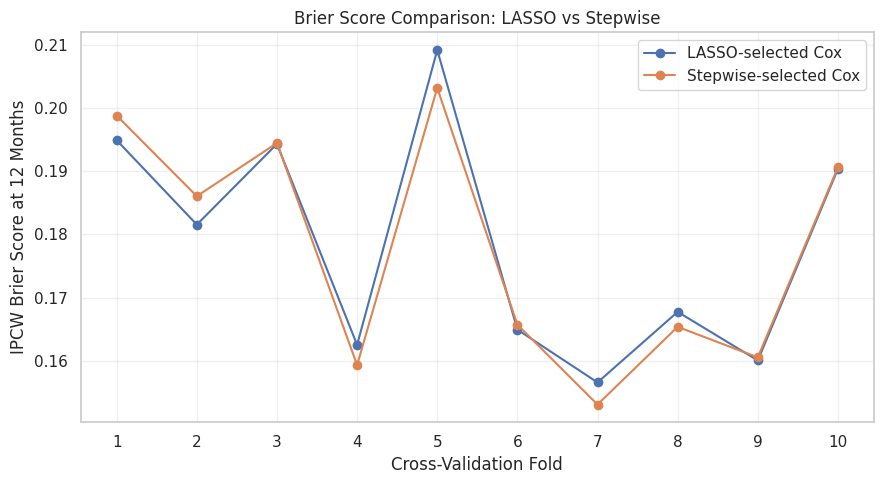

In [ ]:
# ============================================================
# 6.7.3 Fold-Level Brier Score Comparison Plot
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    fold_brier_comparison["Fold"],
    fold_brier_comparison["LASSO Brier Score"],
    marker="o",
    label="LASSO-selected Cox"
)

plt.plot(
    fold_brier_comparison["Fold"],
    fold_brier_comparison["Stepwise Brier Score"],
    marker="o",
    label="Stepwise-selected Cox"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("IPCW Brier Score at 12 Months")
plt.title(
    "Brier Score Comparison: "
    "LASSO vs Stepwise"
)

plt.xticks(
    fold_brier_comparison["Fold"]
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 6.7.4 Predictor-Set Comparison
# ============================================================

all_selected_predictors = sorted(
    set(lasso_final_predictors)
    | set(selected_stepwise_predictors)
)

predictor_set_comparison = pd.DataFrame({
    "Predictor": all_selected_predictors,
    "Selected by LASSO": [
        predictor in lasso_final_predictors
        for predictor in all_selected_predictors
    ],
    "Selected by Stepwise": [
        predictor in selected_stepwise_predictors
        for predictor in all_selected_predictors
    ]
})

predictor_set_comparison["Selection Agreement"] = np.where(
    predictor_set_comparison["Selected by LASSO"]
    == predictor_set_comparison["Selected by Stepwise"],
    "Agreement",
    "Different"
)

display(predictor_set_comparison)

shared_predictors = sorted(
    set(lasso_final_predictors)
    & set(selected_stepwise_predictors)
)

lasso_only_predictors = sorted(
    set(lasso_final_predictors)
    - set(selected_stepwise_predictors)
)

stepwise_only_predictors = sorted(
    set(selected_stepwise_predictors)
    - set(lasso_final_predictors)
)

print(f"Shared predictors: {len(shared_predictors)}")
for predictor in shared_predictors:
    print(f"- {predictor}")

print("\nSelected only by LASSO:")
if lasso_only_predictors:
    for predictor in lasso_only_predictors:
        print(f"- {predictor}")
else:
    print("- None")

print("\nSelected only by Stepwise:")
if stepwise_only_predictors:
    for predictor in stepwise_only_predictors:
        print(f"- {predictor}")
else:
    print("- None")

,Predictor,Selected by LASSO,Selected by Stepwise,Selection Agreement
0,age,True,True,Agreement
1,answered_calls_vs_employee_avg,True,True,Agreement
2,avg_annual_sick_increase,True,False,Different
3,call_center,True,True,Agreement
4,call_duration_vs_employee_avg,True,True,Agreement
5,calls_perhour_vs_center_avg,True,False,Different
6,children,True,True,Agreement
7,family_status,True,True,Agreement
8,part_time_percent,True,True,Agreement
9,relative_salary,True,True,Agreement


Shared predictors: 8
- age
- answered_calls_vs_employee_avg
- call_center
- call_duration_vs_employee_avg
- children
- family_status
- part_time_percent
- relative_salary

Selected only by LASSO:
- avg_annual_sick_increase
- calls_perhour_vs_center_avg

Selected only by Stepwise:
- None


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


מודל ה־Stepwise הציג Brier Score ממוצע נמוך במעט בהשוואה למודל ה־LASSO, ובמקביל כלל מספר קטן יותר של משתנים. בהתאם לקריטריון הבחירה שהוגדר מראש, נבחר מודל ה־Stepwise כמודל הסופי.

# חלק 7 – Multiple Imputation (MICE)

## 7.1 השלמת ערכים חסרים באמצעות MICE

לאחר השלמת ניתוח ה־Complete Case, בוצעה השלמה מרובה של הערכים החסרים באמצעות Multiple Imputation by Chained Equations ‏(MICE).

ההשלמה יושמה רק על שבעת משתני ה־KPI הנגזרים ששימשו כמועמדים למודל. משתני המקור ששימשו לחישוב מדדי ה־KPI לא הוכנסו למודל ולא שימשו כתוצרים סופיים של ההשלמה.

כדי לשמר הבדלים תפעוליים בין המוקדים, תהליך ההשלמה בוצע בנפרד בתוך כל מוקד. מודל ההשלמה התבסס על Bayesian Ridge Regression וכלל משתני עזר דמוגרפיים, תעסוקתיים וארגוניים, וכן את משך המעקב ואת סטטוס האירוע.

נוצרו חמישה מערכי נתונים מושלמים (`m = 5`). שימוש בדגימה מההתפלגות הפוסטריורית אפשר לשקף את אי־הוודאות בתהליך ההשלמה וליצור שונות בין מערכי הנתונים המושלמים.

In [ ]:
# ============================================================
# 7.1.1 Define MICE Variables and Examine Missingness
# ============================================================

# ------------------------------------------------------------
# Number of completed datasets
# ------------------------------------------------------------

MICE_M = 5
MICE_BASE_SEED = RANDOM_SEED

# ------------------------------------------------------------
# KPI-derived variables to be imputed
# ------------------------------------------------------------

MICE_KPI_COLUMNS = [
    "answered_calls_vs_center_avg",
    "answered_calls_vs_employee_avg",
    "call_duration_vs_center_avg",
    "call_duration_vs_employee_avg",
    "calls_perhour_vs_center_avg",
    "calls_perhour_vs_employee_avg",
    "pause_self3m_vs_selfannual"
]

# ------------------------------------------------------------
# Auxiliary variables used to predict missing KPI values
#
# The outcome and follow-up time are included as auxiliary
# information but are not themselves imputed.
# ------------------------------------------------------------

MICE_AUXILIARY_COLUMNS = [
    "gender",
    "age",
    "relative_salary",
    "children",
    "family_status",
    "Team_size",
    "part_time_percent",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase",
    TIME_COL,
    EVENT_COL
]

# ------------------------------------------------------------
# Categorical auxiliary variables
# ------------------------------------------------------------

MICE_CATEGORICAL_AUXILIARY_COLUMNS = [
    "gender",
    "children",
    "family_status",
    "Team_size",
    "avg_annual_vacation_increase",
    "avg_annual_sick_increase"
]

# ------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------

required_mice_columns = (
    [CENTER_COL]
    + MICE_KPI_COLUMNS
    + MICE_AUXILIARY_COLUMNS
)

missing_mice_columns = [
    column
    for column in required_mice_columns
    if column not in df_clean.columns
]

assert not missing_mice_columns, (
    "Required MICE columns are missing from df_clean: "
    f"{missing_mice_columns}"
)

assert MICE_M == 5, (
    "The study protocol requires five imputed datasets."
)

# ------------------------------------------------------------
# Verify that only KPI-derived variables are designated
# for imputation
# ------------------------------------------------------------

raw_kpi_columns = [
    "answered_calls_employee_avg_3month",
    "call_duration_employee_avg_3month",
    "calls_perhour_employee_avg_3month",
    "pause_center_employee_avg_3month",
    "answered_calls_employee_avg",
    "call_duration_employee_avg",
    "calls_perhour_employee_avg",
    "pause_center_employee_avg",
    "answered_calls_center_avg",
    "call_duration_center_avg",
    "calls_perhour_center_avg",
    "pause_center_avg"
]

assert not set(MICE_KPI_COLUMNS).intersection(raw_kpi_columns), (
    "Raw KPI variables must not be included among the "
    "variables designated for imputation."
)

# ------------------------------------------------------------
# Missingness summary by KPI variable
# ------------------------------------------------------------

mice_missingness_summary = pd.DataFrame({
    "Variable": MICE_KPI_COLUMNS,
    "Missing Values": [
        int(df_clean[column].isna().sum())
        for column in MICE_KPI_COLUMNS
    ],
    "Missing Percent": [
        df_clean[column].isna().mean() * 100
        for column in MICE_KPI_COLUMNS
    ],
    "Observed Values": [
        int(df_clean[column].notna().sum())
        for column in MICE_KPI_COLUMNS
    ]
})

mice_missingness_summary[
    "Missing Percent"
] = mice_missingness_summary[
    "Missing Percent"
].round(2)

display(mice_missingness_summary)

# ------------------------------------------------------------
# Missingness by call center
# ------------------------------------------------------------

mice_missingness_by_center = (
    df_clean
    .groupby(CENTER_COL, observed=True)[MICE_KPI_COLUMNS]
    .apply(lambda group: group.isna().sum())
)

display(mice_missingness_by_center)

# ------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------

total_kpi_missing_before_mice = int(
    df_clean[MICE_KPI_COLUMNS]
    .isna()
    .sum()
    .sum()
)

rows_with_any_kpi_missing = int(
    df_clean[MICE_KPI_COLUMNS]
    .isna()
    .any(axis=1)
    .sum()
)

complete_kpi_rows = int(
    df_clean[MICE_KPI_COLUMNS]
    .notna()
    .all(axis=1)
    .sum()
)

mice_initial_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Call centers",
        "KPI variables designated for imputation",
        "Total missing KPI values",
        "Rows with at least one missing KPI value",
        "Rows complete on all KPI variables",
        "Number of planned imputations"
    ],
    "Value": [
        len(df_clean),
        df_clean[CENTER_COL].nunique(dropna=True),
        len(MICE_KPI_COLUMNS),
        total_kpi_missing_before_mice,
        rows_with_any_kpi_missing,
        complete_kpi_rows,
        MICE_M
    ]
})

display(mice_initial_summary)

print("MICE variables and missingness were validated successfully.")

,Variable,Missing Values,Missing Percent,Observed Values
0,answered_calls_vs_center_avg,462,26.3800,1289
1,answered_calls_vs_employee_avg,462,26.3800,1289
2,call_duration_vs_center_avg,462,26.3800,1289
3,call_duration_vs_employee_avg,462,26.3800,1289
4,calls_perhour_vs_center_avg,462,26.3800,1289
5,calls_perhour_vs_employee_avg,462,26.3800,1289
6,pause_self3m_vs_selfannual,463,26.4400,1288


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,answered_calls_vs_center_avg,answered_calls_vs_employee_avg,call_duration_vs_center_avg,call_duration_vs_employee_avg,calls_perhour_vs_center_avg,calls_perhour_vs_employee_avg,pause_self3m_vs_selfannual
call_center,,,,,,,
1,24,24,24,24,24,24,24
2,7,7,7,7,7,7,7
3,82,82,82,82,82,82,82
4,123,123,123,123,123,123,123
5,92,92,92,92,92,92,92
6,49,49,49,49,49,49,50
7,85,85,85,85,85,85,85


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Value
0,Observations,1751
1,Call centers,7
2,KPI variables designated for imputation,7
3,Total missing KPI values,3235
4,Rows with at least one missing KPI value,463
5,Rows complete on all KPI variables,1288
6,Number of planned imputations,5


MICE variables and missingness were validated successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 7.1.2 יצירת מערכי הנתונים המושלמים

חמישה מערכי נתונים מושלמים נוצרו באמצעות `IterativeImputer`, המיישם תהליך השלמה איטרטיבי הדומה ל־MICE.

ההשלמה בוצעה בנפרד עבור כל מוקד באמצעות מודל `BayesianRidge`. לצורך יצירת שונות בין חמש ההשלמות הופעלה דגימה מההתפלגות הפוסטריורית (`sample_posterior=True`) ונעשה שימוש בזרע אקראי שונה עבור כל מערך נתונים.

רק הערכים החסרים בשבעת משתני ה־KPI הנגזרים הוחלפו. ערכי KPI שנצפו במקור, משתני העזר, משתנה האירוע ומשך המעקב נשמרו ללא שינוי.

In [ ]:
# ============================================================
# 7.1.2 Create Five MICE-Imputed Datasets by Call Center
# ============================================================

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge

# ------------------------------------------------------------
# MICE settings
# ------------------------------------------------------------

MICE_MAX_ITER = 20
MICE_INITIAL_STRATEGY = "median"
MICE_GROUP_COLUMN = CENTER_COL

# ------------------------------------------------------------
# Validate auxiliary-variable missingness
# ------------------------------------------------------------

mice_auxiliary_missingness = pd.DataFrame({
    "Variable": MICE_AUXILIARY_COLUMNS,
    "Missing Values": [
        int(df_clean[column].isna().sum())
        for column in MICE_AUXILIARY_COLUMNS
    ]
})

display(mice_auxiliary_missingness)

# Auxiliary variables are used as predictors.
# They are not copied back from the imputer.
print(
    "Total missing values among auxiliary variables:",
    int(
        df_clean[MICE_AUXILIARY_COLUMNS]
        .isna()
        .sum()
        .sum()
    )
)

# ------------------------------------------------------------
# Create one MICE-imputed dataset
# ------------------------------------------------------------

def create_one_mice_dataset(
    source_df,
    random_state
):

    completed_df = source_df.copy(deep=True)

    center_diagnostics = []

    for center_value in sorted(
        completed_df[MICE_GROUP_COLUMN]
        .dropna()
        .unique()
    ):

        center_mask = (
            completed_df[MICE_GROUP_COLUMN]
            == center_value
        )

        center_index = completed_df.index[
            center_mask
        ]

        # Variables used inside the imputation model
        imputation_columns = list(
            dict.fromkeys(
                MICE_KPI_COLUMNS
                + MICE_AUXILIARY_COLUMNS
            )
        )

        center_imputation_frame = (
            completed_df
            .loc[
                center_index,
                imputation_columns
            ]
            .copy()
        )

        # ----------------------------------------------------
        # Encode categorical auxiliary variables
        # ----------------------------------------------------

        categorical_columns_present = [
            column
            for column in MICE_CATEGORICAL_AUXILIARY_COLUMNS
            if column in center_imputation_frame.columns
        ]

        center_imputation_design = pd.get_dummies(
            center_imputation_frame,
            columns=categorical_columns_present,
            drop_first=True,
            dtype=float
        )

        # Convert every design column to numeric
        for column in center_imputation_design.columns:

            center_imputation_design[column] = (
                pd.to_numeric(
                    center_imputation_design[column],
                    errors="coerce"
                )
            )

        center_imputation_design = (
            center_imputation_design
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
        )

        missing_before_center = int(
            center_imputation_frame[
                MICE_KPI_COLUMNS
            ]
            .isna()
            .sum()
            .sum()
        )

        # ----------------------------------------------------
        # Skip centers with no missing KPI values
        # ----------------------------------------------------

        if missing_before_center == 0:

            center_diagnostics.append({
                "Call Center": center_value,
                "Observations": len(center_index),
                "Missing KPI Before": 0,
                "Missing KPI After": 0,
                "Iterations": 0
            })

            continue

        # ----------------------------------------------------
        # Fit MICE-like iterative imputer
        # ----------------------------------------------------

        center_imputer = IterativeImputer(
            estimator=BayesianRidge(),
            max_iter=MICE_MAX_ITER,
            sample_posterior=True,
            random_state=(
                random_state
                + int(center_value)
            ),
            initial_strategy=MICE_INITIAL_STRATEGY,
            skip_complete=True
        )

        imputed_array = (
            center_imputer
            .fit_transform(
                center_imputation_design
            )
        )

        imputed_design = pd.DataFrame(
            imputed_array,
            columns=center_imputation_design.columns,
            index=center_index
        )

        # ----------------------------------------------------
        # Copy back only missing KPI-derived values
        # ----------------------------------------------------

        for kpi_column in MICE_KPI_COLUMNS:

            originally_missing = (
                source_df
                .loc[
                    center_index,
                    kpi_column
                ]
                .isna()
            )

            rows_to_fill = center_index[
                originally_missing
            ]

            completed_df.loc[
                rows_to_fill,
                kpi_column
            ] = imputed_design.loc[
                rows_to_fill,
                kpi_column
            ]

        missing_after_center = int(
            completed_df
            .loc[
                center_index,
                MICE_KPI_COLUMNS
            ]
            .isna()
            .sum()
            .sum()
        )

        center_diagnostics.append({
            "Call Center": center_value,
            "Observations": len(center_index),
            "Missing KPI Before": missing_before_center,
            "Missing KPI After": missing_after_center,
            "Iterations": int(center_imputer.n_iter_)
        })

    center_diagnostics = pd.DataFrame(
        center_diagnostics
    )

    return completed_df, center_diagnostics


# ------------------------------------------------------------
# Generate m = 5 completed datasets
# ------------------------------------------------------------

mice_datasets = []
mice_diagnostics = []

for imputation_number in range(1, MICE_M + 1):

    imputation_seed = (
        MICE_BASE_SEED
        + imputation_number * 100
    )

    imputed_dataset, diagnostic_table = (
        create_one_mice_dataset(
            source_df=df_clean,
            random_state=imputation_seed
        )
    )

    diagnostic_table.insert(
        0,
        "Imputation",
        imputation_number
    )

    mice_datasets.append(
        imputed_dataset
    )

    mice_diagnostics.append(
        diagnostic_table
    )

    remaining_missing = int(
        imputed_dataset[MICE_KPI_COLUMNS]
        .isna()
        .sum()
        .sum()
    )

    print(
        f"Created MICE dataset "
        f"{imputation_number}/{MICE_M} | "
        f"Remaining missing KPI values: "
        f"{remaining_missing}"
    )

# ------------------------------------------------------------
# Combine diagnostics
# ------------------------------------------------------------

mice_diagnostics_table = pd.concat(
    mice_diagnostics,
    ignore_index=True
)

display(mice_diagnostics_table)

print(
    "\nFive MICE datasets were created successfully."
)

,Variable,Missing Values
0,gender,0
1,age,0
2,relative_salary,0
3,children,0
4,family_status,0
5,Team_size,0
6,part_time_percent,0
7,avg_annual_vacation_increase,0
8,avg_annual_sick_increase,0
9,time_in_company,0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Total missing values among auxiliary variables: 0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Created MICE dataset 1/5 | Remaining missing KPI values: 0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

... (6 outputs left out)

Created MICE dataset 5/5 | Remaining missing KPI values: 0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Imputation,Call Center,Observations,Missing KPI Before,Missing KPI After,Iterations
0,1,1,104,168,0,20
1,1,2,94,49,0,20
2,1,3,265,574,0,20
3,1,4,288,861,0,20
4,1,5,230,644,0,20
5,1,6,233,344,0,20
6,1,7,537,595,0,20
7,2,1,104,168,0,20
8,2,2,94,49,0,20
9,2,3,265,574,0,20



Five MICE datasets were created successfully.


In [ ]:
# ============================================================
# 7.1.3 Validate the Five MICE-Imputed Datasets
# ============================================================

mice_validation_rows = []

for imputation_number, imputed_dataset in enumerate(
    mice_datasets,
    start=1
):

    missing_kpi_after = int(
        imputed_dataset[MICE_KPI_COLUMNS]
        .isna()
        .sum()
        .sum()
    )

    missing_candidate_after = int(
        imputed_dataset[candidate_predictors]
        .isna()
        .sum()
        .sum()
    )

    # Observed KPI values must remain unchanged
    observed_values_changed = 0

    for kpi_column in MICE_KPI_COLUMNS:

        originally_observed = (
            df_clean[kpi_column]
            .notna()
        )

        changed_values = ~np.isclose(
            imputed_dataset.loc[
                originally_observed,
                kpi_column
            ].astype(float),
            df_clean.loc[
                originally_observed,
                kpi_column
            ].astype(float),
            rtol=0,
            atol=1e-12,
            equal_nan=True
        )

        observed_values_changed += int(
            changed_values.sum()
        )

    outcome_changed = not (
        imputed_dataset[
            [TIME_COL, EVENT_COL]
        ].equals(
            df_clean[
                [TIME_COL, EVENT_COL]
            ]
        )
    )

    mice_validation_rows.append({
        "Imputation": imputation_number,
        "Observations": len(imputed_dataset),
        "Missing KPI Values": missing_kpi_after,
        "Missing Candidate Values": (
            missing_candidate_after
        ),
        "Observed KPI Values Changed": (
            observed_values_changed
        ),
        "Outcome or Time Changed": outcome_changed
    })

mice_validation_summary = pd.DataFrame(
    mice_validation_rows
)

display(mice_validation_summary)

# ------------------------------------------------------------
# Formal validation assertions
# ------------------------------------------------------------

assert len(mice_datasets) == MICE_M, (
    "The number of imputed datasets is incorrect."
)

assert (
    mice_validation_summary[
        "Observations"
    ] == len(df_clean)
).all(), (
    "At least one imputed dataset has an incorrect "
    "number of observations."
)

assert (
    mice_validation_summary[
        "Missing KPI Values"
    ] == 0
).all(), (
    "Missing KPI values remain after imputation."
)

assert (
    mice_validation_summary[
        "Missing Candidate Values"
    ] == 0
).all(), (
    "Missing candidate-predictor values remain "
    "after imputation."
)

assert (
    mice_validation_summary[
        "Observed KPI Values Changed"
    ] == 0
).all(), (
    "At least one originally observed KPI value "
    "was changed."
)

assert not (
    mice_validation_summary[
        "Outcome or Time Changed"
    ]
).any(), (
    "The event indicator or follow-up time was changed."
)

print(
    "All five MICE datasets passed validation successfully."
)

,Imputation,Observations,Missing KPI Values,Missing Candidate Values,Observed KPI Values Changed,Outcome or Time Changed
0,1,1751,0,0,0,False
1,2,1751,0,0,0,False
2,3,1751,0,0,0,False
3,4,1751,0,0,0,False
4,5,1751,0,0,0,False


All five MICE datasets passed validation successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 7.1.4 בדיקת שונות בין מערכי הנתונים המושלמים

כדי לוודא שחמש ההשלמות משקפות את אי־הוודאות בתהליך ההשלמה, נבדקה השונות בין הערכים שהושלמו בחמשת מערכי הנתונים.

הבדיקה בוצעה רק בתאים שהיו חסרים במערך הנתונים המקורי. עבור כל משתנה חושבו ממוצע סטיית התקן וטווח סטיות התקן של הערכים שהושלמו עבור אותה תצפית לאורך חמש ההשלמות.

סטיית תקן גדולה מאפס מעידה כי ההשלמות אינן זהות וכי הדגימה מההתפלגות הפוסטריורית יצרה שונות בין מערכי הנתונים.

In [ ]:
# ============================================================
# 7.1.4 Assess Variation Across the Five MICE Datasets
# ============================================================

mice_variation_rows = []

for kpi_column in MICE_KPI_COLUMNS:

    originally_missing_mask = (
        df_clean[kpi_column].isna()
    )

    missing_indices = df_clean.index[
        originally_missing_mask
    ]

    imputed_values_across_datasets = pd.DataFrame({
        f"Imputation_{imputation_number}": (
            imputed_dataset.loc[
                missing_indices,
                kpi_column
            ].astype(float)
        )
        for imputation_number, imputed_dataset in enumerate(
            mice_datasets,
            start=1
        )
    })

    rowwise_sd = (
        imputed_values_across_datasets
        .std(axis=1, ddof=1)
    )

    mice_variation_rows.append({
        "Variable": kpi_column,
        "Originally Missing Values": len(missing_indices),
        "Mean SD Across Imputations": rowwise_sd.mean(),
        "Median SD Across Imputations": rowwise_sd.median(),
        "Minimum SD Across Imputations": rowwise_sd.min(),
        "Maximum SD Across Imputations": rowwise_sd.max(),
        "Rows with SD > 0": int((rowwise_sd > 0).sum()),
        "Percent Rows with SD > 0": (
            (rowwise_sd > 0).mean() * 100
        )
    })

mice_variation_summary = pd.DataFrame(
    mice_variation_rows
)

mice_variation_summary[
    [
        "Mean SD Across Imputations",
        "Median SD Across Imputations",
        "Minimum SD Across Imputations",
        "Maximum SD Across Imputations",
        "Percent Rows with SD > 0"
    ]
] = mice_variation_summary[
    [
        "Mean SD Across Imputations",
        "Median SD Across Imputations",
        "Minimum SD Across Imputations",
        "Maximum SD Across Imputations",
        "Percent Rows with SD > 0"
    ]
].round(6)

display(mice_variation_summary)

# ------------------------------------------------------------
# Formal checks
# ------------------------------------------------------------

assert (
    mice_variation_summary[
        "Rows with SD > 0"
    ] > 0
).all(), (
    "At least one KPI variable has identical imputations "
    "across all five datasets."
)

print(
    "Variation across the five MICE datasets "
    "was confirmed successfully."
)

,Variable,Originally Missing Values,Mean SD Across Imputations,Median SD Across Imputations,Minimum SD Across Imputations,Maximum SD Across Imputations,Rows with SD > 0,Percent Rows with SD > 0
0,answered_calls_vs_center_avg,462,187.1001,177.0497,28.0254,526.1598,462,100.0000
1,answered_calls_vs_employee_avg,462,121.9874,117.5319,8.0807,310.3052,462,100.0000
2,call_duration_vs_center_avg,462,187.3540,120.0647,25.7263,794.1660,462,100.0000
3,call_duration_vs_employee_avg,462,116.0108,75.3660,9.6381,442.1360,462,100.0000
4,calls_perhour_vs_center_avg,462,2.3745,2.3166,0.3412,6.2777,462,100.0000
5,calls_perhour_vs_employee_avg,462,1.7786,1.4175,0.2762,6.6279,462,100.0000
6,pause_self3m_vs_selfannual,463,0.1525,0.1413,0.0380,0.5078,463,100.0000


Variation across the five MICE datasets was confirmed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 7.1.5 השוואת התפלגות הערכים הנצפים והערכים שהושלמו

לצורך הערכת סבירות הערכים שהופקו בתהליך ההשלמה, הושוו התפלגויות הערכים שנצפו במערך הנתונים המקורי להתפלגויות הערכים שהושלמו בכל אחד מחמשת מערכי הנתונים.

ההשוואה בוצעה באמצעות עקומות צפיפות. עבור כל משתנה הוצגה התפלגות הערכים שנצפו במקור, לצד התפלגות הערכים שהושלמו בכל אחת מחמש ההשלמות.

דמיון כללי בין ההתפלגויות, לצד שונות מסוימת בין חמש ההשלמות, מעיד כי תהליך ההשלמה שמר על מבנה הנתונים ובמקביל שיקף את אי־הוודאות הנובעת מהערכים החסרים.

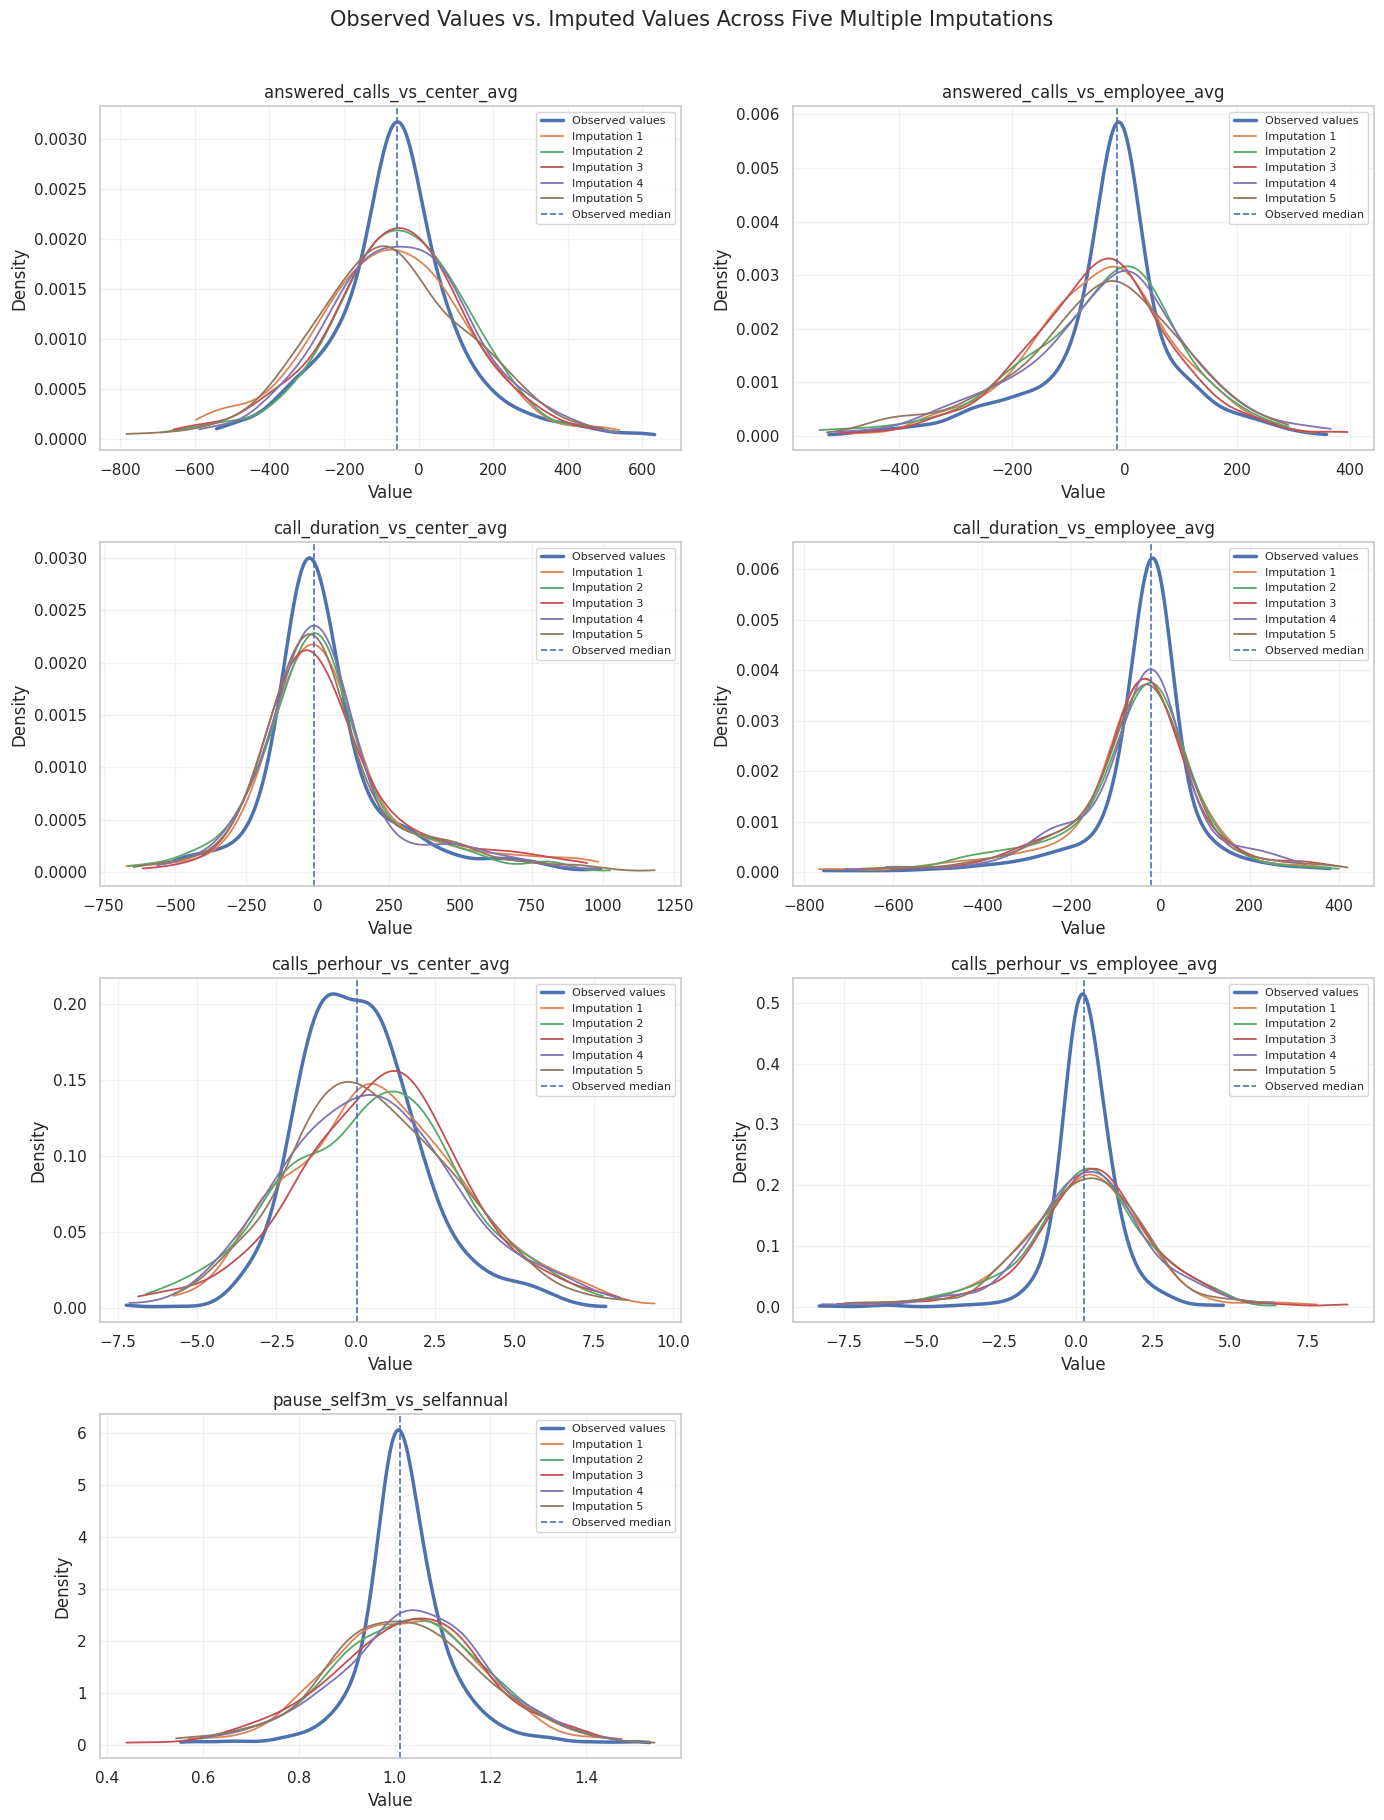

In [ ]:
# ============================================================
# 7.1.5 Compare Observed and Imputed Distributions
# Across the Five MICE Datasets
# ============================================================

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# ------------------------------------------------------------
# Helper function: safely draw a density curve
# ------------------------------------------------------------

def plot_density_curve(
    axis,
    values,
    label,
    linestyle="-",
    linewidth=1.5
):

    values = pd.to_numeric(
        pd.Series(values),
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    values = values[np.isfinite(values)]

    # KDE requires more than one value and non-zero variance
    if (
        len(values) < 2
        or np.isclose(np.std(values), 0)
    ):
        return

    density = gaussian_kde(values)

    lower_limit = np.percentile(values, 0.5)
    upper_limit = np.percentile(values, 99.5)

    if np.isclose(lower_limit, upper_limit):
        lower_limit = values.min()
        upper_limit = values.max()

    x_grid = np.linspace(
        lower_limit,
        upper_limit,
        300
    )

    axis.plot(
        x_grid,
        density(x_grid),
        label=label,
        linestyle=linestyle,
        linewidth=linewidth
    )


# ------------------------------------------------------------
# Plot layout
# ------------------------------------------------------------

number_of_variables = len(MICE_KPI_COLUMNS)
number_of_columns = 2
number_of_rows = math.ceil(
    number_of_variables / number_of_columns
)

fig, axes = plt.subplots(
    nrows=number_of_rows,
    ncols=number_of_columns,
    figsize=(14, 4.5 * number_of_rows)
)

axes = np.asarray(axes).reshape(-1)

# ------------------------------------------------------------
# Create one plot per KPI variable
# ------------------------------------------------------------

for plot_index, kpi_column in enumerate(
    MICE_KPI_COLUMNS
):

    axis = axes[plot_index]

    originally_observed_mask = (
        df_clean[kpi_column].notna()
    )

    originally_missing_mask = (
        df_clean[kpi_column].isna()
    )

    observed_values = df_clean.loc[
        originally_observed_mask,
        kpi_column
    ]

    # Observed values
    plot_density_curve(
        axis=axis,
        values=observed_values,
        label="Observed values",
        linewidth=2.5
    )

    # Imputed values from each completed dataset
    for imputation_number, imputed_dataset in enumerate(
        mice_datasets,
        start=1
    ):

        imputed_values = imputed_dataset.loc[
            originally_missing_mask,
            kpi_column
        ]

        plot_density_curve(
            axis=axis,
            values=imputed_values,
            label=f"Imputation {imputation_number}",
            linewidth=1.3
        )

    # Median of observed values
    observed_median = float(
        pd.to_numeric(
            observed_values,
            errors="coerce"
        ).median()
    )

    axis.axvline(
        observed_median,
        linestyle="--",
        linewidth=1.2,
        label="Observed median"
    )

    axis.set_title(kpi_column)
    axis.set_xlabel("Value")
    axis.set_ylabel("Density")
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)

# Remove unused plot area
for unused_axis in axes[number_of_variables:]:
    unused_axis.axis("off")

fig.suptitle(
    "Observed Values vs. Imputed Values "
    "Across Five Multiple Imputations",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_6068/1165300995.py:78: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot(
/tmp/ipykernel_6068/1165300995.py:78: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot(
/tmp/ipykernel_6068/1165300995.py:78: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot(
/tmp/ipykernel_6068/1165300995.py:78: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot(
/tmp/ipykernel_6068/1165300995.py:78: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has 

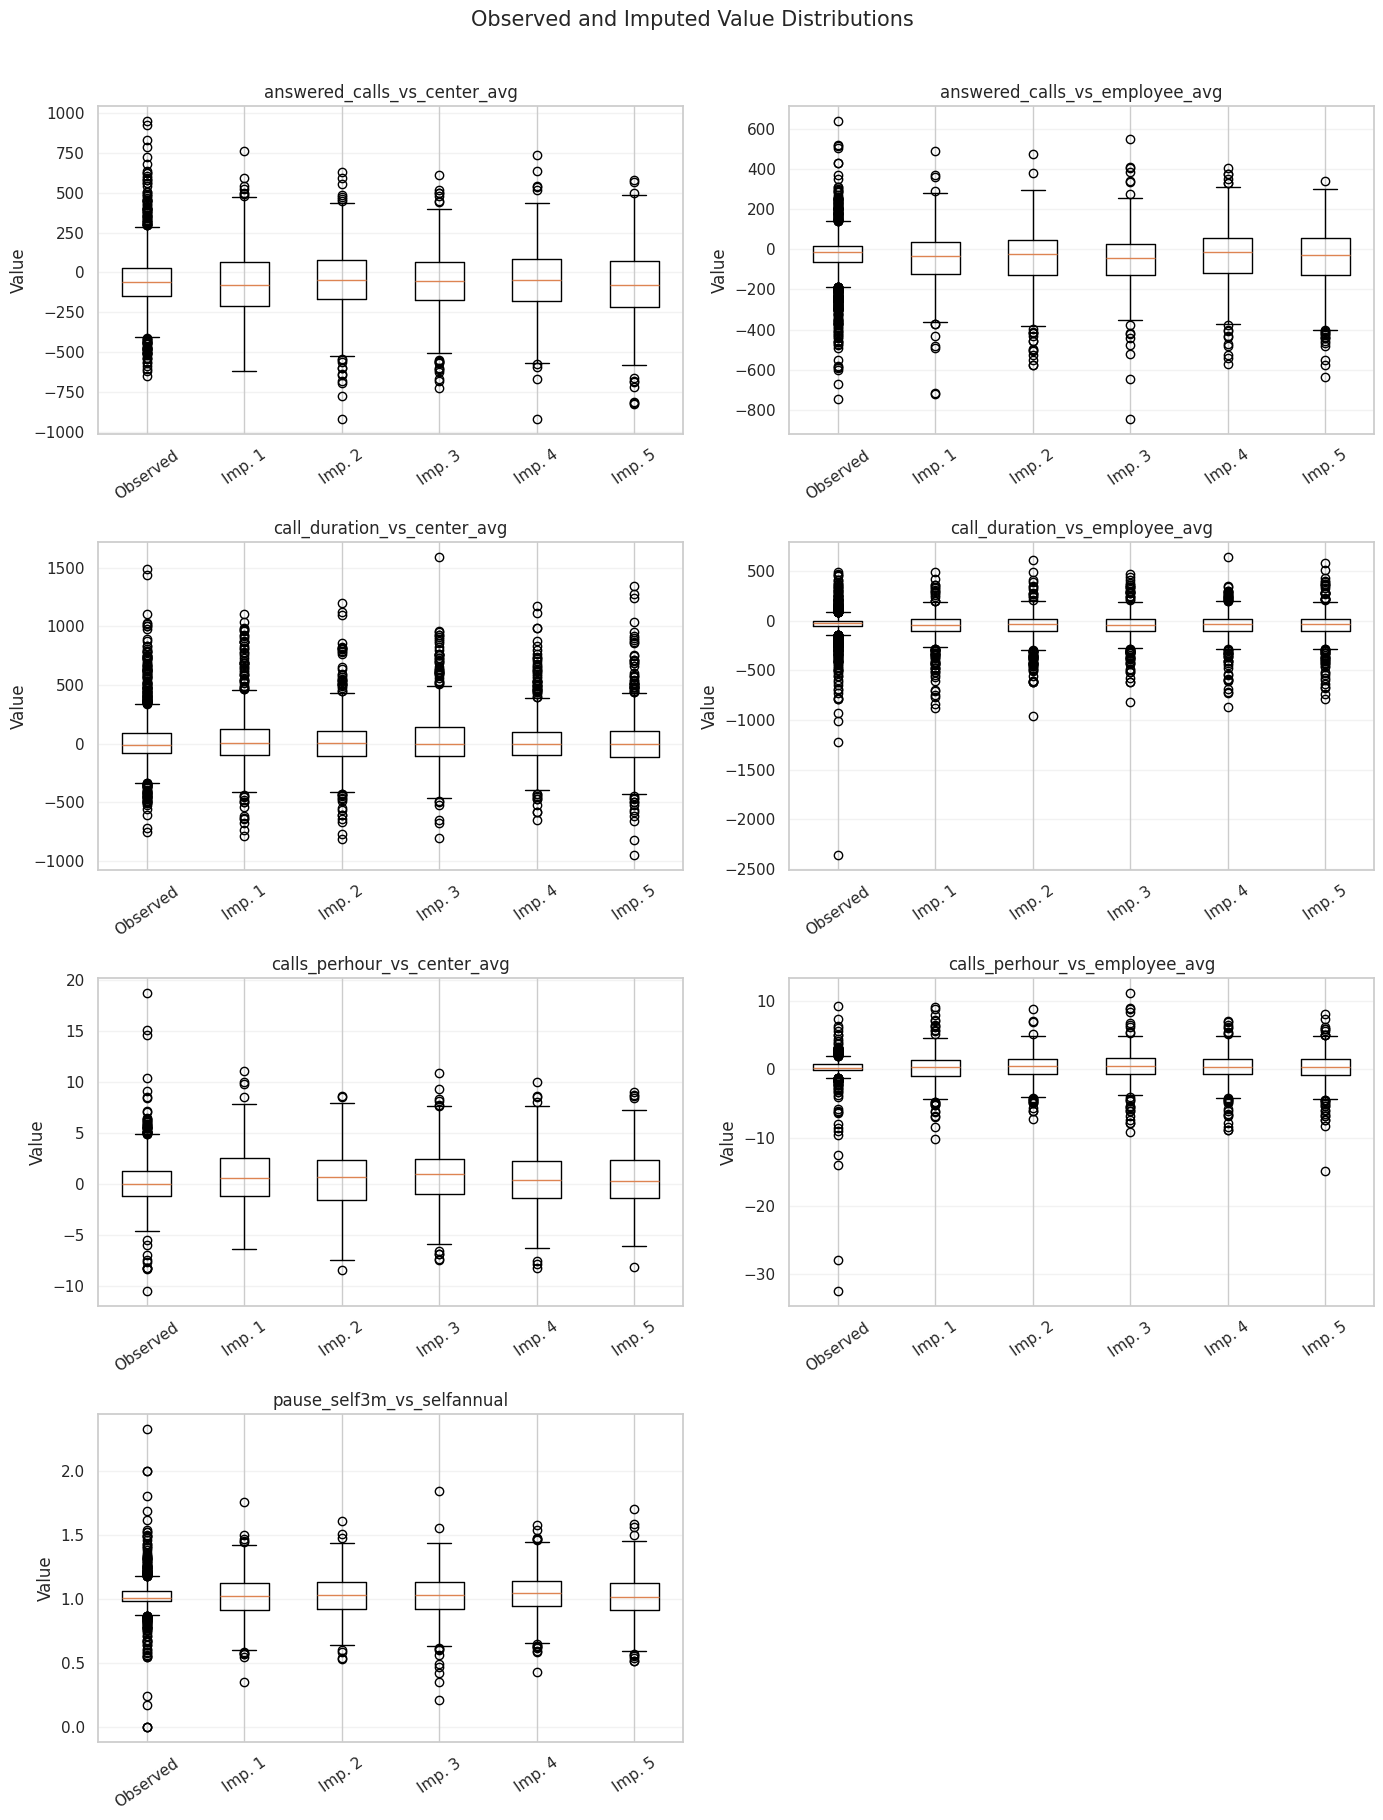

In [ ]:
# ============================================================
# 7.1.6 Boxplots of Observed and Imputed Values
# ============================================================

number_of_variables = len(MICE_KPI_COLUMNS)
number_of_columns = 2
number_of_rows = math.ceil(
    number_of_variables / number_of_columns
)

fig, axes = plt.subplots(
    nrows=number_of_rows,
    ncols=number_of_columns,
    figsize=(14, 4.5 * number_of_rows)
)

axes = np.asarray(axes).reshape(-1)

for plot_index, kpi_column in enumerate(
    MICE_KPI_COLUMNS
):

    axis = axes[plot_index]

    observed_mask = (
        df_clean[kpi_column].notna()
    )

    missing_mask = (
        df_clean[kpi_column].isna()
    )

    observed_values = (
        pd.to_numeric(
            df_clean.loc[
                observed_mask,
                kpi_column
            ],
            errors="coerce"
        )
        .dropna()
        .to_numpy(dtype=float)
    )

    boxplot_data = [
        observed_values
    ]

    boxplot_labels = [
        "Observed"
    ]

    for imputation_number, imputed_dataset in enumerate(
        mice_datasets,
        start=1
    ):

        imputed_values = (
            pd.to_numeric(
                imputed_dataset.loc[
                    missing_mask,
                    kpi_column
                ],
                errors="coerce"
            )
            .dropna()
            .to_numpy(dtype=float)
        )

        boxplot_data.append(
            imputed_values
        )

        boxplot_labels.append(
            f"Imp. {imputation_number}"
        )

    axis.boxplot(
        boxplot_data,
        labels=boxplot_labels,
        showfliers=True
    )

    axis.set_title(kpi_column)
    axis.set_ylabel("Value")
    axis.tick_params(
        axis="x",
        rotation=35
    )
    axis.grid(
        axis="y",
        alpha=0.25
    )

for unused_axis in axes[number_of_variables:]:
    unused_axis.axis("off")

fig.suptitle(
    "Observed and Imputed Value Distributions",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

### 7.2 התאמת המודל הסופי לכל אחד ממערכי ה־MICE

לאחר שנבחר מודל ה־Stepwise כמודל הסופי על בסיס ניתוח ה־Complete Case, אותו מודל הותאם בנפרד לכל אחד מחמשת מערכי הנתונים שהתקבלו בתהליך ה־Multiple Imputation.

בכל אחד ממערכי הנתונים נשמרה אותה קבוצת משתנים שנבחרה בשלב בחירת המשתנים, ללא ביצוע בחירת משתנים מחדש.

אמידת מקדמי המודל בוצעה באמצעות Cox Proportional Hazards Regression, ובהמשך אוחדו האומדנים מחמשת המודלים באמצעות Rubin's Rules.

In [ ]:
# ============================================================
# 7.2.1 Fit the Final Stepwise Cox Model
# Across the Five Imputed Datasets
# ============================================================

from lifelines import CoxPHFitter

# ------------------------------------------------------------
# Original predictors selected by Stepwise
# ------------------------------------------------------------

FINAL_STEPWISE_PREDICTORS = [

    "relative_salary",
    "children",
    "call_center",
    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg",
    "family_status",
    "age",
    "part_time_percent"

]

cox_models_mice = []

cox_summaries_mice = []

# ------------------------------------------------------------
# Fit Cox model on each imputed dataset
# ------------------------------------------------------------

for imputation_number, imputed_df in enumerate(
    mice_datasets,
    start=1
):

    X = imputed_df[
        FINAL_STEPWISE_PREDICTORS
    ].copy()

    X = pd.get_dummies(

        X,

        columns=[
            "children",
            "call_center",
            "family_status"
        ],

        drop_first=True,
        dtype=float

    )

    analysis_data = X.copy()

    analysis_data[TIME_COL] = (
        imputed_df[TIME_COL]
        .astype(float)
    )

    analysis_data[EVENT_COL] = (
        imputed_df[EVENT_COL]
        .astype(int)
    )

    model = CoxPHFitter()

    model.fit(

        analysis_data,

        duration_col=TIME_COL,

        event_col=EVENT_COL

    )

    summary = (
        model.summary
        .reset_index()
        .rename(
            columns={
                "covariate":"Variable"
            }
        )
    )

    summary["Imputation"] = (
        imputation_number
    )

    cox_models_mice.append(model)

    cox_summaries_mice.append(summary)

print(
    "Five Cox models fitted successfully."
)

print(
    f"Number of fitted models: {len(cox_models_mice)}"
)

Five Cox models fitted successfully.
Number of fitted models: 5


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 7.2.2 Validate Model Structure
# ============================================================

model_structure = []

for i, model in enumerate(
    cox_models_mice,
    start=1
):

    model_structure.append({

        "Imputation": i,

        "Model terms":
            len(model.params_),

        "Log-likelihood":
            model.log_likelihood_

    })

model_structure = pd.DataFrame(
    model_structure
)

display(model_structure)

assert (
    model_structure[
        "Model terms"
    ].nunique()==1
)

print(
    "\nAll five models contain the same predictors."
)

,Imputation,Model terms,Log-likelihood
0,1,13,"-8,503.2279"
1,2,13,"-8,507.2111"
2,3,13,"-8,505.5678"
3,4,13,"-8,507.7844"
4,5,13,"-8,508.1351"



All five models contain the same predictors.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 7.3 איחוד תוצאות המודלים באמצעות Rubin's Rules

לאחר התאמת מודל Cox בנפרד לכל אחד מחמשת מערכי הנתונים המושלמים, אוחדו אומדני המקדמים ושגיאות התקן באמצעות Rubin's Rules.

עבור כל משתנה חושב הממוצע של מקדמי הרגרסיה בין חמש ההשלמות. בנוסף חושבו השונות התוך־השלמתית, השונות הבין־השלמתית והשונות הכוללת.

על בסיס השונות הכוללת חושבו שגיאת התקן המאוחדת, יחס הסיכון, רווח סמך של 95% וערך ה־p עבור כל משתנה במודל הסופי.

In [ ]:
# ============================================================
# 7.3.1 Pool Cox Model Estimates Using Rubin's Rules
# ============================================================

from scipy.stats import t as student_t
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Extract coefficients and variance estimates
# ------------------------------------------------------------

pooled_rows = []

model_terms = list(
    cox_models_mice[0].params_.index
)

m = len(cox_models_mice)

for variable in model_terms:

    coefficient_estimates = np.array([
        model.params_.loc[variable]
        for model in cox_models_mice
    ], dtype=float)

    within_variances = np.array([
        model.variance_matrix_.loc[
            variable,
            variable
        ]
        for model in cox_models_mice
    ], dtype=float)

    # --------------------------------------------------------
    # Rubin's Rules
    # --------------------------------------------------------

    pooled_coefficient = (
        coefficient_estimates.mean()
    )

    within_imputation_variance = (
        within_variances.mean()
    )

    between_imputation_variance = (
        coefficient_estimates.var(ddof=1)
    )

    total_variance = (
        within_imputation_variance
        + (1 + 1 / m)
        * between_imputation_variance
    )

    pooled_standard_error = np.sqrt(
        total_variance
    )

    # --------------------------------------------------------
    # Degrees of freedom
    # Rubin's large-sample approximation
    # --------------------------------------------------------

    if between_imputation_variance > 0:

        relative_increase_variance = (
            (1 + 1 / m)
            * between_imputation_variance
            / within_imputation_variance
        )

        degrees_of_freedom = (
            (m - 1)
            * (
                1
                + 1 / relative_increase_variance
            ) ** 2
        )

    else:

        relative_increase_variance = 0.0
        degrees_of_freedom = np.inf

    # --------------------------------------------------------
    # Confidence interval and p-value
    # --------------------------------------------------------

    if np.isfinite(degrees_of_freedom):

        critical_value = student_t.ppf(
            0.975,
            df=degrees_of_freedom
        )

        test_statistic = (
            pooled_coefficient
            / pooled_standard_error
        )

        p_value = 2 * (
            1
            - student_t.cdf(
                abs(test_statistic),
                df=degrees_of_freedom
            )
        )

    else:

        critical_value = 1.959964

        test_statistic = (
            pooled_coefficient
            / pooled_standard_error
        )

        from scipy.stats import norm

        p_value = 2 * (
            1
            - norm.cdf(
                abs(test_statistic)
            )
        )

    lower_coefficient = (
        pooled_coefficient
        - critical_value
        * pooled_standard_error
    )

    upper_coefficient = (
        pooled_coefficient
        + critical_value
        * pooled_standard_error
    )

    pooled_rows.append({
        "Variable": variable,
        "Pooled Coefficient": pooled_coefficient,
        "Pooled Standard Error": pooled_standard_error,
        "Hazard Ratio": np.exp(
            pooled_coefficient
        ),
        "95% CI Lower": np.exp(
            lower_coefficient
        ),
        "95% CI Upper": np.exp(
            upper_coefficient
        ),
        "Test Statistic": test_statistic,
        "Degrees of Freedom": degrees_of_freedom,
        "P-value": p_value,
        "Within-Imputation Variance": (
            within_imputation_variance
        ),
        "Between-Imputation Variance": (
            between_imputation_variance
        ),
        "Total Variance": total_variance
    })

pooled_cox_results = pd.DataFrame(
    pooled_rows
)

# ------------------------------------------------------------
# Sort and format
# ------------------------------------------------------------

pooled_cox_results = (
    pooled_cox_results
    .sort_values("P-value")
    .reset_index(drop=True)
)

display_columns = [
    "Variable",
    "Pooled Coefficient",
    "Pooled Standard Error",
    "Hazard Ratio",
    "95% CI Lower",
    "95% CI Upper",
    "Test Statistic",
    "Degrees of Freedom",
    "P-value"
]

pooled_cox_results_display = (
    pooled_cox_results[
        display_columns
    ]
    .copy()
)

numeric_columns_to_round = [
    "Pooled Coefficient",
    "Pooled Standard Error",
    "Hazard Ratio",
    "95% CI Lower",
    "95% CI Upper",
    "Test Statistic",
    "Degrees of Freedom",
    "P-value"
]

pooled_cox_results_display[
    numeric_columns_to_round
] = pooled_cox_results_display[
    numeric_columns_to_round
].round(4)

display(
    pooled_cox_results_display
)

print(
    "Pooling using Rubin's Rules "
    "completed successfully."
)

,Variable,Pooled Coefficient,Pooled Standard Error,Hazard Ratio,95% CI Lower,95% CI Upper,Test Statistic,Degrees of Freedom,P-value
0,relative_salary,-4.4166,0.3374,0.0121,0.0062,0.0234,-13.0908,"3,886.6766",0.0000
1,call_center_2,-1.0298,0.1672,0.3571,0.2573,0.4956,-6.1574,"8,469.8348",0.0000
2,family_status_1,-0.5464,0.0918,0.5791,0.4837,0.6932,-5.9531,"2,257.7854",0.0000
3,age,-0.0350,0.0063,0.9656,0.9538,0.9775,-5.5958,"3,194.6546",0.0000
4,part_time_percent,0.6405,0.1339,1.8974,1.4594,2.4668,4.7842,"7,845.0850",0.0000
5,answered_calls_vs_employee_avg,0.0012,0.0002,1.0012,1.0007,1.0016,5.1062,92.1052,0.0000
6,call_duration_vs_employee_avg,0.0010,0.0002,1.0010,1.0006,1.0014,4.6877,49.4087,0.0000
7,children_1,-0.3983,0.1081,0.6715,0.5433,0.8299,-3.6860,"12,926.1416",0.0002
8,call_center_3,-0.2847,0.1348,0.7522,0.5776,0.9797,-2.1123,"25,901.7883",0.0347
9,call_center_5,0.1871,0.1479,1.2058,0.9018,1.6122,1.2651,592.8159,0.2063


Pooling using Rubin's Rules completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 7.3.2 Missing-Information Diagnostics
# ============================================================

missing_information_diagnostics = (
    pooled_cox_results[
        [
            "Variable",
            "Within-Imputation Variance",
            "Between-Imputation Variance",
            "Total Variance"
        ]
    ]
    .copy()
)

missing_information_diagnostics[
    "Relative Increase in Variance"
] = (
    (1 + 1 / m)
    * missing_information_diagnostics[
        "Between-Imputation Variance"
    ]
    / missing_information_diagnostics[
        "Within-Imputation Variance"
    ]
)

missing_information_diagnostics[
    "Fraction of Missing Information"
] = (
    (
        missing_information_diagnostics[
            "Relative Increase in Variance"
        ]
        + 2
        / (
            pooled_cox_results[
                "Degrees of Freedom"
            ]
            + 3
        )
    )
    /
    (
        missing_information_diagnostics[
            "Relative Increase in Variance"
        ]
        + 1
    )
)

missing_information_diagnostics[
    [
        "Within-Imputation Variance",
        "Between-Imputation Variance",
        "Total Variance",
        "Relative Increase in Variance",
        "Fraction of Missing Information"
    ]
] = missing_information_diagnostics[
    [
        "Within-Imputation Variance",
        "Between-Imputation Variance",
        "Total Variance",
        "Relative Increase in Variance",
        "Fraction of Missing Information"
    ]
].round(6)

display(
    missing_information_diagnostics
)

,Variable,Within-Imputation Variance,Between-Imputation Variance,Total Variance,Relative Increase in Variance,Fraction of Missing Information
0,relative_salary,0.1102,0.0030,0.1138,0.0331,0.0326
1,call_center_2,0.0274,0.0005,0.0280,0.0222,0.0220
2,family_status_1,0.0081,0.0003,0.0084,0.0439,0.0429
3,age,0.0000,0.0000,0.0000,0.0367,0.0360
4,part_time_percent,0.0175,0.0003,0.0179,0.0231,0.0228
5,answered_calls_vs_employee_avg,0.0000,0.0000,0.0000,0.2633,0.2250
6,call_duration_vs_employee_avg,0.0000,0.0000,0.0000,0.3977,0.3118
7,children_1,0.0115,0.0002,0.0117,0.0179,0.0177
8,call_center_3,0.0179,0.0002,0.0182,0.0126,0.0125
9,call_center_5,0.0201,0.0015,0.0219,0.0895,0.0852


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 8.1 בדיקת הנחת הסיכונים הפרופורציונליים

הנחת הסיכונים הפרופורציונליים נבדקה עבור המודל הסופי לאחר Multiple Imputation.

מאחר שהמודל הסופי התקבל באמצעות איחוד אומדנים מחמש השלמות (Rubin's Rules), מבחן Schoenfeld בוצע בנפרד עבור כל אחד מחמשת מודלי Cox.

לאחר מכן הושוו ערכי ה־p שהתקבלו בין ההשלמות לצורך בחינת עקביות הממצאים וזיהוי משתנים שעשויים להפר את הנחת הסיכונים הפרופורציונליים.

In [ ]:
# ============================================================
# 8.1.1 Schoenfeld Residual Test
# for the Final Cox Model
# ============================================================

from lifelines.statistics import proportional_hazard_test
import numpy as np
import pandas as pd

ph_results_list = []

for imputation_number, (model, dataset) in enumerate(
    zip(cox_models_mice, mice_datasets),
    start=1
):

    # --------------------------------------------------------
    # Recreate the exact design matrix used in the Cox model
    # --------------------------------------------------------

    X_ph = dataset[
        FINAL_STEPWISE_PREDICTORS
    ].copy()

    X_ph = pd.get_dummies(
        X_ph,
        columns=[
            "children",
            "call_center",
            "family_status"
        ],
        drop_first=True,
        dtype=float
    )

    # Explicit numeric conversion for every predictor
    for column in X_ph.columns:

        X_ph[column] = pd.to_numeric(
            X_ph[column],
            errors="coerce"
        ).astype(float)

    # --------------------------------------------------------
    # Add survival outcome
    # --------------------------------------------------------

    ph_analysis_data = X_ph.copy()

    ph_analysis_data[TIME_COL] = pd.to_numeric(
        dataset[TIME_COL],
        errors="coerce"
    ).astype(float)

    ph_analysis_data[EVENT_COL] = pd.to_numeric(
        dataset[EVENT_COL],
        errors="coerce"
    ).astype(int)

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    assert ph_analysis_data.isna().sum().sum() == 0, (
        f"Missing values found in imputation "
        f"{imputation_number}."
    )

    assert np.isfinite(
        ph_analysis_data.to_numpy(dtype=float)
    ).all(), (
        f"Invalid numeric values found in imputation "
        f"{imputation_number}."
    )

    expected_model_terms = list(
        model.params_.index
    )

    actual_model_terms = [
        column
        for column in ph_analysis_data.columns
        if column not in [TIME_COL, EVENT_COL]
    ]

    assert expected_model_terms == actual_model_terms, (
        f"Model-term mismatch in imputation "
        f"{imputation_number}.\n"
        f"Expected: {expected_model_terms}\n"
        f"Actual: {actual_model_terms}"
    )

    # --------------------------------------------------------
    # Schoenfeld residual test
    # --------------------------------------------------------

    ph_test = proportional_hazard_test(
        model,
        ph_analysis_data,
        time_transform="rank"
    )

    ph_imputation_summary = (
        ph_test.summary
        .reset_index()
        .rename(columns={
            "index": "Variable",
            "test_statistic": "Test Statistic",
            "p": "P-value",
            "-log2(p)": "-log2(P-value)"
        })
    )

    ph_imputation_summary[
        "Imputation"
    ] = imputation_number

    ph_results_list.append(
        ph_imputation_summary
    )

ph_results = pd.concat(
    ph_results_list,
    ignore_index=True
)

ph_results_display = ph_results[
    [
        "Imputation",
        "Variable",
        "Test Statistic",
        "P-value",
        "-log2(P-value)"
    ]
].copy()

ph_results_display[
    [
        "Test Statistic",
        "P-value",
        "-log2(P-value)"
    ]
] = ph_results_display[
    [
        "Test Statistic",
        "P-value",
        "-log2(P-value)"
    ]
].round(6)

display(ph_results_display)

print(
    "Schoenfeld residual tests completed successfully "
    "for all five imputations."
)

,Imputation,Variable,Test Statistic,P-value,-log2(P-value)
0,1,age,8.5461,0.0035,8.1739
1,1,answered_calls_vs_employee_avg,26.9350,0.0000,22.1803
2,1,call_center_2,2.5245,0.1121,3.1572
3,1,call_center_3,0.1506,0.6979,0.5188
4,1,call_center_4,0.1455,0.7028,0.5087
5,1,call_center_5,7.4124,0.0065,7.2703
6,1,call_center_6,7.1776,0.0074,7.0818
7,1,call_center_7,0.0062,0.9373,0.0933
8,1,call_duration_vs_employee_avg,36.8729,0.0000,29.5629
9,1,children_1,8.4169,0.0037,8.0715


Schoenfeld residual tests completed successfully for all five imputations.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 8.1.2 Summarize PH Tests
# ============================================================

ph_summary = (

    ph_results

    .pivot_table(

        index="Variable",

        columns="Imputation",

        values="P-value"

    )

)

ph_summary.columns = [
    f"Imputation {i}"
    for i in ph_summary.columns
]

ph_summary["Minimum p"] = (
    ph_summary.min(axis=1)
)

ph_summary["Median p"] = (
    ph_summary.median(axis=1)
)

ph_summary["Maximum p"] = (
    ph_summary.max(axis=1)
)

ph_summary["Significant (<0.05)"] = (

    (ph_summary.iloc[:,0:5] < 0.05)

    .sum(axis=1)

)

ph_summary = (
    ph_summary
    .sort_values(
        "Median p"
    )
)

display(
    ph_summary.round(4)
)

print(
    "\nSummary completed successfully."
)

,Imputation 1,Imputation 2,Imputation 3,Imputation 4,Imputation 5,Minimum p,Median p,Maximum p,Significant (<0.05)
Variable,,,,,,,,,
relative_salary,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5
call_duration_vs_employee_avg,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5
part_time_percent,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5
answered_calls_vs_employee_avg,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5
children_1,0.0037,0.0026,0.0025,0.0029,0.0014,0.0014,0.0026,0.0037,5
age,0.0035,0.0034,0.0076,0.0042,0.0035,0.0034,0.0035,0.0076,5
call_center_6,0.0074,0.0036,0.0107,0.0027,0.0051,0.0027,0.0044,0.0107,5
call_center_5,0.0065,0.0027,0.0107,0.0048,0.0088,0.0027,0.0056,0.0107,5
family_status_1,0.0185,0.0082,0.0162,0.0089,0.0306,0.0082,0.0125,0.0306,5



Summary completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 8.2 בדיקת ליניאריות המשתנים הרציפים

### 8.2 בדיקת ליניאריות המשתנים הרציפים

מודל Cox מניח כי כל משתנה רציף מקיים קשר ליניארי עם לוג־הסיכון, אלא אם מוגדרת עבורו צורת קשר אחרת.

לצורך בדיקת הנחה זו הושווה, עבור כל משתנה רציף, המודל הליניארי המקורי למודל חלופי שבו המשתנה יוצג באמצעות Restricted Cubic Spline.

ההשוואה בוצעה בנפרד בכל אחד מחמשת מערכי הנתונים המושלמים באמצעות מבחן Likelihood Ratio. שיפור מובהק בהתאמת המודל לאחר הוספת רכיבי ה־Spline עשוי להעיד כי הקשר הליניארי אינו מספק.

In [ ]:
FINAL_CONTINUOUS_PREDICTORS = [
    "relative_salary",
    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg",
    "age",
    "part_time_percent"
]

In [ ]:
# ============================================================
# 8.2.1 Test Linearity of Continuous Predictors
# Across the Five Imputed Datasets
# ============================================================

from lifelines import CoxPHFitter
from lifelines.exceptions import ConvergenceError
from scipy.stats import chi2
from patsy import dmatrix
import numpy as np
import pandas as pd

FINAL_CONTINUOUS_PREDICTORS = [
    "relative_salary",
    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg",
    "age",
    "part_time_percent"
]

FINAL_CATEGORICAL_PREDICTORS = [
    "children",
    "call_center",
    "family_status"
]

SPLINE_DF = 4
NUMERICAL_PENALIZER = 1e-6

linearity_results_rows = []

# ------------------------------------------------------------
# Helper: prepare the common final-model design matrix
# ------------------------------------------------------------

def prepare_final_model_design(dataset):

    design = dataset[
        FINAL_STEPWISE_PREDICTORS
    ].copy()

    design = pd.get_dummies(
        design,
        columns=FINAL_CATEGORICAL_PREDICTORS,
        drop_first=True,
        dtype=float
    )

    for column in design.columns:
        design[column] = pd.to_numeric(
            design[column],
            errors="coerce"
        ).astype(float)

    return design


# ------------------------------------------------------------
# Helper: fit Cox model with numerical fallback
# ------------------------------------------------------------

def fit_cox_with_fallback(model_data):

    try:

        model = CoxPHFitter(
            penalizer=0.0
        )

        model.fit(
            model_data,
            duration_col=TIME_COL,
            event_col=EVENT_COL
        )

        penalizer_used = 0.0

    except (
        ConvergenceError,
        np.linalg.LinAlgError
    ):

        model = CoxPHFitter(
            penalizer=NUMERICAL_PENALIZER
        )

        model.fit(
            model_data,
            duration_col=TIME_COL,
            event_col=EVENT_COL
        )

        penalizer_used = NUMERICAL_PENALIZER

    return model, penalizer_used


# ------------------------------------------------------------
# Compare linear and spline specifications
# ------------------------------------------------------------

for imputation_number, dataset in enumerate(
    mice_datasets,
    start=1
):

    base_design = prepare_final_model_design(
        dataset
    )

    # --------------------------------------------------------
    # Fit the linear final model once per imputation
    # --------------------------------------------------------

    linear_data = base_design.copy()

    linear_data[TIME_COL] = pd.to_numeric(
        dataset[TIME_COL],
        errors="coerce"
    ).astype(float)

    linear_data[EVENT_COL] = pd.to_numeric(
        dataset[EVENT_COL],
        errors="coerce"
    ).astype(int)

    linear_model, linear_penalizer_used = (
        fit_cox_with_fallback(
            linear_data
        )
    )

    for variable in FINAL_CONTINUOUS_PREDICTORS:

        # ----------------------------------------------------
        # Build a B-spline basis without an intercept
        # ----------------------------------------------------

        spline_basis = dmatrix(
            f"bs(x, df={SPLINE_DF}, degree=3, "
            f"include_intercept=False) - 1",
            {
                "x": pd.to_numeric(
                    dataset[variable],
                    errors="coerce"
                ).astype(float)
            },
            return_type="dataframe"
        )

        spline_basis.index = dataset.index

        spline_basis.columns = [
            f"{variable}_spline_{column_number}"
            for column_number in range(
                1,
                spline_basis.shape[1] + 1
            )
        ]

        spline_basis = spline_basis.astype(float)

        # Remove zero-variance spline columns if any
        zero_variance_spline_columns = [
            column
            for column in spline_basis.columns
            if spline_basis[column].nunique(
                dropna=True
            ) <= 1
        ]

        if zero_variance_spline_columns:

            spline_basis = spline_basis.drop(
                columns=zero_variance_spline_columns
            )

        assert spline_basis.shape[1] >= 2, (
            f"Too few spline columns remained for "
            f"{variable}, imputation {imputation_number}."
        )

        # ----------------------------------------------------
        # Replace the original linear term with spline terms
        # ----------------------------------------------------

        spline_data = base_design.drop(
            columns=[variable]
        ).copy()

        spline_data = pd.concat(
            [
                spline_data,
                spline_basis
            ],
            axis=1
        )

        spline_data[TIME_COL] = pd.to_numeric(
            dataset[TIME_COL],
            errors="coerce"
        ).astype(float)

        spline_data[EVENT_COL] = pd.to_numeric(
            dataset[EVENT_COL],
            errors="coerce"
        ).astype(int)

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        assert spline_data.isna().sum().sum() == 0, (
            f"Missing values in spline model for "
            f"{variable}, imputation {imputation_number}."
        )

        assert np.isfinite(
            spline_data.to_numpy(dtype=float)
        ).all(), (
            f"Invalid values in spline model for "
            f"{variable}, imputation {imputation_number}."
        )

        zero_variance_model_columns = [
            column
            for column in spline_data.columns
            if column not in [TIME_COL, EVENT_COL]
            and spline_data[column].nunique(
                dropna=True
            ) <= 1
        ]

        if zero_variance_model_columns:

            spline_data = spline_data.drop(
                columns=zero_variance_model_columns
            )

        # ----------------------------------------------------
        # Fit spline model
        # ----------------------------------------------------

        spline_model, spline_penalizer_used = (
            fit_cox_with_fallback(
                spline_data
            )
        )

        # ----------------------------------------------------
        # Likelihood-ratio comparison
        # ----------------------------------------------------

        likelihood_ratio_statistic = (
            2
            * (
                spline_model.log_likelihood_
                - linear_model.log_likelihood_
            )
        )

        likelihood_ratio_statistic = max(
            likelihood_ratio_statistic,
            0.0
        )

        additional_degrees_of_freedom = (
            spline_basis.shape[1] - 1
        )

        p_value = chi2.sf(
            likelihood_ratio_statistic,
            df=additional_degrees_of_freedom
        )

        linearity_results_rows.append({
            "Imputation": imputation_number,
            "Variable": variable,
            "Linear Log-Likelihood": (
                linear_model.log_likelihood_
            ),
            "Spline Log-Likelihood": (
                spline_model.log_likelihood_
            ),
            "Likelihood Ratio Statistic": (
                likelihood_ratio_statistic
            ),
            "Additional Degrees of Freedom": (
                additional_degrees_of_freedom
            ),
            "P-value": p_value,
            "Evidence of Nonlinearity": (
                p_value < 0.05
            ),
            "Linear Penalizer Used": (
                linear_penalizer_used
            ),
            "Spline Penalizer Used": (
                spline_penalizer_used
            )
        })

linearity_results = pd.DataFrame(
    linearity_results_rows
)

linearity_results_display = (
    linearity_results.copy()
)

linearity_results_display[
    [
        "Linear Log-Likelihood",
        "Spline Log-Likelihood",
        "Likelihood Ratio Statistic",
        "P-value",
        "Linear Penalizer Used",
        "Spline Penalizer Used"
    ]
] = linearity_results_display[
    [
        "Linear Log-Likelihood",
        "Spline Log-Likelihood",
        "Likelihood Ratio Statistic",
        "P-value",
        "Linear Penalizer Used",
        "Spline Penalizer Used"
    ]
].round(6)

display(linearity_results_display)

print(
    "Linearity tests were completed successfully "
    "for all continuous predictors and imputations."
)

,Imputation,Variable,Linear Log-Likelihood,Spline Log-Likelihood,Likelihood Ratio Statistic,Additional Degrees of Freedom,P-value,Evidence of Nonlinearity,Linear Penalizer Used,Spline Penalizer Used
0,1,relative_salary,"-8,503.2279","-8,481.1629",44.1299,3,0.0000,True,0.0000,0.0000
1,1,answered_calls_vs_employee_avg,"-8,503.2279","-8,500.6553",5.1451,3,0.1615,False,0.0000,0.0000
2,1,call_duration_vs_employee_avg,"-8,503.2279","-8,498.6585",9.1387,3,0.0275,True,0.0000,0.0000
3,1,age,"-8,503.2279","-8,495.1646",16.1265,3,0.0011,True,0.0000,0.0000
4,1,part_time_percent,"-8,503.2279","-8,491.6065",23.2427,3,0.0000,True,0.0000,0.0000
5,2,relative_salary,"-8,507.2111","-8,484.8188",44.7846,3,0.0000,True,0.0000,0.0000
6,2,answered_calls_vs_employee_avg,"-8,507.2111","-8,504.5035",5.4152,3,0.1438,False,0.0000,0.0000
7,2,call_duration_vs_employee_avg,"-8,507.2111","-8,503.5692",7.2837,3,0.0634,False,0.0000,0.0000
8,2,age,"-8,507.2111","-8,499.3309",15.7603,3,0.0013,True,0.0000,0.0000
9,2,part_time_percent,"-8,507.2111","-8,496.6677",21.0867,3,0.0001,True,0.0000,0.0000


Linearity tests were completed successfully for all continuous predictors and imputations.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 8.2.2 Summarize Linearity Results
# Across the Five Imputations
# ============================================================

linearity_summary = (
    linearity_results
    .pivot_table(
        index="Variable",
        columns="Imputation",
        values="P-value"
    )
)

linearity_summary.columns = [
    f"Imputation {column}"
    for column in linearity_summary.columns
]

imputation_p_columns = [
    f"Imputation {number}"
    for number in range(1, MICE_M + 1)
]

linearity_summary["Minimum p"] = (
    linearity_summary[
        imputation_p_columns
    ].min(axis=1)
)

linearity_summary["Median p"] = (
    linearity_summary[
        imputation_p_columns
    ].median(axis=1)
)

linearity_summary["Maximum p"] = (
    linearity_summary[
        imputation_p_columns
    ].max(axis=1)
)

linearity_summary[
    "Imputations with p < 0.05"
] = (
    linearity_summary[
        imputation_p_columns
    ]
    .lt(0.05)
    .sum(axis=1)
)

linearity_summary = (
    linearity_summary
    .sort_values(
        [
            "Imputations with p < 0.05",
            "Median p"
        ],
        ascending=[
            False,
            True
        ]
    )
)

display(
    linearity_summary.round(6)
)

print(
    "Linearity summary completed successfully."
)

,Imputation 1,Imputation 2,Imputation 3,Imputation 4,Imputation 5,Minimum p,Median p,Maximum p,Imputations with p < 0.05
Variable,,,,,,,,,
relative_salary,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5
part_time_percent,0.0000,0.0001,0.0001,0.0000,0.0001,0.0000,0.0001,0.0001,5
age,0.0011,0.0013,0.0008,0.0007,0.0009,0.0007,0.0009,0.0013,5
call_duration_vs_employee_avg,0.0275,0.0634,0.1889,0.0625,0.1887,0.0275,0.0634,0.1889,1
answered_calls_vs_employee_avg,0.1615,0.1438,0.1378,0.0348,0.0986,0.0348,0.1378,0.1615,1


Linearity summary completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 8.3 בחינה משלימה של צורת הקשר במשתנים שנמצאו לא־ליניאריים

בדיקת הליניאריות הצביעה על עדות לאי־ליניאריות עבור גיל, שכר יחסי ואחוז משרה. לצורך בחינה אבחונית נוספת חושבו נקודות קשר אפשריות עבור גיל ושכר יחסי. לא הותאם מודל סופי חדש באמצעות Splines, מאחר שמטרת הניתוח הייתה לבדוק ולדווח על הנחות המודל ולא לשנות את מפרט המודל שנבחר.

In [ ]:
# ============================================================
# Examine the Distribution of part_time_percent
# ============================================================

part_time_diagnostic = pd.DataFrame({
    "Metric": [
        "Observations",
        "Unique values",
        "Mean",
        "Standard deviation",
        "Minimum",
        "25th percentile",
        "Median",
        "75th percentile",
        "Maximum",
        "Exactly 1.0",
        "Percent exactly 1.0"
    ],
    "Value": [
        df_clean["part_time_percent"].notna().sum(),
        df_clean["part_time_percent"].nunique(dropna=True),
        df_clean["part_time_percent"].mean(),
        df_clean["part_time_percent"].std(),
        df_clean["part_time_percent"].min(),
        df_clean["part_time_percent"].quantile(0.25),
        df_clean["part_time_percent"].median(),
        df_clean["part_time_percent"].quantile(0.75),
        df_clean["part_time_percent"].max(),
        int(np.isclose(
            df_clean["part_time_percent"].astype(float),
            1.0
        ).sum()),
        np.isclose(
            df_clean["part_time_percent"].astype(float),
            1.0
        ).mean() * 100
    ]
})

display(part_time_diagnostic.round(4))

print("\nMost frequent values:")

display(
    df_clean["part_time_percent"]
    .value_counts(dropna=False)
    .head(15)
    .rename_axis("part_time_percent")
    .reset_index(name="Frequency")
)

,Metric,Value
0,Observations,"1,751.0000"
1,Unique values,758.0000
2,Mean,0.8750
3,Standard deviation,0.2506
4,Minimum,0.0298
5,25th percentile,0.7497
6,Median,1.0000
7,75th percentile,1.0000
8,Maximum,1.7695
9,Exactly 1.0,968.0000



Most frequent values:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,part_time_percent,Frequency
0,1.0000,968
1,0.9400,4
2,0.7283,3
3,0.8800,3
4,0.8238,3
5,0.6343,3
6,0.6723,2
7,0.7374,2
8,0.7148,2
9,0.7523,2


In [ ]:
# ============================================================
# 8.3.1 Define Fixed Knots for Restricted Cubic Splines
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Variables evaluated using Restricted Cubic Splines
# ------------------------------------------------------------

FINAL_SPLINE_PREDICTORS = [
    "relative_salary",
    "age"
]

# Continuous variables retained in linear form
FINAL_LINEAR_PREDICTORS = [
    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg",
    "part_time_percent"
]

# part_time_percent was not evaluated using restricted cubic
# splines because more than half of the observations had the
# identical value 1.0, producing duplicated knot locations.

# Internal-knot percentiles
RCS_KNOT_PERCENTILES = [
    0.10,
    0.50,
    0.90
]

# ------------------------------------------------------------
# Validate spline variables
# ------------------------------------------------------------

missing_spline_variables = [
    variable
    for variable in FINAL_SPLINE_PREDICTORS
    if variable not in df_clean.columns
]

assert not missing_spline_variables, (
    "Spline variables are missing from df_clean: "
    f"{missing_spline_variables}"
)

assert (
    df_clean[FINAL_SPLINE_PREDICTORS]
    .isna()
    .sum()
    .sum()
    == 0
), (
    "At least one spline variable contains missing values."
)

# ------------------------------------------------------------
# Calculate fixed internal and boundary knots
# ------------------------------------------------------------

fixed_rcs_specifications = {}
fixed_rcs_rows = []

for variable in FINAL_SPLINE_PREDICTORS:

    values = pd.to_numeric(
        df_clean[variable],
        errors="coerce"
    ).astype(float)

    assert values.notna().all(), (
        f"{variable} contains non-numeric or missing values."
    )

    assert np.isfinite(values).all(), (
        f"{variable} contains infinite values."
    )

    internal_knots = values.quantile(
        RCS_KNOT_PERCENTILES
    ).to_numpy(dtype=float)

    lower_boundary = float(
        values.min()
    )

    upper_boundary = float(
        values.max()
    )

    all_knot_values = np.concatenate([
        [lower_boundary],
        internal_knots,
        [upper_boundary]
    ])

    assert np.all(
        np.diff(all_knot_values) > 0
    ), (
        f"The knots for {variable} are not strictly increasing: "
        f"{all_knot_values}"
    )

    fixed_rcs_specifications[variable] = {
        "internal_knots": internal_knots.tolist(),
        "lower_boundary": lower_boundary,
        "upper_boundary": upper_boundary
    }

    fixed_rcs_rows.append({
        "Variable": variable,
        "Lower Boundary": lower_boundary,
        "Knot 1 (10th percentile)": internal_knots[0],
        "Knot 2 (50th percentile)": internal_knots[1],
        "Knot 3 (90th percentile)": internal_knots[2],
        "Upper Boundary": upper_boundary,
        "Unique Values": int(
            values.nunique()
        )
    })

# ------------------------------------------------------------
# Display fixed spline specifications
# ------------------------------------------------------------

fixed_rcs_table = pd.DataFrame(
    fixed_rcs_rows
)

numeric_rcs_columns = [
    "Lower Boundary",
    "Knot 1 (10th percentile)",
    "Knot 2 (50th percentile)",
    "Knot 3 (90th percentile)",
    "Upper Boundary"
]

fixed_rcs_table[
    numeric_rcs_columns
] = fixed_rcs_table[
    numeric_rcs_columns
].round(6)

display(fixed_rcs_table)

print("\nFixed Restricted Cubic Spline specifications:")

for variable, specification in (
    fixed_rcs_specifications.items()
):

    print(f"\n{variable}")
    print(
        "  Internal knots:",
        specification["internal_knots"]
    )
    print(
        "  Lower boundary:",
        specification["lower_boundary"]
    )
    print(
        "  Upper boundary:",
        specification["upper_boundary"]
    )

print(
    "\nFixed spline knots were defined successfully."
)

,Variable,Lower Boundary,Knot 1 (10th percentile),Knot 2 (50th percentile),Knot 3 (90th percentile),Upper Boundary,Unique Values
0,relative_salary,0.9425,1.0013,1.0947,1.2385,2.2247,1512
1,age,17.0000,22.0000,27.0000,35.0000,61.0000,40



Fixed Restricted Cubic Spline specifications:

relative_salary
  Internal knots: [1.0012628236744867, 1.0947245283018867, 1.238479017405243]
  Lower boundary: 0.942513800973466
  Upper boundary: 2.2246837351246462

age
  Internal knots: [22.0, 27.0, 35.0]
  Lower boundary: 17.0
  Upper boundary: 61.0

Fixed spline knots were defined successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


ממצאים עיקריים

בדיקת הליניאריות בוצעה באמצעות השוואת מודל ליניארי למודל הכולל פונקציית Spline, בנפרד בכל אחד מחמשת מערכי הנתונים המושלמים.

נמצאה עדות עקבית לקשר לא־ליניארי עבור relative_salary, ‏age ו־part_time_percent, כאשר המודל הכולל רכיבי Spline הציג התאמה טובה יותר בכל חמש ההשלמות.

עבור answered_calls_vs_employee_avg ו־call_duration_vs_employee_avg לא נמצאה עדות עקבית לאי־ליניאריות, שכן תוצאה מובהקת התקבלה רק באחת מחמש ההשלמות.

ממצאים אלה מצביעים על כך שיש לנקוט זהירות בפרשנות יחס הסיכון הקבוע ליחידת שינוי במשתנים relative_salary, ‏age ו־part_time_percent. מאחר שמטרת הבדיקה במחקר הייתה להעריך ולדווח על הנחות המודל, ולא לבצע בחירה מחודשת או שינוי של מפרט המודל לאחר בחירתו, נשמר המודל הסופי במבנהו המקורי.

 PH
ממצאים עיקריים

מבחן המבוסס על Schoenfeld Residuals הצביע על עדות עקבית להפרת הנחת הסיכונים הפרופורציונליים עבור מספר מונחים במודל, ובהם relative_salary, ‏age, ‏part_time_percent, שני משתני ה־KPI, ‏children, ‏family_status וחלק מרמות המשתנה call_center.

עבור חלק מהמשתנים הרציפים שנמצאו מפרים את הנחת הסיכונים הפרופורציונליים נמצאה גם עדות לאי־ליניאריות. לפיכך, ייתכן שחלק מתוצאות מבחן Schoenfeld משקפות גם מפרט לא־ליניארי שאינו מיוצג במלואו במודל.

הממצאים אינם מבטלים את השימוש במודל, אך מצביעים על כך שיש לפרש את יחסי הסיכון כאומדנים ממוצעים לאורך תקופת המעקב, ולא בהכרח כאפקטים קבועים לחלוטין בכל נקודת זמן.

### 8.4 בדיקת מולטיקולינאריות

לצורך בחינת קיומה של מולטיקולינאריות בין המשתנים המסבירים חושב עבור כל משתנה מדד Variance Inflation Factor (VIF).

ערכי VIF גבוהים עשויים להעיד על תלות ליניארית בין משתנים מסבירים העלולה לגרום לאי־יציבות באמידת המקדמים.

בהתאם להמלצות המקובלות, ערכי VIF הגדולים מ־5 נחשבו כעדות אפשרית למולטיקולינאריות משמעותית.

In [ ]:
# ============================================================
# 8.4.1 Multicollinearity Assessment
# Corrected VIF and Correlation Diagnostics
# ============================================================

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)
from statsmodels.tools.tools import add_constant
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Create the predictor matrix from the first imputed dataset
# ------------------------------------------------------------

vif_data = mice_datasets[0][
    FINAL_STEPWISE_PREDICTORS
].copy()

vif_data = pd.get_dummies(
    vif_data,
    columns=[
        "children",
        "family_status",
        "call_center"
    ],
    drop_first=True,
    dtype=float
)

# Explicit numeric conversion
for column in vif_data.columns:

    vif_data[column] = pd.to_numeric(
        vif_data[column],
        errors="coerce"
    ).astype(float)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert vif_data.isna().sum().sum() == 0, (
    "The VIF dataset contains missing values."
)

assert np.isfinite(
    vif_data.to_numpy(dtype=float)
).all(), (
    "The VIF dataset contains infinite or invalid values."
)

zero_variance_columns = [
    column
    for column in vif_data.columns
    if vif_data[column].nunique(dropna=True) <= 1
]

assert not zero_variance_columns, (
    "Zero-variance columns were found: "
    f"{zero_variance_columns}"
)

# ------------------------------------------------------------
# Add an intercept before calculating VIF
#
# The intercept is required for the standard VIF calculation.
# It will not be reported in the final table.
# ------------------------------------------------------------

vif_data_with_constant = add_constant(
    vif_data,
    has_constant="add"
)

vif_results = pd.DataFrame({
    "Variable": vif_data_with_constant.columns,
    "VIF": [
        variance_inflation_factor(
            vif_data_with_constant.to_numpy(dtype=float),
            column_index
        )
        for column_index in range(
            vif_data_with_constant.shape[1]
        )
    ]
})

# Remove the intercept from the displayed results
vif_results = vif_results.loc[
    vif_results["Variable"] != "const"
].copy()

# ------------------------------------------------------------
# Classify VIF values
# ------------------------------------------------------------

vif_results["Assessment"] = np.select(
    [
        vif_results["VIF"] >= 10,
        vif_results["VIF"] >= 5
    ],
    [
        "High multicollinearity",
        "Possible multicollinearity"
    ],
    default="Acceptable"
)

vif_results = (
    vif_results
    .sort_values(
        "VIF",
        ascending=False
    )
    .reset_index(drop=True)
)

vif_results["VIF"] = (
    vif_results["VIF"]
    .round(3)
)

display(vif_results)

print("-" * 50)
print(
    "Maximum corrected VIF:",
    round(vif_results["VIF"].max(), 3)
)
print(
    "Variables with VIF >= 5:",
    int((vif_results["VIF"] >= 5).sum())
)
print(
    "Variables with VIF >= 10:",
    int((vif_results["VIF"] >= 10).sum())
)

,Variable,VIF,Assessment
0,call_center_7,4.3820,Acceptable
1,call_center_3,3.2300,Acceptable
2,call_center_4,3.2280,Acceptable
3,call_center_5,3.1380,Acceptable
4,call_center_6,3.0970,Acceptable
5,children_1,2.5100,Acceptable
6,family_status_1,2.2640,Acceptable
7,call_center_2,1.8330,Acceptable
8,age,1.2060,Acceptable
9,part_time_percent,1.1930,Acceptable


--------------------------------------------------
Maximum corrected VIF: 4.382
Variables with VIF >= 5: 0
Variables with VIF >= 10: 0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 8.4.2 Correlation Diagnostics
# Continuous Predictors in the Final Model
# ============================================================

final_continuous_for_correlation = [
    "relative_salary",
    "age",
    "part_time_percent",
    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg"
]

continuous_correlation_matrix = (
    mice_datasets[0][
        final_continuous_for_correlation
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .corr(method="pearson")
)

display(
    continuous_correlation_matrix.round(3)
)

# ------------------------------------------------------------
# Identify strong pairwise correlations
# ------------------------------------------------------------

strong_correlation_rows = []

for first_index, first_variable in enumerate(
    continuous_correlation_matrix.columns
):

    for second_index in range(
        first_index + 1,
        len(continuous_correlation_matrix.columns)
    ):

        second_variable = (
            continuous_correlation_matrix.columns[
                second_index
            ]
        )

        correlation_value = float(
            continuous_correlation_matrix.loc[
                first_variable,
                second_variable
            ]
        )

        if abs(correlation_value) >= 0.70:

            strong_correlation_rows.append({
                "Variable 1": first_variable,
                "Variable 2": second_variable,
                "Correlation": correlation_value,
                "Absolute Correlation": abs(
                    correlation_value
                )
            })

strong_correlations = pd.DataFrame(
    strong_correlation_rows
)

if strong_correlations.empty:

    print(
        "\nNo pairwise correlations with "
        "|r| >= 0.70 were detected."
    )

else:

    strong_correlations = (
        strong_correlations
        .sort_values(
            "Absolute Correlation",
            ascending=False
        )
        .reset_index(drop=True)
    )

    strong_correlations[
        [
            "Correlation",
            "Absolute Correlation"
        ]
    ] = strong_correlations[
        [
            "Correlation",
            "Absolute Correlation"
        ]
    ].round(3)

    print(
        "\nPairs with |r| >= 0.70:"
    )

    display(strong_correlations)

,relative_salary,age,part_time_percent,answered_calls_vs_employee_avg,call_duration_vs_employee_avg
relative_salary,1.0000,0.0650,0.1530,-0.1700,0.0030
age,0.0650,1.0000,0.1470,-0.0660,-0.0050
part_time_percent,0.1530,0.1470,1.0000,-0.0170,-0.0620
answered_calls_vs_employee_avg,-0.1700,-0.0660,-0.0170,1.0000,-0.1100
call_duration_vs_employee_avg,0.0030,-0.0050,-0.0620,-0.1100,1.0000



No pairwise correlations with |r| >= 0.70 were detected.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


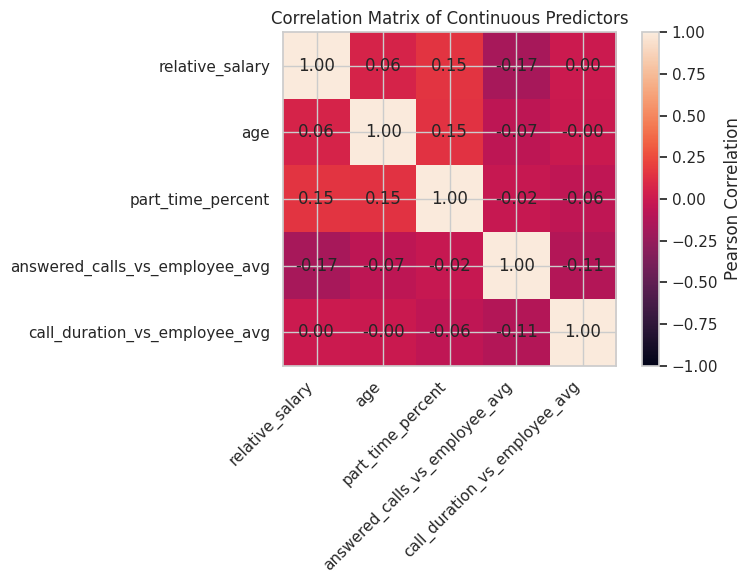

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 8.4.3 Correlation Matrix Plot
# ============================================================

fig, axis = plt.subplots(
    figsize=(8, 6)
)

correlation_image = axis.imshow(
    continuous_correlation_matrix.to_numpy(),
    vmin=-1,
    vmax=1
)

axis.set_xticks(
    range(len(final_continuous_for_correlation))
)

axis.set_yticks(
    range(len(final_continuous_for_correlation))
)

axis.set_xticklabels(
    final_continuous_for_correlation,
    rotation=45,
    ha="right"
)

axis.set_yticklabels(
    final_continuous_for_correlation
)

for row_index in range(
    continuous_correlation_matrix.shape[0]
):

    for column_index in range(
        continuous_correlation_matrix.shape[1]
    ):

        axis.text(
            column_index,
            row_index,
            f"{continuous_correlation_matrix.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center"
        )

axis.set_title(
    "Correlation Matrix of Continuous Predictors"
)

fig.colorbar(
    correlation_image,
    ax=axis,
    label="Pearson Correlation"
)

plt.tight_layout()
plt.show()

8.4.2 ממצאים עיקריים

בדיקת המולטיקולינאריות בוצעה באמצעות חישוב Variance Inflation Factor (VIF) עבור כלל המשתנים שנכללו במודל הסופי.

כל ערכי ה־VIF היו נמוכים מ־5, כאשר הערך הגבוה ביותר היה 4.38 עבור אחת מרמות המשתנה call_center. יתר המשתנים הציגו ערכי VIF נמוכים באופן ניכר, ובפרט כל המשתנים הרציפים הציגו ערכים הקרובים ל־1.

בנוסף, מטריצת המתאמים בין המשתנים הרציפים לא הצביעה על מתאמים חזקים, ולא נמצאו זוגות משתנים עם מתאם מוחלט הגבוה מ־0.70.

לפיכך, לא נמצאה עדות למולטיקולינאריות משמעותית, וכל המשתנים נשמרו במודל הסופי.

### 8.5 בחינת תצפיות משפיעות

בחינת תצפיות משפיעות בוצעה באמצעות ניתוח Case-Deletion. בשל ריבוי קשרים בזמני המעקב הנמדדים בחודשים, ערכי Delta-beta המחושבים באופן מקורב שימשו רק לזיהוי ראשוני של תצפיות מועמדות ולא כקריטריון סופי.

בכל אחד מחמשת מערכי הנתונים זוהו התצפיות בעלות ערכי Delta-beta המוחלטים הגבוהים ביותר. לאחר מכן הותאם המודל מחדש לאחר השמטת כל תצפית מועמדת בנפרד, והשינוי במקדמי המודל הושווה לשגיאות התקן של המודל המקורי.

תצפית סומנה כבעלת השפעה אפשרית כאשר השמטתה גרמה לשינוי מתוקנן מהותי באחד ממקדמי המודל. תצפיות לא הוסרו אוטומטית, אלא שימשו להערכת יציבות הממצאים.

In [ ]:
# ============================================================
# 8.5.1 Exact Case-Deletion Influence Diagnostics
# Across the Five Imputed Datasets
# ============================================================

from lifelines import CoxPHFitter
import numpy as np
import pandas as pd

TOP_CANDIDATES_PER_IMPUTATION = 15
STANDARDIZED_CHANGE_THRESHOLD = 0.50

# ------------------------------------------------------------
# Helper: recreate the exact final-model dataset
# ------------------------------------------------------------

def prepare_final_cox_dataset(dataset):

    X = dataset[
        FINAL_STEPWISE_PREDICTORS
    ].copy()

    X = pd.get_dummies(
        X,
        columns=[
            "children",
            "call_center",
            "family_status"
        ],
        drop_first=True,
        dtype=float
    )

    for column in X.columns:
        X[column] = pd.to_numeric(
            X[column],
            errors="coerce"
        ).astype(float)

    analysis_data = X.copy()

    analysis_data[TIME_COL] = pd.to_numeric(
        dataset[TIME_COL],
        errors="coerce"
    ).astype(float)

    analysis_data[EVENT_COL] = pd.to_numeric(
        dataset[EVENT_COL],
        errors="coerce"
    ).astype(int)

    assert analysis_data.isna().sum().sum() == 0
    assert np.isfinite(
        analysis_data.to_numpy(dtype=float)
    ).all()

    return analysis_data


# ------------------------------------------------------------
# Step 1: use approximate delta-beta only to rank candidates
# ------------------------------------------------------------

candidate_indices_by_imputation = {}

for imputation_number, (model, dataset) in enumerate(
    zip(cox_models_mice, mice_datasets),
    start=1
):

    analysis_data = prepare_final_cox_dataset(
        dataset
    )

    approximate_delta_beta = model.compute_residuals(
        analysis_data,
        kind="delta_beta"
    )

    candidate_scores = (
        approximate_delta_beta
        .abs()
        .max(axis=1)
        .sort_values(ascending=False)
    )

    candidate_indices_by_imputation[
        imputation_number
    ] = candidate_scores.head(
        TOP_CANDIDATES_PER_IMPUTATION
    ).index.tolist()


# ------------------------------------------------------------
# Step 2: exact leave-one-out model refitting
# ------------------------------------------------------------

case_deletion_rows = []

for imputation_number, (original_model, dataset) in enumerate(
    zip(cox_models_mice, mice_datasets),
    start=1
):

    full_data = prepare_final_cox_dataset(
        dataset
    )

    original_coefficients = (
        original_model.params_.copy()
    )

    original_standard_errors = (
        original_model.standard_errors_.copy()
    )

    candidate_indices = (
        candidate_indices_by_imputation[
            imputation_number
        ]
    )

    for observation_index in candidate_indices:

        reduced_data = full_data.drop(
            index=observation_index
        )

        reduced_model = CoxPHFitter()

        reduced_model.fit(
            reduced_data,
            duration_col=TIME_COL,
            event_col=EVENT_COL
        )

        coefficient_change = (
            reduced_model.params_
            - original_coefficients
        )

        standardized_change = (
            coefficient_change.abs()
            / original_standard_errors
        )

        most_affected_term = (
            standardized_change.idxmax()
        )

        maximum_standardized_change = float(
            standardized_change.max()
        )

        case_deletion_rows.append({
            "Imputation": imputation_number,
            "Observation Index": observation_index,
            "Most Affected Model Term": most_affected_term,
            "Original Coefficient": float(
                original_coefficients[
                    most_affected_term
                ]
            ),
            "Coefficient After Deletion": float(
                reduced_model.params_[
                    most_affected_term
                ]
            ),
            "Absolute Coefficient Change": float(
                coefficient_change[
                    most_affected_term
                ]
            ),
            "Maximum Standardized Change": (
                maximum_standardized_change
            ),
            "Potentially Influential": (
                maximum_standardized_change
                >= STANDARDIZED_CHANGE_THRESHOLD
            )
        })

case_deletion_results = pd.DataFrame(
    case_deletion_rows
)

case_deletion_results = (
    case_deletion_results
    .sort_values(
        [
            "Potentially Influential",
            "Maximum Standardized Change"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

display_columns = [
    "Imputation",
    "Observation Index",
    "Most Affected Model Term",
    "Original Coefficient",
    "Coefficient After Deletion",
    "Absolute Coefficient Change",
    "Maximum Standardized Change",
    "Potentially Influential"
]

case_deletion_display = (
    case_deletion_results[
        display_columns
    ]
    .copy()
)

numeric_columns = [
    "Original Coefficient",
    "Coefficient After Deletion",
    "Absolute Coefficient Change",
    "Maximum Standardized Change"
]

case_deletion_display[
    numeric_columns
] = case_deletion_display[
    numeric_columns
].round(6)

display(case_deletion_display)

print(
    "Exact case-deletion diagnostics completed successfully."
)

,Imputation,Observation Index,Most Affected Model Term,Original Coefficient,Coefficient After Deletion,Absolute Coefficient Change,Maximum Standardized Change,Potentially Influential
0,1,413,call_center_2,-1.0399,-0.9536,0.0863,0.5218,True
1,4,413,call_center_2,-1.0034,-0.9184,0.0850,0.5149,True
2,1,1198,relative_salary,-4.4849,-4.5948,-0.1099,0.3307,False
3,1,463,call_duration_vs_employee_avg,0.0012,0.0012,0.0001,0.3302,False
4,2,1035,call_duration_vs_employee_avg,0.0009,0.0009,0.0001,0.3110,False
5,4,463,call_duration_vs_employee_avg,0.0011,0.0011,0.0001,0.3087,False
6,5,714,call_duration_vs_employee_avg,0.0010,0.0010,0.0000,0.2687,False
7,1,460,call_center_2,-1.0399,-0.9998,0.0400,0.2421,False
8,4,460,call_center_2,-1.0034,-0.9637,0.0397,0.2407,False
9,2,463,call_duration_vs_employee_avg,0.0009,0.0009,0.0000,0.2337,False


Exact case-deletion diagnostics completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 8.5.2 Summarize Exact Case-Deletion Results
# ============================================================

case_deletion_summary = pd.DataFrame({
    "Metric": [
        "Candidate observations examined",
        "Maximum standardized coefficient change",
        "Candidates with standardized change >= 0.50",
        "Imputations containing at least one flagged candidate"
    ],
    "Value": [
        len(case_deletion_results),
        case_deletion_results[
            "Maximum Standardized Change"
        ].max(),
        int(
            case_deletion_results[
                "Potentially Influential"
            ].sum()
        ),
        int(
            case_deletion_results.loc[
                case_deletion_results[
                    "Potentially Influential"
                ],
                "Imputation"
            ].nunique()
        )
    ]
})

display(case_deletion_summary)

flagged_case_deletion = (
    case_deletion_results.loc[
        case_deletion_results[
            "Potentially Influential"
        ]
    ]
    .copy()
)

if flagged_case_deletion.empty:

    print(
        "None of the examined observations caused "
        "a standardized coefficient change of 0.50 or more."
    )

else:

    influence_consistency = (
        flagged_case_deletion
        .groupby(
            "Observation Index",
            as_index=False
        )
        .agg(
            Imputations_Flagged=(
                "Imputation",
                "nunique"
            ),
            Maximum_Standardized_Change=(
                "Maximum Standardized Change",
                "max"
            ),
            Most_Frequently_Affected_Term=(
                "Most Affected Model Term",
                lambda values: values.mode().iloc[0]
            )
        )
        .rename(columns={
            "Imputations_Flagged":
                "Imputations Flagged",
            "Maximum_Standardized_Change":
                "Maximum Standardized Change",
            "Most_Frequently_Affected_Term":
                "Most Frequently Affected Term"
        })
        .sort_values(
            [
                "Imputations Flagged",
                "Maximum Standardized Change"
            ],
            ascending=[
                False,
                False
            ]
        )
        .reset_index(drop=True)
    )

    influence_consistency[
        "Maximum Standardized Change"
    ] = influence_consistency[
        "Maximum Standardized Change"
    ].round(6)

    display(influence_consistency)

,Metric,Value
0,Candidate observations examined,75.0000
1,Maximum standardized coefficient change,0.5218
2,Candidates with standardized change >= 0.50,2.0000
3,Imputations containing at least one flagged ca...,2.0000


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Observation Index,Imputations Flagged,Maximum Standardized Change,Most Frequently Affected Term
0,413,2,0.5218,call_center_2


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### ממצאים עיקריים

בחינת תצפיות משפיעות בוצעה באמצעות Case-Deletion עבור 75 תצפיות מועמדות, שנבחרו על בסיס ערכי Delta-beta הגבוהים ביותר בחמשת מערכי הנתונים המושלמים.

רק תצפית אחת, שמספר האינדקס שלה 413, הובילה לשינוי מתוקנן העולה במעט על הסף שנקבע, עם שינוי מרבי של 0.522 בשתי השלמות מתוך חמש. המונח שהושפע ביותר היה אחת מרמות המשתנה `call_center`.

השמטת התצפית לא שינתה את כיוון המקדם ולא הובילה לשינוי מהותי במסקנות המודל. יתר התצפיות שנבדקו הציגו שינויים מתוקננים הנמוכים מהסף.

לפיכך, לא נמצאה עדות לתצפיות בעלות השפעה חריגה ועקבית על אומדני המודל, ולא הוסרו תצפיות מן הניתוח.

### 8.6 ניתוח רגישות: Complete Case לעומת MICE

לצורך בחינת יציבות הממצאים הושוו תוצאות מודל ה־Cox שהתקבלו בניתוח Complete Case לתוצאות המאוחדות שהתקבלו לאחר Multiple Imputation.

ההשוואה בוצעה עבור אותם משתנים שנכללו במודל הסופי שנבחר באמצעות Stepwise. נבחנו מקדמי הרגרסיה, יחסי הסיכון, רווחי הסמך, ערכי ה־p, כיוון ההשפעה והמובהקות הסטטיסטית.

דמיון בין התוצאות מעיד כי השלמת הערכים החסרים לא שינתה באופן מהותי את מסקנות המחקר.

In [ ]:
# ============================================================
# 8.6 Sensitivity Analysis
# Complete Case vs. Multiple Imputation
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Complete Case results
# ------------------------------------------------------------

complete_case_sensitivity = (
    cox_stepwise_model.summary
    .reset_index()
    .rename(columns={
        "covariate": "Variable",
        "coef": "CC Coefficient",
        "exp(coef)": "CC Hazard Ratio",
        "exp(coef) lower 95%": "CC 95% CI Lower",
        "exp(coef) upper 95%": "CC 95% CI Upper",
        "p": "CC P-value"
    })
)

complete_case_sensitivity = complete_case_sensitivity[
    [
        "Variable",
        "CC Coefficient",
        "CC Hazard Ratio",
        "CC 95% CI Lower",
        "CC 95% CI Upper",
        "CC P-value"
    ]
].copy()

# ------------------------------------------------------------
# Pooled MICE results
# ------------------------------------------------------------

mice_sensitivity = pooled_cox_results[
    [
        "Variable",
        "Pooled Coefficient",
        "Hazard Ratio",
        "95% CI Lower",
        "95% CI Upper",
        "P-value"
    ]
].copy()

mice_sensitivity = mice_sensitivity.rename(columns={
    "Pooled Coefficient": "MICE Coefficient",
    "Hazard Ratio": "MICE Hazard Ratio",
    "95% CI Lower": "MICE 95% CI Lower",
    "95% CI Upper": "MICE 95% CI Upper",
    "P-value": "MICE P-value"
})

# ------------------------------------------------------------
# Merge results
# ------------------------------------------------------------

sensitivity_comparison = complete_case_sensitivity.merge(
    mice_sensitivity,
    on="Variable",
    how="outer",
    validate="one_to_one"
)

# ------------------------------------------------------------
# Compare direction and significance
# ------------------------------------------------------------

sensitivity_comparison["CC Direction"] = np.select(
    [
        sensitivity_comparison["CC Coefficient"] > 0,
        sensitivity_comparison["CC Coefficient"] < 0
    ],
    [
        "Positive",
        "Negative"
    ],
    default="Zero"
)

sensitivity_comparison["MICE Direction"] = np.select(
    [
        sensitivity_comparison["MICE Coefficient"] > 0,
        sensitivity_comparison["MICE Coefficient"] < 0
    ],
    [
        "Positive",
        "Negative"
    ],
    default="Zero"
)

sensitivity_comparison["Direction Consistent"] = (
    sensitivity_comparison["CC Direction"]
    == sensitivity_comparison["MICE Direction"]
)

sensitivity_comparison["CC Significant"] = (
    sensitivity_comparison["CC P-value"] < 0.05
)

sensitivity_comparison["MICE Significant"] = (
    sensitivity_comparison["MICE P-value"] < 0.05
)

sensitivity_comparison["Significance Consistent"] = (
    sensitivity_comparison["CC Significant"]
    == sensitivity_comparison["MICE Significant"]
)

# ------------------------------------------------------------
# Absolute and relative coefficient changes
# ------------------------------------------------------------

sensitivity_comparison["Absolute Coefficient Difference"] = (
    sensitivity_comparison["MICE Coefficient"]
    - sensitivity_comparison["CC Coefficient"]
).abs()

sensitivity_comparison["Relative Coefficient Difference (%)"] = (
    sensitivity_comparison[
        "Absolute Coefficient Difference"
    ]
    / sensitivity_comparison[
        "CC Coefficient"
    ].abs()
    * 100
)

# Avoid infinite percentages if a coefficient is zero
sensitivity_comparison[
    "Relative Coefficient Difference (%)"
] = sensitivity_comparison[
    "Relative Coefficient Difference (%)"
].replace(
    [np.inf, -np.inf],
    np.nan
)

# ------------------------------------------------------------
# Sort and format
# ------------------------------------------------------------

sensitivity_comparison = (
    sensitivity_comparison
    .sort_values(
        "MICE P-value"
    )
    .reset_index(drop=True)
)

numeric_columns = [
    "CC Coefficient",
    "CC Hazard Ratio",
    "CC 95% CI Lower",
    "CC 95% CI Upper",
    "CC P-value",
    "MICE Coefficient",
    "MICE Hazard Ratio",
    "MICE 95% CI Lower",
    "MICE 95% CI Upper",
    "MICE P-value",
    "Absolute Coefficient Difference",
    "Relative Coefficient Difference (%)"
]

sensitivity_comparison_display = (
    sensitivity_comparison.copy()
)

sensitivity_comparison_display[
    numeric_columns
] = sensitivity_comparison_display[
    numeric_columns
].round(4)

display(sensitivity_comparison_display)

# ------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------

sensitivity_summary = pd.DataFrame({
    "Metric": [
        "Model terms compared",
        "Terms with consistent direction",
        "Terms with consistent significance",
        "Terms significant in Complete Case",
        "Terms significant after MICE",
        "Terms with changed direction",
        "Terms with changed significance"
    ],
    "Value": [
        len(sensitivity_comparison),
        int(
            sensitivity_comparison[
                "Direction Consistent"
            ].sum()
        ),
        int(
            sensitivity_comparison[
                "Significance Consistent"
            ].sum()
        ),
        int(
            sensitivity_comparison[
                "CC Significant"
            ].sum()
        ),
        int(
            sensitivity_comparison[
                "MICE Significant"
            ].sum()
        ),
        int(
            (~sensitivity_comparison[
                "Direction Consistent"
            ]).sum()
        ),
        int(
            (~sensitivity_comparison[
                "Significance Consistent"
            ]).sum()
        )
    ]
})

display(sensitivity_summary)

print(
    "Sensitivity analysis completed successfully."
)

,Variable,CC Coefficient,CC Hazard Ratio,CC 95% CI Lower,CC 95% CI Upper,CC P-value,MICE Coefficient,MICE Hazard Ratio,MICE 95% CI Lower,MICE 95% CI Upper,MICE P-value,CC Direction,MICE Direction,Direction Consistent,CC Significant,MICE Significant,Significance Consistent,Absolute Coefficient Difference,Relative Coefficient Difference (%)
0,relative_salary,-4.2088,0.0149,0.0068,0.0323,0.0000,-4.4166,0.0121,0.0062,0.0234,0.0000,Negative,Negative,True,True,True,True,0.2078,4.9379
1,call_center_2,-1.0738,0.3417,0.2390,0.4885,0.0000,-1.0298,0.3571,0.2573,0.4956,0.0000,Negative,Negative,True,True,True,True,0.0440,4.1013
2,family_status_1,-0.5065,0.6026,0.4853,0.7483,0.0000,-0.5464,0.5791,0.4837,0.6932,0.0000,Negative,Negative,True,True,True,True,0.0398,7.8632
3,age,-0.0279,0.9724,0.9591,0.9860,0.0001,-0.0350,0.9656,0.9538,0.9775,0.0000,Negative,Negative,True,True,True,True,0.0071,25.2665
4,part_time_percent,0.5108,1.6666,1.2202,2.2764,0.0013,0.6405,1.8974,1.4594,2.4668,0.0000,Positive,Positive,True,True,True,True,0.1297,25.3883
5,answered_calls_vs_employee_avg,0.0013,1.0013,1.0008,1.0017,0.0000,0.0012,1.0012,1.0007,1.0016,0.0000,Positive,Positive,True,True,True,True,0.0001,7.0814
6,call_duration_vs_employee_avg,0.0010,1.0010,1.0006,1.0014,0.0000,0.0010,1.0010,1.0006,1.0014,0.0000,Positive,Positive,True,True,True,True,0.0000,0.1353
7,children_1,-0.4613,0.6305,0.4812,0.8260,0.0008,-0.3983,0.6715,0.5433,0.8299,0.0002,Negative,Negative,True,True,True,True,0.0630,13.6654
8,call_center_3,-0.3009,0.7402,0.5464,1.0027,0.0521,-0.2847,0.7522,0.5776,0.9797,0.0347,Negative,Negative,True,False,True,False,0.0161,5.3672
9,call_center_5,0.2380,1.2686,0.9124,1.7639,0.1571,0.1871,1.2058,0.9018,1.6122,0.2063,Positive,Positive,True,False,False,True,0.0508,21.3638


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Value
0,Model terms compared,13
1,Terms with consistent direction,12
2,Terms with consistent significance,12
3,Terms significant in Complete Case,8
4,Terms significant after MICE,9
5,Terms with changed direction,1
6,Terms with changed significance,1


Sensitivity analysis completed successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### ממצאים עיקריים

ניתוח הרגישות הצביע על יציבות גבוהה של תוצאות המודל בין ניתוח ה־Complete Case לבין הניתוח לאחר Multiple Imputation.

כיוון ההשפעה נשמר ב־12 מתוך 13 מונחי המודל, וסטטוס המובהקות הסטטיסטית נשמר אף הוא ב־12 מתוך 13 המונחים. עבור המשתנים המרכזיים במודל, ובהם שכר יחסי, גיל, אחוז משרה, קיום ילדים, מצב משפחתי ושני מדדי ה־KPI, נשמרו כיוון ההשפעה והמובהקות הסטטיסטית לאחר השלמת הערכים החסרים.

עבור `call_center_3`, כיוון ההשפעה וגודלה נותרו דומים, אך ערך ה־p השתנה מ־0.052 בניתוח ה־Complete Case ל־0.035 לאחר MICE. לפיכך, השינוי משקף בעיקר מעבר קל סביב סף המובהקות של 0.05 ולא שינוי מהותי באומדן האפקט.

עבור `call_center_4` השתנה כיוון המקדם, אולם האפקט לא היה מובהק סטטיסטית בשני הניתוחים ורווחי הסמך כללו את הערך 1. לכן שינוי זה אינו משנה את מסקנות המחקר.

בסך הכול, ממצאי ניתוח הרגישות מצביעים על כך שהשלמת הערכים החסרים לא שינתה באופן מהותי את כיווני ההשפעה או את המסקנות המרכזיות של המודל.

# **שלב 9 — בניית כלי החיזוי הסופי**

## 9. הדגמה יישומית של הפקת תחזיות על תצפיות היסטוריות

בשלב זה הודגם השימוש במודל הסופי על חמש תצפיות היסטוריות שלא שימשו לצורך הדגמת הקוד. עבור כל עובד חושבו הסתברויות עזיבה מצטברות לאחר 6, 12, 18 ו־24 חודשים.

מאחר שהקובץ המשמש להדגמה כולל מידע היסטורי מלא, מועד הייחוס לחישוב השכר היחסי נקבע בהתאם לנתוני התקופה הקיימים בקובץ. בשימוש עתידי על עובדים פעילים יהיה צורך לקבוע את שכר המינימום בהתאם לתאריך החיזוי בפועל.

In [ ]:
# ============================================================
# 9.0 Upload and Prepare Raw Data for Final Prediction
# ============================================================

from google.colab import files
from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Verify that the historical minimum-wage function exists
# ------------------------------------------------------------

if "get_minimum_wage_for_reference_date" not in globals():
    raise RuntimeError(
        "The function get_minimum_wage_for_reference_date "
        "was not found. Run Section 4.2 before Section 9.0."
    )

# ------------------------------------------------------------
# 2. Upload exactly one Excel or CSV file
# ------------------------------------------------------------

print(
    "Please upload one raw prediction file "
    "containing complete employee data."
)

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError(
        "Please upload exactly one file."
    )

uploaded_file_name = list(uploaded.keys())[0]
uploaded_file_path = Path(uploaded_file_name)

# ------------------------------------------------------------
# 3. Load the uploaded file
# ------------------------------------------------------------

if uploaded_file_path.suffix.lower() in [".xlsx", ".xls"]:

    df_prediction_raw = pd.read_excel(
        uploaded_file_path
    )

elif uploaded_file_path.suffix.lower() in [".csv", ".txt"]:

    df_prediction_raw = pd.read_csv(
        uploaded_file_path
    )

else:

    raise ValueError(
        "Supported formats are Excel and CSV only."
    )

print("\nRaw prediction file loaded successfully.")
print(f"File: {uploaded_file_name}")
print(f"Observations: {len(df_prediction_raw):,}")
print(f"Columns: {df_prediction_raw.shape[1]:,}")

# ------------------------------------------------------------
# 4. Required raw columns
# ------------------------------------------------------------

required_raw_columns = [
    "id",
    "status",
    "age",
    "salary_per_hour",
    "bonus_avg",
    "children",
    "call_center",
    "resignation_year",
    "resignation_month",
    "family_status",
    "part_time_percent",
    "answered_calls_employee_avg_3month",
    "answered_calls_employee_avg",
    "call_duration_employee_avg_3month",
    "call_duration_employee_avg"
]

missing_raw_columns = [
    column
    for column in required_raw_columns
    if column not in df_prediction_raw.columns
]

if missing_raw_columns:
    raise ValueError(
        "The uploaded file is missing required columns: "
        f"{missing_raw_columns}"
    )

# ------------------------------------------------------------
# 5. Validate IDs
# ------------------------------------------------------------

if df_prediction_raw["id"].isna().any():
    raise ValueError(
        "The uploaded file contains missing employee IDs."
    )

if df_prediction_raw["id"].duplicated().any():
    duplicate_ids = (
        df_prediction_raw.loc[
            df_prediction_raw["id"].duplicated(
                keep=False
            ),
            "id"
        ]
        .tolist()
    )

    raise ValueError(
        "The uploaded file contains duplicate IDs: "
        f"{duplicate_ids}"
    )

# ------------------------------------------------------------
# 6. Convert required numeric source variables
# ------------------------------------------------------------

numeric_source_columns = [
    "status",
    "age",
    "salary_per_hour",
    "bonus_avg",
    "children",
    "call_center",
    "resignation_year",
    "resignation_month",
    "family_status",
    "part_time_percent",
    "answered_calls_employee_avg_3month",
    "answered_calls_employee_avg",
    "call_duration_employee_avg_3month",
    "call_duration_employee_avg"
]

for column in numeric_source_columns:

    df_prediction_raw[column] = pd.to_numeric(
        df_prediction_raw[column],
        errors="coerce"
    )

missing_numeric_source = (
    df_prediction_raw[
        numeric_source_columns
    ]
    .isna()
    .sum()
)

missing_numeric_source = missing_numeric_source[
    missing_numeric_source > 0
]

if not missing_numeric_source.empty:
    raise ValueError(
        "Missing or non-numeric values were found "
        "in required source variables:\n"
        f"{missing_numeric_source.to_dict()}"
    )

if not np.isfinite(
    df_prediction_raw[
        numeric_source_columns
    ].to_numpy(dtype=float)
).all():
    raise ValueError(
        "At least one source variable contains "
        "an infinite or invalid value."
    )

# ------------------------------------------------------------
# 7. Validate categorical coding
# ------------------------------------------------------------

if not set(
    df_prediction_raw["status"].astype(int).unique()
).issubset({0, 1}):
    raise ValueError(
        "status must contain only 0 or 1."
    )

if not set(
    df_prediction_raw["children"].astype(int).unique()
).issubset({0, 1}):
    raise ValueError(
        "children must contain only 0 or 1."
    )

if not set(
    df_prediction_raw["family_status"].astype(int).unique()
).issubset({0, 1}):
    raise ValueError(
        "family_status must contain only 0 or 1."
    )

valid_call_centers = set(range(1, 8))

observed_call_centers = set(
    df_prediction_raw[
        "call_center"
    ].astype(int).unique()
)

if not observed_call_centers.issubset(
    valid_call_centers
):
    raise ValueError(
        "call_center contains values outside 1–7: "
        f"{sorted(observed_call_centers)}"
    )

# Resignation month is coded 0–11 in the research dataset
resigned_rows = (
    df_prediction_raw["status"].astype(int) == 1
)

observed_resignation_months = set(
    df_prediction_raw.loc[
        resigned_rows,
        "resignation_month"
    ]
    .astype(int)
    .unique()
)

if not observed_resignation_months.issubset(
    set(range(12))
):
    raise ValueError(
        "resignation_month must be coded from "
        "0 (January) to 11 (December)."
    )

# ------------------------------------------------------------
# 8. Calculate monthly salary normalized to full-time work
#
# Same calculation used in Section 4.2:
# hourly salary × 178 hours + average monthly bonus
# ------------------------------------------------------------

df_prediction_raw[
    "monthly_salary_fulltime"
] = (
    df_prediction_raw[
        "salary_per_hour"
    ].astype(float)
    * 178
    + df_prediction_raw[
        "bonus_avg"
    ].astype(float)
)

# ------------------------------------------------------------
# 9. Assign historical minimum wage
#
# Uses exactly the function defined in Section 4.2.
# ------------------------------------------------------------

df_prediction_raw[
    "min_wage_for_period"
] = df_prediction_raw.apply(
    lambda row: get_minimum_wage_for_reference_date(
        status=row["status"],
        resignation_year=row["resignation_year"],
        resignation_month=row["resignation_month"]
    ),
    axis=1
)

if df_prediction_raw[
    "min_wage_for_period"
].isna().any():

    problematic_ids = (
        df_prediction_raw.loc[
            df_prediction_raw[
                "min_wage_for_period"
            ].isna(),
            "id"
        ]
        .tolist()
    )

    raise ValueError(
        "The applicable minimum wage could not be "
        "determined for these IDs: "
        f"{problematic_ids}"
    )

if (
    df_prediction_raw[
        "min_wage_for_period"
    ] <= 0
).any():
    raise ValueError(
        "min_wage_for_period contains zero or "
        "negative values."
    )

# ------------------------------------------------------------
# 10. Calculate relative salary
# ------------------------------------------------------------

df_prediction_raw[
    "relative_salary"
] = (
    df_prediction_raw[
        "monthly_salary_fulltime"
    ]
    / df_prediction_raw[
        "min_wage_for_period"
    ]
)

# ------------------------------------------------------------
# 11. Calculate the final derived KPI predictors
# ------------------------------------------------------------

df_prediction_raw[
    "answered_calls_vs_employee_avg"
] = (
    df_prediction_raw[
        "answered_calls_employee_avg_3month"
    ]
    - df_prediction_raw[
        "answered_calls_employee_avg"
    ]
)

df_prediction_raw[
    "call_duration_vs_employee_avg"
] = (
    df_prediction_raw[
        "call_duration_employee_avg_3month"
    ]
    - df_prediction_raw[
        "call_duration_employee_avg"
    ]
)

# ------------------------------------------------------------
# 12. Create the exact dataset expected by Sections 9.1–9.4
#
# Outcome and leakage variables are deliberately excluded.
# ------------------------------------------------------------

FINAL_RAW_PREDICTION_COLUMNS = [
    "id",
    "relative_salary",
    "children",
    "call_center",
    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg",
    "family_status",
    "age",
    "part_time_percent"
]

df_new = df_prediction_raw[
    FINAL_RAW_PREDICTION_COLUMNS
].copy()

# ------------------------------------------------------------
# 13. Final validation
# ------------------------------------------------------------

for column in FINAL_RAW_PREDICTION_COLUMNS[1:]:

    df_new[column] = pd.to_numeric(
        df_new[column],
        errors="coerce"
    )

missing_final_values = (
    df_new
    .isna()
    .sum()
)

missing_final_values = missing_final_values[
    missing_final_values > 0
]

if not missing_final_values.empty:
    raise ValueError(
        "Missing values remain in the final "
        "prediction dataset:\n"
        f"{missing_final_values.to_dict()}"
    )

if not np.isfinite(
    df_new[
        FINAL_RAW_PREDICTION_COLUMNS[1:]
    ].to_numpy(dtype=float)
).all():
    raise ValueError(
        "The final prediction dataset contains "
        "infinite or invalid values."
    )

if df_new["id"].duplicated().any():
    raise ValueError(
        "Duplicate IDs remain in the final "
        "prediction dataset."
    )

# ------------------------------------------------------------
# 14. Save the prepared prediction file
# ------------------------------------------------------------

PREDICTION_READY_PATH = Path(
    "/content/datatest_prediction_ready.xlsx"
)

df_new.to_excel(
    PREDICTION_READY_PATH,
    index=False
)

# ------------------------------------------------------------
# 15. Display preparation summary
# ------------------------------------------------------------

derived_variable_summary = df_prediction_raw[
    [
        "id",
        "monthly_salary_fulltime",
        "min_wage_for_period",
        "relative_salary",
        "answered_calls_vs_employee_avg",
        "call_duration_vs_employee_avg"
    ]
].copy()

display(
    derived_variable_summary.round(4)
)

print("\nFinal prediction dataset:")
display(df_new.round(4))

print("-" * 60)
print("Section 9.0 completed successfully.")
print(f"Raw observations: {len(df_prediction_raw):,}")
print(f"Prediction-ready observations: {len(df_new):,}")
print("Missing final predictor values: 0")
print(f"Prepared file saved to: {PREDICTION_READY_PATH}")

Please upload one raw prediction file containing complete employee data.


Saving datatest.xlsx to datatest.xlsx

Raw prediction file loaded successfully.
File: datatest.xlsx
Observations: 5
Columns: 34


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,monthly_salary_fulltime,min_wage_for_period,relative_salary,answered_calls_vs_employee_avg,call_duration_vs_employee_avg
0,479,"5,183.3600","5,300.0000",0.9780,251.6496,-8.8095
1,483,"6,507.6731","5,300.0000",1.2279,-28.0942,-25.9636
2,630,"5,071.2200","5,000.0000",1.0142,53.6667,8.6633
3,663,"5,183.3600","5,300.0000",0.9780,-28.4067,-201.2000
4,687,"5,183.3600","5,300.0000",0.9780,72.2778,28.8724



Final prediction dataset:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,relative_salary,children,call_center,answered_calls_vs_employee_avg,call_duration_vs_employee_avg,family_status,age,part_time_percent
0,479,0.9780,0,2,251.6496,-8.8095,0,40,1.0000
1,483,1.2279,1,3,-28.0942,-25.9636,1,45,0.8000
2,630,1.0142,0,7,53.6667,8.6633,0,28,1.0000
3,663,0.9780,0,2,-28.4067,-201.2000,0,27,1.0000
4,687,0.9780,0,4,72.2778,28.8724,0,37,1.0000


------------------------------------------------------------
Section 9.0 completed successfully.
Raw observations: 5
Prediction-ready observations: 5
Missing final predictor values: 0
Prepared file saved to: /content/datatest_prediction_ready.xlsx


In [ ]:
# ============================================================
# 9.1 Final Prediction Pipeline Settings
# Five Cox Models After Multiple Imputation
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

PREDICTION_TIME_POINTS = [6, 12, 18, 24]

FINAL_PREDICTION_PREDICTORS = [
    "relative_salary",
    "children",
    "call_center",
    "answered_calls_vs_employee_avg",
    "call_duration_vs_employee_avg",
    "family_status",
    "age",
    "part_time_percent"
]

FINAL_PREDICTION_CATEGORICAL = [
    "children",
    "call_center",
    "family_status"
]

assert "cox_models_mice" in globals(), (
    "cox_models_mice was not found. "
    "Run Section 7.2.1 first."
)

assert len(cox_models_mice) == 5, (
    "The prediction pipeline requires five fitted Cox models."
)

prediction_model_terms = list(
    cox_models_mice[0].params_.index
)

for model_number, model in enumerate(
    cox_models_mice,
    start=1
):
    assert list(model.params_.index) == prediction_model_terms, (
        f"Model terms differ in Cox model {model_number}."
    )

print("Final predictors:")
print(FINAL_PREDICTION_PREDICTORS)

print("\nEncoded model terms:")
print(prediction_model_terms)

print("\nFive-model prediction setup completed successfully.")

Final predictors:
['relative_salary', 'children', 'call_center', 'answered_calls_vs_employee_avg', 'call_duration_vs_employee_avg', 'family_status', 'age', 'part_time_percent']

Encoded model terms:
['relative_salary', 'answered_calls_vs_employee_avg', 'call_duration_vs_employee_avg', 'age', 'part_time_percent', 'children_1', 'call_center_2', 'call_center_3', 'call_center_4', 'call_center_5', 'call_center_6', 'call_center_7', 'family_status_1']

Five-model prediction setup completed successfully.


In [ ]:
# ============================================================
# 9.2 Prepare New Data for Final Cox Prediction
# ============================================================

def prepare_final_prediction_matrix(
    prediction_df
):
    """
    Prepare a complete predictor matrix with exactly the same
    encoded columns and order used by the five fitted Cox models.
    """

    missing_original_predictors = [
        predictor
        for predictor in FINAL_PREDICTION_PREDICTORS
        if predictor not in prediction_df.columns
    ]

    if missing_original_predictors:
        raise ValueError(
            "The following required predictors are missing: "
            f"{missing_original_predictors}"
        )

    X_prediction = prediction_df[
        FINAL_PREDICTION_PREDICTORS
    ].copy()

    # Convert continuous predictors to numeric
    continuous_prediction_predictors = [
        predictor
        for predictor in FINAL_PREDICTION_PREDICTORS
        if predictor not in FINAL_PREDICTION_CATEGORICAL
    ]

    for column in continuous_prediction_predictors:
        X_prediction[column] = pd.to_numeric(
            X_prediction[column],
            errors="coerce"
        )

    # Dummy encoding with the same reference categories
    X_prediction = pd.get_dummies(
        X_prediction,
        columns=FINAL_PREDICTION_CATEGORICAL,
        drop_first=True,
        dtype=float
    )

    # Add dummy levels absent from the new file
    for model_term in prediction_model_terms:
        if model_term not in X_prediction.columns:
            X_prediction[model_term] = 0.0

    # Reject unexpected categories or columns
    unexpected_columns = [
        column
        for column in X_prediction.columns
        if column not in prediction_model_terms
    ]

    if unexpected_columns:
        raise ValueError(
            "The prediction file contains categories that were "
            "not present in the training model: "
            f"{unexpected_columns}"
        )

    # Exact same column order as training
    X_prediction = X_prediction[
        prediction_model_terms
    ].astype(float)

    X_prediction = X_prediction.replace(
        [np.inf, -np.inf],
        np.nan
    )

    rows_with_missing_predictors = (
        X_prediction.isna().any(axis=1)
    )

    if rows_with_missing_predictors.any():
        missing_rows = X_prediction.index[
            rows_with_missing_predictors
        ].tolist()

        missing_by_column = (
            X_prediction
            .isna()
            .sum()
        )

        missing_by_column = missing_by_column[
            missing_by_column > 0
        ].to_dict()

        raise ValueError(
            "Missing predictor values remain after preparation.\n"
            f"Rows: {missing_rows[:20]}\n"
            f"Missing values by column: {missing_by_column}"
        )

    assert np.isfinite(
        X_prediction.to_numpy(dtype=float)
    ).all()

    return X_prediction

In [ ]:
# ============================================================
# 9.3 Predict Attrition Probabilities
# by 6, 12, 18 and 24 Months
# ============================================================

def predict_attrition_mice_pooled(
    prediction_df,
    id_col="id",
    time_points=PREDICTION_TIME_POINTS
):
    """
    Generate predictions from all five Cox models and average
    the predicted survival probabilities across imputations.
    """

    X_prediction = prepare_final_prediction_matrix(
        prediction_df
    )

    if id_col in prediction_df.columns:
        employee_ids = (
            prediction_df[id_col]
            .astype(str)
            .reset_index(drop=True)
        )
    else:
        employee_ids = pd.Series(
            [
                f"ROW_{row_number + 1}"
                for row_number in range(
                    len(prediction_df)
                )
            ]
        )

    time_points = np.asarray(
        time_points,
        dtype=float
    )

    survival_predictions = []
    partial_hazard_predictions = []

    for imputation_number, model in enumerate(
        cox_models_mice,
        start=1
    ):
        survival = (
            model
            .predict_survival_function(
                X_prediction,
                times=time_points
            )
            .T
        )

        survival.columns = [
            float(time_value)
            for time_value in survival.columns
        ]

        survival_predictions.append(
            survival.reset_index(drop=True)
        )

        partial_hazard = (
            model
            .predict_partial_hazard(
                X_prediction
            )
            .to_numpy(dtype=float)
            .reshape(-1)
        )

        partial_hazard_predictions.append(
            partial_hazard
        )

    # Dimensions:
    # survival array = imputations × employees × time points
    survival_array = np.stack(
        [
            table.to_numpy(dtype=float)
            for table in survival_predictions
        ],
        axis=0
    )

    risk_array = np.stack(
        partial_hazard_predictions,
        axis=0
    )

    pooled_survival = survival_array.mean(
        axis=0
    )

    pooled_attrition_probability = (
        1.0 - pooled_survival
    )

    pooled_risk_score = risk_array.mean(
        axis=0
    )

    # Between-imputation uncertainty in predicted probability
    attrition_probability_sd = (
        1.0 - survival_array
    ).std(
        axis=0,
        ddof=1
    )

    prediction_results = pd.DataFrame({
        "ID": employee_ids,
        "Mean_Risk_Score": pooled_risk_score
    })

    for time_index, time_value in enumerate(
        time_points
    ):
        month_label = int(time_value)

        prediction_results[
            f"Prob_attrition_by_{month_label}m"
        ] = pooled_attrition_probability[
            :,
            time_index
        ]

        prediction_results[
            f"SD_across_imputations_{month_label}m"
        ] = attrition_probability_sd[
            :,
            time_index
        ]

    probability_columns = [
        column
        for column in prediction_results.columns
        if column.startswith("Prob_attrition")
    ]

    assert (
        prediction_results[
            probability_columns
        ]
        .ge(0)
        .all()
        .all()
    )

    assert (
        prediction_results[
            probability_columns
        ]
        .le(1)
        .all()
        .all()
    )

    # Probability of attrition must not decrease as time advances
    probability_values = prediction_results[
        probability_columns
    ].to_numpy(dtype=float)

    assert (
        np.diff(
            probability_values,
            axis=1
        ) >= -1e-10
    ).all(), (
        "At least one predicted cumulative attrition "
        "probability decreases over time."
    )

    return prediction_results

In [ ]:
# ============================================================
# 9.4 Load Prediction File and Save Results
# ============================================================

def load_prediction_file(file_path):

    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(
            f"Prediction file was not found: {file_path}"
        )

    if file_path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(file_path)

    if file_path.suffix.lower() in [".csv", ".txt"]:
        return pd.read_csv(file_path)

    raise ValueError(
        "Supported prediction formats are Excel and CSV."
    )


def predict_attrition_from_file(
    input_path,
    output_path,
    id_col="id",
    time_points=PREDICTION_TIME_POINTS
):

    new_data = load_prediction_file(
        input_path
    )

    predictions = predict_attrition_mice_pooled(
        prediction_df=new_data,
        id_col=id_col,
        time_points=time_points
    )

    output_path = Path(
        output_path
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    predictions.to_excel(
        output_path,
        index=False
    )

    print("Prediction completed successfully.")
    print(f"Input observations: {len(new_data):,}")
    print(f"Predicted observations: {len(predictions):,}")
    print(f"Output saved to: {output_path}")

    display(
        predictions.head()
    )

    return predictions

In [ ]:
# ============================================================
# 9.5 Run Final Prediction
# ============================================================

final_predictions = predict_attrition_from_file(
    input_path=PREDICTION_READY_PATH,
    output_path=(
        "/content/cox_final_attrition_predictions.xlsx"
    ),
    id_col="id",
    time_points=[6, 12, 18, 24]
)

Prediction completed successfully.
Input observations: 5
Predicted observations: 5
Output saved to: /content/cox_final_attrition_predictions.xlsx


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,ID,Mean_Risk_Score,Prob_attrition_by_6m,SD_across_imputations_6m,Prob_attrition_by_12m,SD_across_imputations_12m,Prob_attrition_by_18m,SD_across_imputations_18m,Prob_attrition_by_24m,SD_across_imputations_24m
0,479,2.7291,0.4297,0.0120,0.7981,0.0125,0.9452,0.0063,0.9841,0.0026
1,483,0.1387,0.0282,0.0008,0.0782,0.0023,0.1375,0.0039,0.1903,0.0053
2,630,2.7921,0.4371,0.0016,0.8057,0.0020,0.9490,0.0011,0.9857,0.0004
3,663,2.5562,0.4091,0.0069,0.7768,0.0075,0.9343,0.0040,0.9795,0.0018
4,687,2.2185,0.3665,0.0050,0.7279,0.0066,0.9060,0.0044,0.9657,0.0023
